# Taller de IA · El problema del viajante (TSP)
## A* con MST · Hill Climbing vs. Simulated Annealing · Algoritmo genético · RBFS

**Versión del estudiante — enunciado y pseudocódigo, sin implementaciones.**

**Duración propuesta:** dos sesiones. **Modalidad:** parejas. **Entrega:** este mismo cuaderno, completado con las implementaciones propias, pruebas, figuras, resultados y análisis. El docente puede ajustar plazo y modalidad.

**Pregunta central:** ¿qué se gana y qué se pierde al cambiar garantía de optimalidad por rapidez, diversidad o menor consumo de memoria?

Instancias obligatorias: **att48, berlin52, brazil58 y gr48**. Se trabajará también con subinstancias pequeñas para verificar los métodos exactos. Instancias de ampliación: gr17, burma14 y eil51.

Este cuaderno contiene únicamente celdas Markdown. Los bloques etiquetados como `text` son pseudocódigo: no son Python ni MATLAB y no se ejecutan. El estudiante agregará sus propias celdas de código donde se indique.


**Cómo leer este cuaderno.** El enunciado del profesor está completo y sin cambios. Nuestra solución está debajo de cada sección, siempre después de una celda que dice **SOLUCIÓN · sección N**, y llega hasta donde empieza la siguiente sección del enunciado. Las 12 preguntas de la sección 16 tienen su respuesta justo debajo de cada pregunta.

Integrantes: Santiago Valencia León (C.C. 1032797866) y Juan Manuel Galvis (C.C. 1004520611).

## 1. Punto de partida y lectura crítica

La página [TSP Solve](https://sites.google.com/view/tsp-solve/homepage) presenta A*, Hill Climbing y RBFS en MATLAB. Este taller amplía el alcance con recocido simulado y un algoritmo genético. Los procedimientos que siguen son una formulación didáctica propia; no constituyen una traducción del código MATLAB.

Antes de programar, revise estas dos diferencias:

1. Intercambiar las posiciones de dos ciudades es **swap**. El movimiento **2-opt** elimina dos aristas y reconecta el ciclo invirtiendo un segmento. No son movimientos equivalentes en general.
2. En TSP, llegar a la misma ciudad por rutas parciales diferentes no significa llegar al mismo estado: importa también el conjunto de ciudades pendientes. Las reglas de descarte deben respetar esta información.

La página reporta resultados no óptimos para algunas ejecuciones de su variante denominada A* de grafo. Eso motiva una auditoría de estados y reglas de descarte; no demuestra que A* correctamente formulado pierda su garantía de optimalidad.

**Actividad de lectura:** identifique qué código del sitio realiza swap y explique qué debería cambiar para implementar 2-opt. Examine qué información necesita la clave de un estado de A*. No use los tiempos publicados como objetivos de rendimiento de su implementación.


---
### SOLUCIÓN · sección 1

#### C.1 Lectura crítica de TSP Solve (actividad de la sección 1)

Leímos el código MATLAB de las tres páginas: A*, RBFS y Hill Climbing. No lo reprodujimos ni lo ejecutamos; solo lo leímos. Esto encontramos.

**1. El "2-opt" del Hill Climbing es un swap.** La función `getNextSolution` hace:

```matlab
tempNode = newTour(p1);
newTour(p1) = curState.node(p2);
newTour(p2) = tempNode;
```

Eso **intercambia las ciudades** de las posiciones `p1` y `p2`. El comentario y el texto lo llaman "2-opt neighbours", pero es un swap. Un swap cambia **2 aristas** (y entonces coincide con un 2-opt) solo cuando las posiciones son vecinas o tienen exactamente una ciudad entre ellas, incluido el par que rodea al origen. En los demás pares cambia **4 aristas**, y un 2-opt siempre cambia **2**. Con n = 8 y el origen fijo hay 21 pares de posiciones: 12 cambian 2 aristas (6 vecinas, 5 con una ciudad en medio y 1 alrededor del origen) y 9 cambian 4. Para que fuera 2-opt habría que invertir el tramo entre las dos aristas, por ejemplo con `newTour(p1+1:p2) = flip(newTour(p1+1:p2))` (en E.1 lo comprobamos con código). Además, el ciclo acepta mejoras **dentro** del mismo recorrido del vecindario. No es "mejor mejora" sino una mezcla de primera mejora con barrido completo.

**2. La clave de estado del A\* "de grafo" es la ciudad.** Las listas `open` y `closed` se buscan con `ismember(nodelist(i).name, {closed.name})`: dos rutas parciales que terminan en la misma ciudad se tratan como **el mismo estado**, aunque les falten ciudades distintas. Luego decide con comparaciones de costo y **profundidad** (`s.depth > s_inClosed.depth`), que tampoco identifican el estado. Con esa regla se pueden descartar prefijos de la ruta óptima. Esto es **coherente con** lo que reporta la página: el óptimo solo desde 8 de los 48 orígenes de att48, y entre 10648 y 10795 en el resto. La página no da la causa y no reprodujimos su código MATLAB, así que no podemos afirmar que esta sea la explicación. **La clave correcta es `(última ciudad, conjunto de pendientes, cerrado)`**, la de la sección 5. En D.5 usamos una regla simplificada parecida (`key_mode="city_depth"`, no es la de TSP Solve) y nuestro A* también pierde el óptimo.

**3. Otros detalles del código:**

- En la versión de árbol y en RBFS, la `f` es `node.cost = node.h_n + node.g_n - node.depth`: le **resta la profundidad**. Eso ya no es $g+h$. Además, `isGoal` devuelve `solution.cost = node.cost`, así que el costo reportado queda corrido en $n-1$.
- En RBFS, `suc = nodelist(i); suc.cost = max(...)` modifica una **copia**, porque en MATLAB las estructuras se copian por valor. Por eso el `max` con la `f` del padre nunca se guarda en `nodelist`.
- La sección de código "A* (tree search)" llama a `RBFS(...)`: es una copia del código de RBFS.

**Qué debería tener la clave de un estado de A\*:** la ciudad actual, el **conjunto** de ciudades pendientes y si el ciclo ya se cerró, con el origen fijo. Dos nodos con la misma clave tienen las mismas continuaciones posibles. Por eso, entre ellos, basta quedarse con el de menor $g$. Esa es la única fusión segura.

No usamos los tiempos publicados como meta: son de otro lenguaje, otra máquina y otro código.

## 2. Objetivos y reglas del trabajo

Al finalizar, deberá poder:

- Modelar el TSP como búsqueda de rutas parciales y como optimización de permutaciones completas.
- Construir y justificar una heurística basada en árbol de expansión mínima (MST).
- Implementar A*, RBFS, Hill Climbing, Simulated Annealing y un algoritmo genético con operadores válidos para permutaciones.
- Diseñar experimentos reproducibles y distinguir solución válida, mejor solución observada y optimalidad demostrada.
- Interpretar convergencia, brecha al óptimo, memoria y costo computacional.

**Implementación:** escriba los cinco algoritmos desde cero. Puede usar herramientas para arreglos, gráficas, tablas, lectura de archivos y medición. Se permite `tsplib95` para cargar datos y obtener pesos oficiales. Implemente el MST mediante Prim o Kruskal; no delegue las búsquedas ni la optimización a un solver, SimpleAI, DEAP o una biblioteca equivalente en la comparación principal.

Los nombres sugeridos de componentes e identificadores están en inglés; las explicaciones y conclusiones se entregan en español. Toda ayuda externa deberá declararse. Cada integrante debe poder explicar y modificar su implementación durante la sustentación.


---
### SOLUCIÓN · sección 2

**Dónde se ve cada objetivo.**

| Objetivo | Dónde está |
|---|---|
| Rutas parciales y permutaciones completas | C.2 (solución de 5) y E.1 (solución de 9) |
| Heurística MST y su justificación | C.3, C.4 y C.8 (soluciones de 6, 6.1 y 13) |
| Los cinco algoritmos | A\* (D.1), RBFS (D.2), HC (E.2), SA (E.4), GA (F.2) |
| Experimentos reproducibles; solución válida, mejor observada y óptimo demostrado | A.1 (estados `OPTIMAL`, `NOT_CERTIFIED`, `NO_TOUR`) y G.1 a G.4 |
| Convergencia, gap, memoria y costo | G.4 a G.7 y las preguntas de la sección 16 |

**Cómo cumplimos las reglas.**

- **Los cinco algoritmos son nuestros**, escritos desde cero en este cuaderno. No usamos solvers, SimpleAI, DEAP ni bibliotecas parecidas.
- **El MST es nuestro, con Prim** (C.3). También escribimos un Kruskal, pero solo para comprobar que Prim da el árbol correcto (C.8).
- **Herramientas:** `numpy` para arreglos, `pandas` para tablas, `matplotlib` para gráficas, `time` y `tracemalloc` para medir, y `tsplib95` solo para leer los archivos y obtener los pesos oficiales (B). Las versiones están en la tabla de entorno, al comienzo de la solución de 3.1.
- **Idioma:** el código y los identificadores van en inglés (`astar`, `hill_climbing`, `RunResult`); las explicaciones y conclusiones, en español.
- **Ayuda externa:** usamos Claude (Anthropic) como herramienta de apoyo para consultar conceptos y documentación, y como apoyo en la implementación, la depuración y la redacción. Consultamos el cuaderno de TSP de Peter Norvig como ejemplo de 2-opt y de dibujo de rutas, sin copiar su código. Están en las referencias (H.4).

## 3. Banco de problemas TSPLIB

| Instancia | Ciudades | Tipo de pesos | Óptimo oficial del ciclo | Papel en el taller |
|---|---:|---|---:|---|
| att48 | 48 | ATT: distancia pseudoeuclidiana | 10628 | Detectar errores de distancia y redondeo |
| berlin52 | 52 | EUC_2D: distancia euclidiana entera | 7542 | Relacionar rutas con una representación geométrica |
| brazil58 | 58 | EXPLICIT: pesos de una matriz | 25395 | Separar optimización de coordenadas |
| gr48 | 48 | EXPLICIT: pesos de una matriz | 5046 | Comparar dos problemas del mismo tamaño y estructura diferente |
| gr17 · ampliación | 17 | EXPLICIT | 2085 | Exploración exacta intermedia, bajo límites |
| burma14 · ampliación | 14 | GEO | 3323 | Estudiar un tipo de distancia adicional |
| eil51 · ampliación | 51 | EUC_2D | 426 | Generalización de métodos aproximados |

Fuentes: [documentación TSPLIB](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [óptimos oficiales](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [repositorio oficial de archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html).

Los valores son unidades del problema, no necesariamente kilómetros. Para las cuatro instancias obligatorias use los archivos TSP, no archivos homónimos de VRP. Descomprima los `.tsp.gz` antes de leerlos. El cuaderno proporciona enlaces; no contiene los archivos de datos.

**Descargas:** [att48](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/att48.tsp.gz) · [berlin52](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/berlin52.tsp.gz) · [brazil58](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/brazil58.tsp.gz) · [gr48](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/gr48.tsp.gz).


### 3.1. Preparación y auditoría de los datos

Lea `NAME`, `TYPE`, `DIMENSION`, `EDGE_WEIGHT_TYPE` y, cuando exista, `EDGE_WEIGHT_FORMAT`. Reconstruya una matriz simétrica de costos `D`. No presuponga que la numeración de nodos coincide con las posiciones de una lista: conserve una correspondencia explícita entre identificadores y posiciones.

Se recomienda obtener cada peso mediante la interfaz de `tsplib95`, que distingue pesos explícitos y funciones de distancia. La biblioteca no incluye las instancias. Consulte su [documentación de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html).

```text
PROCEDURE LoadInstance(file)
    problem ← leer archivo TSPLIB descomprimido
    nodeIds ← lista ordenada de identificadores reales
    PARA cada par de posiciones i, j
        D[i,j] ← peso oficial entre nodeIds[i] y nodeIds[j]
    verificar dimensión, simetría, diagonal cero y pesos no negativos
    devolver metadatos, nodeIds, D y datos de dibujo disponibles
```

**Entregue:** una ficha por instancia, tres pesos calculados o consultados manualmente y una comprobación automática independiente del costo de una ruta. Si usa un archivo `.opt.tour` oficial disponible, verifique su validez y costo; no lo use como población inicial ni como ruta inicial.

En problemas EXPLICIT, los datos de dibujo, si existen, sirven para visualizar, no para recalcular pesos. Si no hay coordenadas, use una matriz de calor y un dibujo circular de la ruta, etiquetado como disposición esquemática.


In [1]:
!pip install -q tsplib95


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


---
### SOLUCIÓN · sección 3.1

In [2]:
import collections
import heapq
import itertools
import math
import multiprocessing as mp
import os
import platform
import random
try:
    import resource   # Linux/macOS only (process RSS in G.7)
except ImportError:
    resource = None
import statistics
import sys
import time
import tracemalloc
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tsplib95
from IPython.display import Image, display
from matplotlib import animation

assert tsplib95.__version__ == "0.7.1", "the notebook was run with tsplib95 0.7.1"
print(f"Librerías cargadas: numpy {np.__version__}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}, tsplib95 {tsplib95.__version__}")

Librerías cargadas: numpy 2.5.4, pandas 3.0.6, matplotlib 3.11.2, tsplib95 0.7.1


In [3]:
DATA = Path("data")
INF = math.inf
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def parallel_map(func, jobs, processes=None):
    """Run func(*job) for every job; fork workers when the platform allows it, same results either way."""
    jobs = list(jobs)
    try:
        ctx = mp.get_context("fork")
    except ValueError:
        return [func(*job) for job in jobs]
    with ctx.Pool(processes) as pool:
        return pool.starmap(func, jobs, chunksize=1)


def cpu_name():
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or "unknown"


env = {
    "CPU": f"{cpu_name()} ({os.cpu_count()} hilos)",
    "Sistema operativo": platform.platform(),
    "Python": sys.version.split()[0],
    "Entorno": "Jupyter (kernel local, .venv)",
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "tsplib95": tsplib95.__version__,
}
display(pd.Series(env, name="valor").to_frame())

,valor
CPU,AMD Ryzen AI 9 365 w/ Radeon 880M (20 hilos)
Sistema operativo,Linux-7.2.10-arch1-1-x86_64-with-glibc2.44
Python,3.14.8
Entorno,"Jupyter (kernel local, .venv)"
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
tsplib95,0.7.1


Los archivos están en la carpeta `data/`. El script `data/download.sh` los vuelve a descargar del repositorio oficial de TSPLIB y los descomprime. Bajamos las 4 instancias obligatorias, las 3 de ampliación y las rutas óptimas oficiales (`.opt.tour`) que existen: att48, berlin52, gr48 y eil51. El servidor tiene `eil51.opt.tour` aunque el índice no lo lista. brazil58 no tiene `.opt.tour` publicado.

**Idea de la lectura.** `tsplib95` interpreta cada tipo de peso (ATT, EUC_2D, GEO y matrices EXPLICIT en varios formatos). Pedimos cada peso con `get_weight` y armamos una matriz `D` de posiciones `0..n-1`. La lista `node_ids` guarda qué identificador real de TSPLIB hay en cada posición, así que nunca suponemos que "nodo 1 = posición 1". El origen fijo es la posición 0, que es el identificador más pequeño. El lector lee `NAME`, `TYPE`, `DIMENSION`, `EDGE_WEIGHT_TYPE` y, si existe, `EDGE_WEIGHT_FORMAT`, y exige `TYPE = TSP` para no confundir el archivo con uno de VRP.

In [4]:
OPTIMA = {"att48": 10628, "berlin52": 7542, "brazil58": 25395, "gr48": 5046,
          "gr17": 2085, "burma14": 3323, "eil51": 426}
MANDATORY = ["att48", "berlin52", "brazil58", "gr48"]


@dataclass
class TSPInstance:
    name: str
    weight_type: str
    weight_format: object
    node_ids: list
    D: np.ndarray
    coords: object = None          # array (n, 2) for drawing, or None
    optimum: object = None         # official optimum of the full cycle, if known
    subset: str = "full"
    comment: str = ""

    def __post_init__(self):
        self.n = len(self.node_ids)
        self.W = self.D.tolist()   # plain lists: faster than numpy for scalar lookups in the solvers

    def subproblem(self, k):
        """First k identifiers in sorted order with the original weights (induced subproblem)."""
        coords = None if self.coords is None else self.coords[:k]
        return TSPInstance(self.name, self.weight_type, self.weight_format, self.node_ids[:k],
                           self.D[:k, :k].copy(), coords, None, f"k={k}", self.comment)


def load_instance(name):
    problem = tsplib95.load(DATA / f"{name}.tsp")
    assert problem.type == "TSP", f"{name} is {problem.type}, not a TSP file"
    lib_ids = sorted(problem.get_nodes())
    # tsplib95 numbers EXPLICIT matrices from 0, while TSPLIB files (and .opt.tour) number cities from 1
    ids = [i + 1 for i in lib_ids] if lib_ids[0] == 0 else lib_ids
    D = np.array([[problem.get_weight(a, b) if a != b else 0 for b in lib_ids] for a in lib_ids], dtype=np.int64)
    assert D.shape == (problem.dimension, problem.dimension), "dimension mismatch"
    assert (D == D.T).all(), "matrix is not symmetric"
    assert (np.diag(D) == 0).all() and (D >= 0).all(), "bad diagonal or negative weight"
    assert ((D + np.eye(len(ids), dtype=np.int64)) > 0).all(), "two different cities at distance 0"
    coords = None
    if problem.node_coords:
        coords = np.array([problem.node_coords[i] for i in lib_ids], dtype=float)
    elif problem.display_data:
        coords = np.array([problem.display_data[i] for i in lib_ids], dtype=float)
    inst = TSPInstance(name, problem.edge_weight_type, problem.edge_weight_format or None, ids, D,
                       coords, OPTIMA.get(name), "full", problem.comment or "")
    inst.lib_ids = lib_ids
    inst.file_name, inst.file_type = problem.name, problem.type
    assert inst.file_name == name, f"NAME {inst.file_name} does not match file {name}"
    return inst


t0 = time.perf_counter()
INSTANCES = {name: load_instance(name) for name in MANDATORY + ["gr17", "burma14", "eil51"]}
print(f"carga y auditoría de las 7 instancias: {time.perf_counter() - t0:.2f} s (no entra en ningún tiempo medido)")

cards = pd.DataFrame([{
    "instancia": inst.name, "NAME": inst.file_name, "TYPE": inst.file_type, "ciudades": inst.n, "EDGE_WEIGHT_TYPE": inst.weight_type,
    "EDGE_WEIGHT_FORMAT": inst.weight_format or "-", "coordenadas": "sí" if inst.coords is not None else "no",
    "peso mín": int(inst.D[inst.D > 0].min()), "peso máx": int(inst.D.max()),
    "óptimo oficial": inst.optimum, "comentario": inst.comment,
} for inst in INSTANCES.values()])
cards

carga y auditoría de las 7 instancias: 0.02 s (no entra en ningún tiempo medido)


,instancia,NAME,TYPE,ciudades,EDGE_WEIGHT_TYPE,EDGE_WEIGHT_FORMAT,coordenadas,peso mín,peso máx,óptimo oficial,comentario
0,att48,att48,TSP,48,ATT,-,sí,42,2662,10628,48 capitals of the US (Padberg/Rinaldi)
1,berlin52,berlin52,TSP,52,EUC_2D,-,sí,15,1716,7542,52 locations in Berlin (Groetschel)
2,brazil58,brazil58,TSP,58,EXPLICIT,UPPER_ROW,no,72,8700,25395,58 cities in Brazil (Ferreira)
3,gr48,gr48,TSP,48,EXPLICIT,LOWER_DIAG_ROW,no,21,1083,5046,48-city problem (Groetschel)
4,gr17,gr17,TSP,17,EXPLICIT,LOWER_DIAG_ROW,no,27,745,2085,17-city problem (Groetschel)
5,burma14,burma14,TSP,14,GEO,FUNCTION,sí,19,1261,3323,14-Staedte in Burma (Zaw Win)
6,eil51,eil51,TSP,51,EUC_2D,-,sí,2,86,426,51-city problem (Christofides/Eilon)


**Una trampa de numeración.** En las instancias EXPLICIT (gr48, brazil58, gr17), `tsplib95` numera las ciudades **desde 0**. Los archivos de TSPLIB y los `.opt.tour` las numeran **desde 1**. Al principio pedimos `get_weight(1, 2)` en gr48 esperando el peso entre las ciudades 1 y 2 (593) y obtuvimos 258, que es el peso entre las ciudades **2 y 3**. Con la ruta oficial el error salta enseguida: `trace_tours` falla porque la ciudad 48 "no existe". Es lo que advierte la sección 3.1. Por eso el lector guarda dos listas: `node_ids`, con los identificadores oficiales de TSPLIB, y `lib_ids`, con los que usa la biblioteca.

**Fichas.** Las 4 instancias obligatorias pasan la auditoría del lector: `TYPE` igual a `TSP`, dimensión correcta, matriz simétrica, diagonal cero, sin pesos negativos y sin dos ciudades distintas a distancia 0. brazil58 y gr48 **no traen coordenadas**, solo la matriz. Por eso las dibujamos con un esquema circular y una matriz de calor (más abajo).

En burma14 (tipo GEO) encontramos un detalle: la fórmula GEO de TSPLIB da **1, no 0**, para la distancia de una ciudad a sí misma, por el `+ 1.0` del final de la fórmula. El lector pone la diagonal en 0 a mano. La diagonal nunca se usa en una ruta, pero sin ese ajuste fallaría la auditoría de "diagonal cero".

#### B.2 Costo de una ruta y verificación independiente

Una ruta es una lista de **posiciones** que empieza en el origen (posición 0) y no lo repite al final: el regreso se suma aparte. `tour_cost` es la **única** función de costo del cuaderno. Todos los algoritmos la usan, o usan un delta que se valida contra ella.

Para verificarla de forma independiente usamos `problem.trace_tours` de `tsplib95`. Esa función recibe identificadores reales y calcula el costo con su propio código, sin pasar por nuestra matriz.

In [5]:
def is_valid_tour(tour, n, start=0):
    return tour is not None and len(tour) == n and tour[0] == start and sorted(tour) == list(range(n))


def tour_cost(W, tour):
    total = W[tour[-1]][tour[0]]       # closing edge back to the origin
    for a, b in zip(tour, tour[1:]):
        total += W[a][b]
    return total


def read_opt_tour(inst):
    path = DATA / f"{inst.name}.opt.tour"
    if not path.exists():
        return None
    ids = tsplib95.load(path).tours[0]
    pos = {node: i for i, node in enumerate(inst.node_ids)}
    tour = [pos[node] for node in ids]
    k = tour.index(0)
    return tour[k:] + tour[:k]          # rotate so the fixed origin is first


rng = random.Random(2026)
rows = []
for name in MANDATORY + ["eil51"]:
    inst = INSTANCES[name]
    problem = tsplib95.load(DATA / f"{name}.tsp")
    opt = read_opt_tour(inst)
    if opt is not None:
        assert is_valid_tour(opt, inst.n)
        independent = problem.trace_tours([[inst.lib_ids[p] for p in opt]])[0]
        rows.append((name, ".opt.tour oficial", tour_cost(inst.W, opt), independent, inst.optimum))
    for t in range(3):
        tour = [0] + rng.sample(range(1, inst.n), inst.n - 1)
        independent = problem.trace_tours([[inst.lib_ids[p] for p in tour]])[0]
        rows.append((name, f"aleatoria {t + 1}", tour_cost(inst.W, tour), independent, None))
check = pd.DataFrame(rows, columns=["instancia", "ruta", "tour_cost", "tsplib95.trace_tours", "óptimo oficial"])
assert (check["tour_cost"] == check["tsplib95.trace_tours"]).all()
display(check)

,instancia,ruta,tour_cost,tsplib95.trace_tours,óptimo oficial
0,att48,.opt.tour oficial,10628,10628,10628.0
1,att48,aleatoria 1,45920,45920,NaN
2,att48,aleatoria 2,49620,49620,NaN
3,att48,aleatoria 3,50614,50614,NaN
4,berlin52,.opt.tour oficial,7542,7542,7542.0
5,berlin52,aleatoria 1,28145,28145,NaN
6,berlin52,aleatoria 2,28519,28519,NaN
7,berlin52,aleatoria 3,31995,31995,NaN
8,brazil58,aleatoria 1,116277,116277,NaN
9,brazil58,aleatoria 2,122919,122919,NaN


**Lo que encontramos (B.2):**

- Nuestro costo coincide con el de `tsplib95` en todas las rutas.
- Las rutas `.opt.tour` dan exactamente el óptimo oficial: **10628, 7542, 5046 y 426** (att48, berlin52, gr48 y eil51). Esto confirma que los pesos son los oficiales y que el ciclo se cierra bien.
- Usamos las rutas oficiales solo aquí, como prueba. Nunca las usamos como ruta inicial ni como población inicial.

**¿Por qué una ruta "mejor que el óptimo" obliga a revisar todo antes de celebrar?** El óptimo oficial está demostrado, así que nadie puede bajarlo. Si un algoritmo da menos, el error es nuestro. Hay tres sospechosos, y la FAQ oficial de TSPLIB describe errores de este tipo (distancias en punto flotante, cálculo GEO equivocado, coordenadas de dibujo usadas como si fueran las de las distancias).

1. **La distancia está mal.** Por ejemplo, usar en att48 la distancia euclidiana común: según B.1, las distancias salen unas 3.16 veces más grandes. Otro caso es redondear con `round()` de Python, que lleva los empates al par. En estas instancias no hay empates, pero lo comprobamos en B.1 porque otras podrían tenerlos.
2. **Falta el cierre del ciclo.** Si no se suma el regreso al origen, el "costo" es el de un camino abierto y sale más barato.
3. **La ruta no es válida.** Si omite una ciudad, puede salir más corta que el óptimo. Si repite una, el costo ya no es el de un ciclo del problema.

Por eso nuestro protocolo se detiene si un gap sale negativo (lo comprobamos en G).

#### B.4 Cómo se ven las instancias

att48 y berlin52 tienen coordenadas y se dibujan en el plano. brazil58 y gr48 solo tienen matriz, así que usamos una **matriz de calor**. Más adelante dibujamos sus rutas en una **disposición circular esquemática**, que no representa la geografía real.

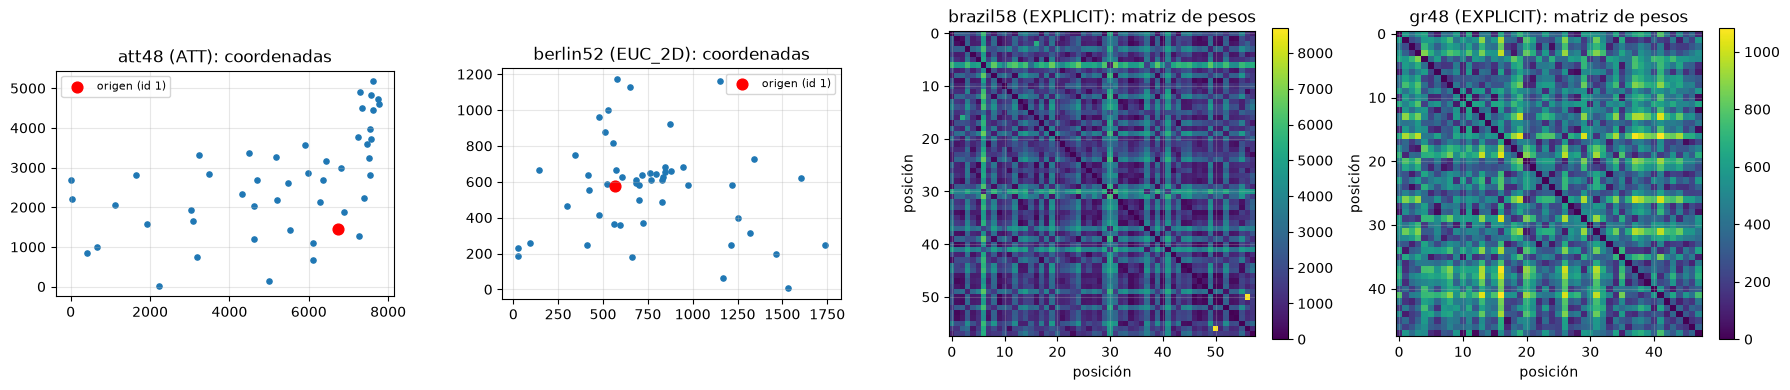

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, name in zip(axes[:2], ["att48", "berlin52"]):
    inst = INSTANCES[name]
    ax.scatter(inst.coords[:, 0], inst.coords[:, 1], s=14)
    ax.scatter(*inst.coords[0], s=60, c="red", label="origen (id %d)" % inst.node_ids[0])
    ax.set_title(f"{name} ({inst.weight_type}): coordenadas")
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
for ax, name in zip(axes[2:], ["brazil58", "gr48"]):
    inst = INSTANCES[name]
    im = ax.imshow(inst.D, cmap="viridis")
    ax.set_title(f"{name} ({inst.weight_type}): matriz de pesos")
    ax.set_xlabel("posición")
    ax.set_ylabel("posición")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### 3.2. Dos reglas de distancia que deben comprender

Para berlin52 (EUC_2D), con $r=\sqrt{(x_i-x_j)^2+(y_i-y_j)^2}$:

$$d(i,j)=\lfloor r+0.5\rfloor.$$

Para att48 (ATT):

$$r=\sqrt{\frac{(x_i-x_j)^2+(y_i-y_j)^2}{10}},\qquad t=\lfloor r+0.5\rfloor,$$

$$d(i,j)=\begin{cases}t+1&\text{si }t<r,\\t&\text{en otro caso.}\end{cases}$$

Para brazil58 y gr48 se utilizan los pesos del archivo, respetando su formato matricial. No reemplace esos pesos por distancias euclidianas. Estas reglas corresponden a la especificación TSPLIB; no aplique el redondeo de empates de un lenguaje sin comprobarlo.

**Ejercicio:** calcule un peso ATT y uno EUC_2D a mano y compárelos con el lector. Explique por qué una ruta aparentemente mejor que el óptimo oficial obliga primero a revisar distancias, cierre del ciclo y validez. La [FAQ oficial](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html) documenta errores frecuentes de este tipo.


---
### SOLUCIÓN · sección 3.2

#### B.1 Pesos a mano (ejercicio de la sección 3.2)

**ATT, att48, ciudades 1 y 2.** Coordenadas $(6734, 1453)$ y $(2233, 10)$.

$$\Delta x = 4501,\quad \Delta y = 1443,\quad \Delta x^2 + \Delta y^2 = 20\,259\,001 + 2\,082\,249 = 22\,341\,250$$

$$r = \sqrt{22\,341\,250 / 10} = \sqrt{2\,234\,125} \approx 1494.699,\qquad t = \lfloor 1494.699 + 0.5 \rfloor = 1495$$

Como $t = 1495$ **no** es menor que $r = 1494.699$, entonces $d = t = 1495$.

**EUC_2D, berlin52, ciudades 1 y 2.** Coordenadas $(565, 575)$ y $(25, 185)$.

$$r = \sqrt{540^2 + 390^2} = \sqrt{291\,600 + 152\,100} = \sqrt{443\,700} \approx 666.108,\qquad d = \lfloor 666.108 + 0.5 \rfloor = 666$$

**EXPLICIT, gr48, ciudades 1 y 2.** El formato es `LOWER_DIAG_ROW`: el archivo da la mitad de abajo de la matriz, fila por fila, con la diagonal incluida. La fila 1 es solo `0`. La fila 2 es `593 0`. Por lo tanto $d(1,2) = 593$, sin ninguna fórmula: no se calcula nada a partir de coordenadas.

**ATT, att48, ciudades 1 y 5,** donde sí se suma el 1. Coordenadas $(6734, 1453)$ y $(3082, 1644)$: $r = \sqrt{(3652^2 + 191^2)/10} = \sqrt{1\,337\,358.5} \approx 1156.442$, $t = \lfloor 1156.942 \rfloor = 1156$. Como $1156 < 1156.442$, $d = t + 1 = 1157$. En resumen, ATT funciona como un **techo**: el +1 aparece cuando el redondeo baja, es decir, cuando la parte decimal de $r$ es menor que 0.5. En el par 1 y 2 la parte decimal era 0.699, el redondeo subió y no hubo +1.

La celda de abajo compara estos valores con el lector. Además:

- compara la matriz completa con nuestra propia implementación de las fórmulas ATT y EUC_2D;
- compara gr48, brazil58 y gr17 con un lector propio de los formatos `LOWER_DIAG_ROW` y `UPPER_ROW`, que no usa `tsplib95`;
- cuenta los pares donde `round(r)` de Python (que redondea los empates al par) difiere de `floor(r + 0.5)`. En estas instancias no hay empates, pero hay que comprobarlo.

In [7]:
def att_distance(p, q):
    r = math.sqrt(((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2) / 10.0)
    t = int(math.floor(r + 0.5))
    return t + 1 if t < r else t


def euc2d_distance(p, q):
    return int(math.floor(math.sqrt((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2) + 0.5))


att, berlin, gr48 = INSTANCES["att48"], INSTANCES["berlin52"], INSTANCES["gr48"]
hand = pd.DataFrame([
    ("att48", "1-2", "ATT", 1495, att.D[0, 1]),
    ("att48", "1-5", "ATT", 1157, att.D[0, 4]),
    ("berlin52", "1-2", "EUC_2D", 666, berlin.D[0, 1]),
    ("gr48", "1-2", "EXPLICIT", 593, gr48.D[0, 1]),
], columns=["instancia", "par", "regla", "a mano", "lector"])
display(hand)
assert (hand["a mano"] == hand["lector"]).all()

for inst, formula in [(att, att_distance), (berlin, euc2d_distance), (INSTANCES["eil51"], euc2d_distance)]:
    mine = np.array([[formula(p, q) if i != j else 0 for j, q in enumerate(inst.coords)]
                     for i, p in enumerate(inst.coords)])
    assert (mine == inst.D).all(), inst.name
    print(f"{inst.name}: nuestra fórmula coincide con tsplib95 en los {inst.n * inst.n} pesos")


def parse_explicit(name):
    """Own reader for the two EXPLICIT formats we use; independent from tsplib95."""
    text = (DATA / f"{name}.tsp").read_text()
    header, _, body = text.partition("EDGE_WEIGHT_SECTION")
    n = int(header.split("DIMENSION")[1].split(":")[1].split()[0])
    fmt = header.split("EDGE_WEIGHT_FORMAT")[1].split(":")[1].split()[0]
    nums = iter(int(x) for x in body.replace("EOF", "").split())
    M = np.zeros((n, n), dtype=np.int64)
    for i in range(n):
        cols = range(i + 1) if fmt == "LOWER_DIAG_ROW" else range(i + 1, n)
        for j in cols:
            M[i, j] = M[j, i] = next(nums)
    assert next(nums, None) is None, "numbers left over"
    return M


for name in ["gr48", "brazil58", "gr17"]:
    assert (parse_explicit(name) == INSTANCES[name].D).all(), name
    print(f"{name}: nuestro lector de {INSTANCES[name].weight_format} coincide con tsplib95")

# When does ATT add the +1?  Count it over all pairs of att48.
plus_one = sum(1 for i in range(att.n) for j in range(i + 1, att.n)
               if att_distance(att.coords[i], att.coords[j]) != math.floor(math.sqrt(
                   ((att.coords[i] - att.coords[j]) ** 2).sum() / 10) + 0.5))
print(f"att48: el +1 de ATT se aplica en {plus_one} de {att.n * (att.n - 1) // 2} pares")

naive = sum(math.sqrt(((att.coords[i] - att.coords[j]) ** 2).sum()) for i in range(att.n) for j in range(i + 1, att.n))
print(f"att48 con distancia euclidiana común (sin /10) sería unas {naive / att.D[np.triu_indices(att.n, 1)].sum():.2f} veces más grande")

# round() in Python rounds ties to even; count pairs where it would differ from floor(r + 0.5)
for inst, scale in [(att, 10.0), (berlin, 1.0), (INSTANCES["eil51"], 1.0)]:
    rs = [math.sqrt(((inst.coords[i] - inst.coords[j]) ** 2).sum() / scale)
          for i in range(inst.n) for j in range(i + 1, inst.n)]
    ties = sum(round(r) != math.floor(r + 0.5) for r in rs)
    print(f"{inst.name}: pares donde round(r) difiere de floor(r + 0.5): {ties} de {inst.n * (inst.n - 1) // 2}")

,instancia,par,regla,a mano,lector
0,att48,1-2,ATT,1495,1495
1,att48,1-5,ATT,1157,1157
2,berlin52,1-2,EUC_2D,666,666
3,gr48,1-2,EXPLICIT,593,593


att48: nuestra fórmula coincide con tsplib95 en los 2304 pesos
berlin52: nuestra fórmula coincide con tsplib95 en los 2704 pesos
eil51: nuestra fórmula coincide con tsplib95 en los 2601 pesos
gr48: nuestro lector de LOWER_DIAG_ROW coincide con tsplib95
brazil58: nuestro lector de UPPER_ROW coincide con tsplib95
gr17: nuestro lector de LOWER_DIAG_ROW coincide con tsplib95
att48: el +1 de ATT se aplica en 588 de 1128 pares
att48 con distancia euclidiana común (sin /10) sería unas 3.16 veces más grande
att48: pares donde round(r) difiere de floor(r + 0.5): 0 de 1128
berlin52: pares donde round(r) difiere de floor(r + 0.5): 0 de 1326
eil51: pares donde round(r) difiere de floor(r + 0.5): 0 de 1275


## 4. Modelo común y arquitectura de su solución

Sea $V$ el conjunto de ciudades y $s$ una ciudad inicial fija. Una ruta completa es una permutación $\pi=(s,\pi_1,\ldots,\pi_{n-1})$. El origen no se repite en la representación; el costo incluye el regreso:

$$C(\pi)=\sum_{i=0}^{n-2}d(\pi_i,\pi_{i+1})+d(\pi_{n-1},s).$$

| Componente sugerido | Responsabilidad | Evidencia exigida |
|---|---|---|
| `TSPInstance` | Pesos, metadatos e identificadores | Fichas y auditoría |
| `Tour` | Permutación, validez y costo | Casos de cierre y duplicados |
| `SearchNode` | Estado parcial, costo y reconstrucción | Traza de búsqueda |
| `MSTHeuristic` | MST y conexiones de extremos | Justificación y casos frontera |
| `AStarSolver`, `RBFSSolver` | Búsqueda de rutas parciales | Pruebas exactas pequeñas |
| `HillClimbingSolver`, `AnnealingSolver`, `GeneticSolver` | Optimización de rutas completas | Curvas y repeticiones |
| `ExperimentRunner`, `RunResult` | Presupuestos, semillas y medición | Tablas reproducibles |

Puede seguir esta estructura orientada a objetos o módulos con responsabilidades equivalentes. No duplique la lógica de costo en cada algoritmo.

**Contrato de salida:** instancia, algoritmo, parámetros, semilla, ruta válida o ausencia de ruta, costo, tiempo, memoria máxima, motivo de parada y condición de optimalidad. Una ruta inicial de respaldo se identifica como tal; no cuenta como una ruta descubierta por A* o RBFS.


---
### SOLUCIÓN · sección 4

#### A.1 Presupuestos, medición y contrato de salida

Todas las ejecuciones usan las mismas dos piezas.

- **`Meter`** mide tiempo y memoria y corta la ejecución cuando se acaba el presupuesto. El tiempo es `time.perf_counter` y no incluye la carga de datos ni las gráficas. La memoria es la **memoria adicional del solver**: el pico de `tracemalloc` menos lo que ya estaba asignado al empezar. `tracemalloc` solo ve las asignaciones de Python, no la memoria total del proceso; esa la reportamos aparte (al final de G). Las revisiones son así: A* y RBFS comprueban las expansiones y el tiempo en cada expansión, y la memoria cada 256 expansiones. HC, SA y GA comprueban las evaluaciones antes de cada una y el tiempo cada 1024 evaluaciones. Medir con `tracemalloc` hace todo más lento; en G medimos cuánto.
- **`RunResult`** es el contrato de salida de la sección 4: instancia, algoritmo, parámetros, semilla, ruta o ausencia de ruta, costo, gap, tiempo, memoria, contadores, motivo de parada y estado de optimalidad.

No usamos ruta de respaldo. Si A* o RBFS se interrumpen, el resultado es `NO_TOUR` y no cuenta como ruta. La ruta inicial compartida de HC y SA es su punto de partida, no una ruta de A* ni de RBFS. La única excepción es la ampliación D.9, donde A* recibe una ruta del vecino más cercano como cota superior: si se corta, devuelve esa ruta marcada como `NOT_CERTIFIED`, identificada como la cota recibida y no como una ruta descubierta por A*.

Motivos de parada: `GOAL` (A* o RBFS cerraron un ciclo), `EXHAUSTED`, `LOCAL_OPTIMUM` (HC), `TMIN` (SA se enfrió), y las interrupciones `TIME`, `EXPANSIONS`, `MEMORY`, `EVALUATIONS`. Estados de optimalidad: `OPTIMAL` (solo A* y RBFS terminados), `NOT_CERTIFIED` (hay ruta pero no prueba) y `NO_TOUR`.

In [8]:
EXACT_BUDGET = dict(seconds=30.0, expansions=100_000, memory_mib=256.0)
INTERRUPTIONS = {"TIME", "EXPANSIONS", "MEMORY", "EVALUATIONS"}


class Interrupted(Exception):
    def __init__(self, reason):
        super().__init__(reason)
        self.reason = reason


class Meter:
    """Wall time plus the solver's extra Python memory (tracemalloc peak over the starting baseline)."""

    def __init__(self, seconds=INF, expansions=None, evaluations=None, memory_mib=None):
        self.seconds, self.expansions, self.evaluations, self.memory_mib = seconds, expansions, evaluations, memory_mib
        self._own_tracing = not tracemalloc.is_tracing()
        if self._own_tracing:
            tracemalloc.start()
        tracemalloc.reset_peak()
        self.base = tracemalloc.get_traced_memory()[0]
        self.t0 = time.perf_counter()

    def elapsed(self):
        return time.perf_counter() - self.t0

    def peak_mib(self):
        return max(0, tracemalloc.get_traced_memory()[1] - self.base) / 2**20

    def check_search(self, expanded):
        if self.expansions is not None and expanded >= self.expansions:
            raise Interrupted("EXPANSIONS")
        if self.elapsed() >= self.seconds:
            raise Interrupted("TIME")
        if self.memory_mib is not None and expanded % 256 == 0 and self.peak_mib() >= self.memory_mib:
            raise Interrupted("MEMORY")

    def out_of_evaluations(self, evaluations, needed=1):
        """True when `needed` more evaluations would exceed the budget, or time ran out (checked every 1024)."""
        if self.evaluations is not None and evaluations + needed > self.evaluations:
            self.reason = "EVALUATIONS"
            return True
        if evaluations % 1024 == 0 and self.elapsed() >= self.seconds:
            self.reason = "TIME"
            return True
        return False

    def finish(self):
        elapsed, peak = self.elapsed(), self.peak_mib()
        if self._own_tracing:
            tracemalloc.stop()
        return elapsed, peak


@dataclass
class RunResult:
    instance: str
    subset: str
    algorithm: str
    seed: object
    parameters: dict
    tour: object
    cost: object
    gap_percent: object
    elapsed_seconds: float
    peak_memory_mib: float
    stop_reason: str
    optimality_status: str
    candidate_evaluations: object = None
    expanded: object = None
    generated: object = None
    mst_calls: object = None
    frontier_peak: object = None
    stale: object = None
    regenerations: object = None
    calls: object = None
    max_depth: object = None
    history: list = field(default_factory=list, repr=False)
    extra: dict = field(default_factory=dict, repr=False)

    def row(self):
        d = {k: v for k, v in self.__dict__.items() if k not in ("history", "extra", "tour")}
        d["parameters"] = ", ".join(f"{k}={v}" for k, v in self.parameters.items())
        return d


def gap_percent(cost, reference):
    if cost is None or reference is None:
        return None
    return 100.0 * (cost - reference) / reference


_chk = Meter(**EXACT_BUDGET)
_chk_list = list(range(200_000))   # about 7.6 MiB of Python ints, so the meter has something to see
_chk_seconds, _chk_mib = _chk.finish()
del _chk_list
print(f"Meter (lista de 200 000 enteros): tiempo={_chk_seconds:.4f} s, memoria={_chk_mib:.1f} MiB;gap_percent(7600, 7542)={gap_percent(7600, 7542):.3f}% con presupuesto {EXACT_BUDGET}")

Meter (lista de 200 000 enteros): tiempo=0.0483 s, memoria=7.6 MiB;gap_percent(7600, 7542)=0.769% con presupuesto {'seconds': 30.0, 'expansions': 100000, 'memory_mib': 256.0}


## 5. Rutas parciales para A* y RBFS

Un nodo conserva `last`, `remaining`, `g`, `parent` y `closed`. `g` mide solamente aristas ya recorridas. `closed` distingue el regreso final al origen.

- Raíz: `last = s`, `remaining = V − {s}`, `g = 0`, `closed = false`.
- Extensión: ir desde `last` a una ciudad pendiente y eliminarla de `remaining`.
- Si no quedan pendientes, generar un único sucesor que regresa a `s`, añade ese costo y marca `closed = true`.
- Meta: `closed = true`. Una ruta que ya visitó todas las ciudades pero aún no regresó no es meta.

```text
PROCEDURE Successors(node)
    SI node.closed: devolver lista vacía
    SI node.remaining está vacío
        devolver único nodo cerrado con g = node.g + D[node.last,s]
    successors ← lista vacía
    PARA cada v en node.remaining
        child.last ← v
        child.remaining ← node.remaining − {v}
        child.g ← node.g + D[node.last,v]
        child.parent ← node; child.closed ← false
        añadir child a successors
    devolver successors
```

**Clave de estado:** `(last, remaining, closed)`, con el mismo origen fijo. Dos nodos con esta clave comparten las mismas continuaciones; puede conservarse el de menor `g`. La ciudad, la profundidad o la cantidad de pendientes por sí solas no identifican el estado.

**Actividad:** construya dos rutas parciales que terminen en la misma ciudad y tengan conjuntos pendientes distintos. Muestre por qué fusionarlas puede eliminar la ruta óptima.


---
### SOLUCIÓN · sección 5

#### C.2 Modelo de búsqueda: rutas parciales (sección 5)

Un nodo guarda `last`, `remaining`, `g`, `closed`, `parent` y `depth`. Guardamos las ciudades pendientes como una **máscara de bits**: el bit $v$ vale 1 si la ciudad $v$ falta. Así la clave `(last, remaining, closed)` no cambia y sirve como llave de un diccionario. Generamos los sucesores en orden creciente de posición, y por eso todo es determinista.

In [9]:
@dataclass(frozen=True, slots=True)
class SearchNode:
    last: int
    remaining: int        # bitmask over positions still to visit
    g: int
    closed: bool
    parent: object
    depth: int


def bits(mask):
    """Positions set in mask, in increasing order (deterministic successor order)."""
    while mask:
        low = mask & -mask
        yield low.bit_length() - 1
        mask ^= low


def root_node(n, start=0):
    return SearchNode(start, ((1 << n) - 1) & ~(1 << start), 0, False, None, 0)


def successors(W, node, start=0, close_cycle=True):
    if node.closed:
        return []
    if node.remaining == 0:
        if not close_cycle:
            return []
        return [SearchNode(start, 0, node.g + W[node.last][start], True, node, node.depth + 1)]
    return [SearchNode(v, node.remaining & ~(1 << v), node.g + W[node.last][v], False, node, node.depth + 1)
            for v in bits(node.remaining)]


def state_key(node):
    return (node.last, node.remaining, node.closed)


def reconstruct(node):
    path = []
    while node is not None:
        path.append(node.last)
        node = node.parent
    path.reverse()
    return path[:-1] if len(path) > 1 and path[-1] == path[0] else path   # drop the closing return


_chk = INSTANCES["berlin52"].subproblem(5)
_chk_kids = successors(_chk.W, root_node(_chk.n))
print(f"berlin52 k=5: la raíz tiene {len(_chk_kids)} sucesores; primer hijo state_key={state_key(_chk_kids[0])}, g={_chk_kids[0].g}")

berlin52 k=5: la raíz tiene 4 sucesores; primer hijo state_key=(1, 28, False), g=666


La actividad de las dos rutas parciales (C.7) usa el oráculo exacto de la sección 6.2, así que está al final de la solución de 6.2.

## 6. Heurística MST: definición y demostración

Para una ciudad actual $v$ y pendientes $U$:

$$h(v,U)=\begin{cases}
0&\text{si el ciclo está cerrado},\\
d(v,s)&\text{si }U=\varnothing\text{ y falta cerrar},\\
\operatorname{MST}(U)+\min_{u\in U}d(v,u)+\min_{u\in U}d(u,s)&\text{en otro caso.}
\end{cases}$$

Se define $\operatorname{MST}(\varnothing)=\operatorname{MST}(\{u\})=0$. Para un solo pendiente la fórmula calcula exactamente el costo restante. En la raíz, las dos conexiones mínimas pueden seleccionar la misma ciudad; es una relajación válida aunque dé una cota menos ajustada.

**Idea de admisibilidad:** toda continuación conecta la ciudad actual con el primer pendiente, recorre todos los pendientes y termina conectando el último con el origen. Las aristas internas forman un camino que abarca $U$, cuyo costo es al menos el del MST. Cada arista de conexión cuesta al menos el mínimo correspondiente. La suma no sobreestima el costo restante. No se necesita desigualdad triangular para esta justificación en el TSP simétrico de pesos no negativos.

**Tareas:** redacte la demostración con sus palabras; examine además la desigualdad de consistencia $h(n)\leq c(n,n')+h(n')$ para las transiciones del modelo. A* deberá permitir mejores valores de `g` aunque su análisis de consistencia esté incompleto.

**MST no es una ruta TSP:** no impone grado dos ni produce un ciclo que visite una sola vez cada ciudad.


---
### SOLUCIÓN · sección 6

#### C.4 Por qué la cota MST es admisible (con nuestras palabras)

Estamos en la ciudad $v$, nos faltan las ciudades $U$ y el origen es $s$. Tomemos **cualquier** forma de terminar el ciclo: $v \to u_1 \to u_2 \to \dots \to u_m \to s$, donde $u_1, \dots, u_m$ son las ciudades de $U$ en algún orden. Su costo tiene tres partes:

1. **La primera arista** $v \to u_1$. Como $u_1$ está en $U$, cuesta al menos $\min_{u\in U} d(v,u)$.
2. **El camino interno** $u_1 \to \dots \to u_m$. Es un camino que toca todas las ciudades de $U$ sin ciclos. Un camino que cubre $U$ es un **árbol generador** de $U$. El MST es el árbol generador más barato, así que este camino cuesta al menos $\operatorname{MST}(U)$.
3. **La última arista** $u_m \to s$. Cuesta al menos $\min_{u\in U} d(u,s)$.

Sumando, cualquier continuación cuesta al menos $h(v,U)$. Entonces $h$ **nunca sobreestima** lo que falta: es admisible.

Casos frontera:

- Si queda un solo pendiente $u$: $\operatorname{MST}=0$ y $h = d(v,u) + d(u,s)$, que es **exactamente** lo que falta.
- Si no queda ninguno pero falta cerrar: $h = d(v,s)$, también exacto.
- Si el ciclo está cerrado: $h=0$.

No usamos la desigualdad triangular en ningún paso. Sí usamos dos hechos. Primero, el TSP es simétrico: el camino $u_1 \to \dots \to u_m$ se puede leer como un árbol no dirigido, y la arista $u_m \to s$ pesa lo mismo que $s \to u_m$. Segundo, un camino que cubre $U$ es un árbol generador de $U$. Los pesos no negativos no hacen falta para esta cota; hacen falta para que A* sea óptimo.

En la raíz los dos mínimos pueden escoger **la misma ciudad**. Por ejemplo, en el microcaso los dos escogen E. Con dos o más pendientes, una ruta real no puede usar la misma ciudad como primera y como última del tramo, así que la cota queda floja, pero sigue siendo válida.

**Consistencia.** La cota también es consistente. Sea $n'$ el hijo que va de $v$ a $u \in U$, con $U' = U - \{u\}$ y costo de paso $c = d(v,u)$. Hay que ver que $h(v,U) \le d(v,u) + h(u,U')$, comparando término a término:

- $\operatorname{MST}(U) \le \operatorname{MST}(U') + \min_{w\in U'} d(u,w)$. Al MST de $U'$ le pegamos $u$ con su arista más barata y obtenemos un árbol que conecta $U$. El MST de $U$ no puede ser más caro que ese árbol.
- $\min_{w\in U} d(v,w) \le d(v,u)$, porque $u \in U$.
- $\min_{w\in U} d(w,s) \le \min_{w\in U'} d(w,s)$, porque $U' \subseteq U$: tomar el mínimo sobre más ciudades nunca da más.

Al sumar las tres desigualdades sale $h(n) \le c + h(n')$. Para el último paso ($U'=\varnothing$) y para el cierre, la cota es exacta y la igualdad se cumple. Lo comprobamos además con código en todas las transiciones de casos pequeños, en C.8 (sección 13).

Nuestro A* **no depende** de la consistencia: reabre un estado si llega con mejor $g$ (`bestG`), como pide la sección 7.

**Un MST no es una ruta.** El MST no exige grado 2: una ciudad puede tener 3 ramas o más. Tampoco cierra un ciclo. En el microcaso, el MST de $\{B,C,D,E\}$ es $B{-}C$, $C{-}D$, $D{-}E$ y cuesta 7. Una ruta no puede "recorrerlo" gratis: para pasar de una rama a otra tiene que volver por aristas ya usadas, y eso cuesta. La relajación pierde justo eso: el **orden** y la obligación de **entrar y salir** de cada ciudad una sola vez.

### 6.1. Pseudocódigo de Prim y de la cota

```text
PROCEDURE MSTCost(U)
    SI |U| ≤ 1: devolver 0
    connected ← {una ciudad de U}; total ← 0
    MIENTRAS connected ≠ U
        (a,b) ← arista de menor peso con a en connected y b en U − connected
        total ← total + D[a,b]
        añadir b a connected
    devolver total

PROCEDURE Heuristic(node)
    SI node.closed: devolver 0
    U ← node.remaining
    SI U está vacío: devolver D[node.last,s]
    devolver MSTCost(U) + mínimo D[node.last,u] para u en U
                       + mínimo D[u,s] para u en U
```

El primer bloque expresa Prim de forma conceptual. Una implementación que vuelve a explorar todas las aristas de corte en cada paso puede costar $O(|U|^3)$. Para obtener $O(|U|^2)$ con matriz densa, mantenga para cada ciudad pendiente su mejor costo de conexión y actualícelo al añadir un vértice.

**Experimento opcional:** almacenar `MSTCost(U)` por conjunto de pendientes. Compare tiempo y memoria con y sin caché. Una caché sin límite puede crecer exponencialmente; no utilice una caché global ilimitada al presentar RBFS como búsqueda de memoria reducida.


---
### SOLUCIÓN · sección 6.1

#### C.3 Prim en $O(|U|^2)$ y la cota MST (secciones 6 y 6.1)

`prim` guarda, para cada ciudad que todavía no está en el árbol, su conexión más barata al árbol. En cada paso agrega la más barata y actualiza las demás en una sola pasada. Son $|U|$ pasos de $O(|U|)$, o sea $O(|U|^2)$, como pide 6.1.

`MSTHeuristic` aplica la fórmula de la sección 6 y cuenta las llamadas al MST. La opción `use_cache` guarda el MST de cada conjunto de pendientes. Es el experimento opcional de 6.1 y solo lo usamos en D.6. Con `kind="zero"` la heurística vale siempre 0 y A* se vuelve búsqueda de costo uniforme.

In [10]:
def prim(W, nodes):
    """MST of the complete graph on `nodes` with O(k^2) Prim: keep each outside node's cheapest link."""
    nodes = list(nodes)
    if len(nodes) <= 1:
        return 0, []
    best = {v: (W[nodes[0]][v], nodes[0]) for v in nodes[1:]}
    total, edges = 0, []
    while best:
        v = min(best, key=lambda u: best[u][0])
        cost, parent = best.pop(v)
        total += cost
        edges.append((parent, v))
        for u in best:
            if W[v][u] < best[u][0]:
                best[u] = (W[v][u], v)
    return total, edges


class MSTHeuristic:
    """h(v, U) of section 6. kind='zero' gives h = 0 (uniform-cost search) with the same interface."""

    def __init__(self, W, start=0, kind="mst", close_cycle=True, use_cache=False):
        self.W, self.start, self.kind, self.close_cycle = W, start, kind, close_cycle
        self.cache = {} if use_cache else None
        self.mst_calls = 0
        self.cache_hits = 0

    def mst(self, mask):
        if self.cache is not None and mask in self.cache:
            self.cache_hits += 1
            return self.cache[mask]
        self.mst_calls += 1
        value = prim(self.W, bits(mask))[0]
        if self.cache is not None:
            self.cache[mask] = value
        return value

    def __call__(self, node):
        if node.closed or self.kind == "zero":
            return 0
        W, s = self.W, self.start
        if node.remaining == 0:
            return W[node.last][s] if self.close_cycle else 0
        U = list(bits(node.remaining))
        h = self.mst(node.remaining) + min(W[node.last][u] for u in U)
        if self.close_cycle:
            h += min(W[u][s] for u in U)
        return h


_chk = INSTANCES["berlin52"].subproblem(5)
print(f"berlin52 k=5: MST de las 5 ciudades = {prim(_chk.W, range(5))[0]}, h(raíz) = {MSTHeuristic(_chk.W)(root_node(_chk.n))}")

berlin52 k=5: MST de las 5 ciudades = 1325, h(raíz) = 1824


El experimento opcional de la caché necesita A\*, así que está en la solución de la sección 7 (D.7).

### 6.2. Microcaso manual: primero comprender, luego programar

Use esta matriz simétrica de cinco ciudades:

| D | A | B | C | D | E |
|---|---:|---:|---:|---:|---:|
| A | 0 | 4 | 6 | 7 | 3 |
| B | 4 | 0 | 2 | 5 | 6 |
| C | 6 | 2 | 0 | 3 | 4 |
| D | 7 | 5 | 3 | 0 | 2 |
| E | 3 | 6 | 4 | 2 | 0 |

Para el prefijo A → B: $g=4$, $U=\{C,D,E\}$, MST de costo $5$, conexión B → U de costo $2$ y U → A de costo $3$. Así, $h=10$ y $f=g+h=14$.

**Complete sin código:**

1. Calcule $g$, $h$ y $f$ de todos los hijos de la raíz A.
2. Muestre el primer empate de la frontera y proponga una regla determinista para resolverlo.
3. Calcule la cota para un solo pendiente y para ningún pendiente.
4. Trace los primeros cambios de límite de RBFS.
5. Evalúe un swap y un 2-opt sobre una misma ruta; explique la diferencia.

Luego enumere las rutas del microcaso con su propio verificador y úselo como oráculo de las implementaciones.


---
### SOLUCIÓN · sección 6.2

#### C.5 Microcaso manual (sección 6.2)

Lo resolvimos primero a mano. La celda de código de más abajo solo **verifica** estas cuentas.

Matriz: A-B 4, A-C 6, A-D 7, A-E 3, B-C 2, B-D 5, B-E 6, C-D 3, C-E 4, D-E 2. Origen A.

**Raíz.** $U=\{B,C,D,E\}$. El MST es B-C (2), D-E (2) y C-D (3), y cuesta 7. Conexión desde A: $\min = 3$ (E). Regreso a A: $\min = 3$ (E otra vez). $h = 7+3+3 = 13$, $f = 13$.

**1. Hijos de la raíz:**

| Hijo | $g$ | $U$ | MST de $U$ | conexión desde el hijo | regreso a A | $h$ | $f$ |
|---|---:|---|---|---:|---:|---:|---:|
| A->B | 4 | C, D, E | C-D 3 + D-E 2 = 5 | B-C = 2 | E-A = 3 | 10 | **14** |
| A->C | 6 | B, D, E | D-E 2 + B-D 5 = 7 | C-B = 2 | E-A = 3 | 12 | 18 |
| A->D | 7 | B, C, E | B-C 2 + C-E 4 = 6 | D-E = 2 | E-A = 3 | 11 | 18 |
| A->E | 3 | B, C, D | B-C 2 + C-D 3 = 5 | E-D = 2 | B-A = 4 | 11 | **14** |

**2. Primer empate y regla de desempate.** El primer empate aparece en la frontera inicial: A->B y A->E tienen $f = 14$. Nuestra regla, que usan A* y RBFS, es:

1. menor $f$;
2. si empatan, el nodo **más profundo**, porque está más cerca de cerrar un ciclo;
3. si siguen empatados, el que se generó primero (orden creciente de ciudad).

Como A->B y A->E tienen la misma profundidad, gana **A->B** por orden de generación. Al expandir A->B aparecen sus hijos:

| Hijo de A->B | $g$ | $U$ | $h$ | $f$ |
|---|---:|---|---:|---:|
| A->B->C | 6 | D, E | MST 2 + C-D 3 + E-A 3 = 8 | **14** |
| A->B->D | 9 | C, E | MST 4 + D-E 2 + E-A 3 = 9 | 18 |
| A->B->E | 10 | C, D | MST 3 + E-D 2 + C-A 6 = 11 | 21 |

Ahora empatan A->E ($f=14$, profundidad 1) y A->B->C ($f=14$, profundidad 2). Gana A->B->C por ser más profundo. Siguiendo así, A* expande A, AB, ABC, ABCD y ABCDE, y saca el nodo cerrado con **costo 14**.

**3. Cota con un pendiente y sin pendientes.**

- Prefijo A->B->C->D ($g=9$), $U=\{E\}$: $h = 0 + d(D,E) + d(E,A) = 2+3 = 5$. Es exactamente lo que falta: $f = 14$.
- Prefijo A->B->C->D->E ($g=11$), sin pendientes pero sin cerrar: $h = d(E,A) = 3$, $f = 14$.
- Al cerrar: $g = 14$, $h = 0$.

**4. Primeros cambios de límite en RBFS.** Se llama RBFS(A, límite $=\infty$). Los hijos quedan con $f$ = máx($g+h$, 13): B 14, E 14, C 18, D 18.

- El mejor es B (14). La alternativa es E (14), así que se baja a B con límite $\min(\infty, 14) = 14$.
- En B, los hijos son C 14, D 18, E 21. El mejor es C (14) y la alternativa 18; el nuevo límite es $\min(14, 18) = 14$.
- En A->B->C, los hijos son D 14 y E 19. Para A->B->C->E: $g = 10$, $h = 0 + d(E,D) + d(D,A) = 2 + 7 = 9$, $f = 19$. Se baja a D con límite 14.
- Luego A->B->C->D->E (14) y el cierre (14 ≤ 14): **encontrado**.

El límite pasa de $\infty$ a 14 y se queda ahí. En el microcaso RBFS **no retrocede**, porque la cota es exacta en el camino óptimo. Si la $f$ hubiera subido por encima de 14, RBFS habría guardado ese valor en B y habría vuelto a E. En D.3 mostramos una traza de 6 ciudades donde sí retrocede.

**5. Swap contra 2-opt sobre la misma ruta** A-B-C-D-E-A (costo 14):

- **2-opt** con $i=0$, $j=2$: quita A-B y C-D, pone A-C y B-D, invierte el tramo B C. Queda **A-C-B-D-E**, con $\Delta = 6+5-4-3 = +4$, o sea 18.
- **Swap** de las posiciones 1 y 3 (B y D): queda **A-D-C-B-E**, con costo $7+3+2+6+3 = 21$. Si se mira bien, eso es invertir el tramo B C D, es decir, el 2-opt con $i=0$, $j=3$: $\Delta = d(A,D)+d(B,E)-d(A,B)-d(D,E) = 7+6-4-2 = +7$.

En un ciclo de 5 ciudades **todo swap coincide con algún 2-opt**. Las dos ciudades intercambiadas quedan a distancia 1 o 2 en el ciclo, contando por el lado más corto, y el swap equivale a invertir el tramo entre ellas. Con 6 ciudades o más ya no pasa siempre: un swap de posiciones lejanas cambia **4** aristas y un 2-opt cambia **2**. En E.1 lo comprobamos enumerando todos los swaps.

In [11]:
MICRO = np.array([[0, 4, 6, 7, 3],
                  [4, 0, 2, 5, 6],
                  [6, 2, 0, 3, 4],
                  [7, 5, 3, 0, 2],
                  [3, 6, 4, 2, 0]])
micro = TSPInstance("micro", "EXPLICIT", "FULL_MATRIX", list("ABCDE"), MICRO)
LET = "ABCDE"
name_of = lambda path: "-".join(LET[p] for p in path)

H = MSTHeuristic(micro.W)
root = root_node(5)
assert H(root) == 13
rows = []
for child in successors(micro.W, root):
    rows.append((name_of(reconstruct(child)), child.g, H(child), child.g + H(child)))
    for grandchild in (successors(micro.W, child) if child.last == 1 else []):
        rows.append((name_of(reconstruct(grandchild)), grandchild.g, H(grandchild), grandchild.g + H(grandchild)))
table = pd.DataFrame(rows, columns=["prefijo", "g", "h", "f"])
display(table)
assert table.set_index("prefijo")["f"].to_dict() == {"A-B": 14, "A-B-C": 14, "A-B-D": 18, "A-B-E": 21,
                                                     "A-C": 18, "A-D": 18, "A-E": 14}
# one pending and no pending
n_abcd = successors(micro.W, successors(micro.W, successors(micro.W, root)[0])[0])[0]
assert name_of(reconstruct(n_abcd)) == "A-B-C-D" and H(n_abcd) == 5
n_abcde = successors(micro.W, n_abcd)[0]
assert H(n_abcde) == 3 and H(successors(micro.W, n_abcde)[0]) == 0
print("microcaso: g, h y f de la tabla manual verificados")

,prefijo,g,h,f
0,A-B,4,10,14
1,A-B-C,6,8,14
2,A-B-D,9,9,18
3,A-B-E,10,11,21
4,A-C,6,12,18
5,A-D,7,11,18
6,A-E,3,11,14


microcaso: g, h y f de la tabla manual verificados


#### C.6 Oráculos exactos para pruebas pequeñas

Para probar A* y RBFS necesitamos conocer la respuesta correcta por otro camino. Usamos dos oráculos que no dependen de la búsqueda:

- **`brute_force`** prueba todas las permutaciones, $(k-1)!$ rutas. Lo usamos hasta $k=10$, que son 362 880 rutas.
- **`held_karp`** es programación dinámica sobre subconjuntos, $O(k^2 2^k)$. Calcula el óptimo de otra forma y llega hasta $k=12$ en poco tiempo.

Solo los usamos para probar, nunca dentro de la comparación. Con el microcaso listamos además sus 24 rutas (12 ciclos en 2 sentidos) con su costo. Esa tabla es el oráculo del microcaso para las pruebas de A* y RBFS.

In [12]:
def brute_force(inst, start=0):
    others = [v for v in range(inst.n) if v != start]
    best_cost, best_tour = INF, None
    for perm in itertools.permutations(others):
        tour = [start, *perm]
        c = tour_cost(inst.W, tour)
        if c < best_cost:
            best_cost, best_tour = c, tour
    return best_cost, best_tour


def held_karp(inst, start=0):
    W, n = inst.W, inst.n
    others = [v for v in range(n) if v != start]
    best = {(1 << v, v): W[start][v] for v in others}
    for size in range(2, n):
        for subset in itertools.combinations(others, size):
            mask = sum(1 << v for v in subset)
            for v in subset:
                prev = mask & ~(1 << v)
                best[(mask, v)] = min(best[(prev, u)] + W[u][v] for u in subset if u != v)
    full = sum(1 << v for v in others)
    return min(best[(full, v)] + W[v][start] for v in others)


cost, tour = brute_force(micro)
assert cost == 14 == held_karp(micro)
print("microcaso: óptimo", cost, "con la ruta", name_of(tour), "(y su reversa A-E-D-C-B)")

# every tour of the microcase: (5-1)! = 24 = 12 cycles x 2 directions; this table is the oracle for D.3
tours = sorted(((tour_cost(micro.W, [0, *perm]), name_of([0, *perm])) for perm in itertools.permutations(range(1, 5))))
oracle = pd.DataFrame(tours, columns=["costo", "ruta"])
for c, g_ in oracle.groupby("costo"):
    print(f"costo {c}: {len(g_)} rutas  {', '.join(g_['ruta'])}")
assert oracle["costo"].value_counts().sort_index().to_dict() == {14: 2, 18: 2, 19: 4, 21: 8, 23: 4, 24: 2, 28: 2}
assert oracle["costo"].min() == cost and len(oracle) == 24

microcaso: óptimo 14 con la ruta A-B-C-D-E (y su reversa A-E-D-C-B)
costo 14: 2 rutas  A-B-C-D-E, A-E-D-C-B
costo 18: 2 rutas  A-C-B-D-E, A-E-D-B-C
costo 19: 4 rutas  A-B-C-E-D, A-B-D-C-E, A-D-E-C-B, A-E-C-D-B
costo 21: 8 rutas  A-B-D-E-C, A-B-E-D-C, A-C-D-E-B, A-C-E-D-B, A-D-B-C-E, A-D-C-B-E, A-E-B-C-D, A-E-C-B-D
costo 23: 4 rutas  A-C-B-E-D, A-C-D-B-E, A-D-E-B-C, A-E-B-D-C
costo 24: 2 rutas  A-B-E-C-D, A-D-C-E-B
costo 28: 2 rutas  A-C-E-B-D, A-D-B-E-C


#### C.7 Dos rutas parciales que terminan en la misma ciudad (actividad de la sección 5)

Tomamos el subproblema de att48 con 6 ciudades. Comparamos dos prefijos que terminan en la misma ciudad y tienen la misma profundidad, pero distintas ciudades pendientes. Una regla que los fusione por "ciudad" (o por "ciudad y profundidad", parecida a la de TSP Solve) conserva el de menor $g$ y descarta el otro.

La celda busca un par así donde el prefijo descartado completa un ciclo óptimo y el conservado no.

In [13]:
def all_prefixes(inst, start=0):
    stack, out = [root_node(inst.n, start)], []
    while stack:
        node = stack.pop()
        out.append(node)
        if node.remaining:
            stack.extend(successors(inst.W, node, start))
    return out


def best_completion(inst, node, start=0):
    rest = list(bits(node.remaining))
    if not rest:
        return inst.W[node.last][start]
    return min(sum(inst.W[a][b] for a, b in zip((node.last, *perm), perm)) + inst.W[perm[-1]][start]
               for perm in itertools.permutations(rest))


sub6 = INSTANCES["att48"].subproblem(6)
optimum6 = brute_force(sub6)[0]
example = None
prefixes = [p for p in all_prefixes(sub6) if 0 < p.depth < 5]
for a, b in itertools.combinations(prefixes, 2):
    if a.last == b.last and a.depth == b.depth and a.remaining != b.remaining:
        keep, drop = (a, b) if a.g <= b.g else (b, a)
        if drop.g + best_completion(sub6, drop) == optimum6 < keep.g + best_completion(sub6, keep):
            example = keep, drop
            break
ids = sub6.node_ids
for label, node in zip(["se conserva (menor g)", "se descarta"], example):
    print(f"{label:22s}: ruta {[ids[p] for p in reconstruct(node)]}, g = {node.g}, "
          f"faltan {[ids[p] for p in bits(node.remaining)]}, "
          f"mejor ciclo posible = {node.g + best_completion(sub6, node)}")
print("óptimo del subproblema:", optimum6)

se conserva (menor g) : ruta [1, 3, 5], g = 1159, faltan [2, 4, 6], mejor ciclo posible = 5879
se descarta           : ruta [1, 6, 5], g = 2676, faltan [2, 3, 4], mejor ciclo posible = 5715
óptimo del subproblema: 5715


**Lo que encontramos (C.7):** los dos prefijos terminan en la ciudad 5 y están a la misma profundidad. El conservado es más barato **hasta ahora**, pero las ciudades que le faltan lo obligan a terminar caro: su mejor ciclo cuesta 5879. Al descartado le faltan otras ciudades, y con ellas cierra el ciclo óptimo de 5715. Fusionar por ciudad tira el prefijo bueno. Este prefijo no es el único camino al costo 5715, porque la ruta inversa también lo alcanza con otro prefijo. Aun así, en D.5 la búsqueda con esta regla termina en 5879 en esta instancia. Por eso la clave tiene que incluir el conjunto de pendientes.

## 7. A* con MST y control de estados repetidos

Priorice por $f=g+h$. Use una cola de prioridad y un desempate estable. La ruta se reconstruye mediante nodos o registros inmutables de padres.

```text
PROCEDURE AStar(root, budget)
    root.f ← root.g + Heuristic(root)
    open ← cola de prioridad que contiene root
    bestG[Key(root)] ← root.g
    MIENTRAS open no esté vacía
        SI se alcanzó budget: devolver INTERRUPTED, sin certificado
        node ← extraer mínimo f de open
        SI node.g > bestG[Key(node)]: continuar
        SI node.closed: devolver ruta reconstruida, OPTIMAL
        registrar expansión de node
        PARA cada child en Successors(node)
            key ← Key(child)
            SI child.g < bestG.get(key, infinito)
                bestG[key] ← child.g
                child.f ← child.g + Heuristic(child)
                insertar child en open
    devolver EXHAUSTED
```

Aquí `bestG` permite insertar una mejor llegada aunque el estado ya se haya expandido; las entradas desactualizadas de la cola se ignoran. No se usa la profundidad como criterio de dominancia. La optimalidad presupone pesos no negativos, heurística admisible, sucesores completos y ausencia de truncamientos.

**Tareas:** implemente la clave con conjuntos inmutables o máscaras de bits; registre nodos generados, expandidos, entradas obsoletas y tamaño máximo de la frontera. Compare `h = 0` y MST sobre los mismos casos pequeños. Cambie el origen y compruebe que el costo óptimo es invariante.

**Ampliación:** incorpore una ruta factible inicial como cota superior. Justifique cada poda con `g+h` y documente cómo certificará el resultado. No denomine A* exacto a una variante que conserve solamente los mejores K nodos.


---
### SOLUCIÓN · sección 7

#### D.1 A* con MST (sección 7)

Seguimos el pseudocódigo de la sección 7 casi línea por línea:

- La frontera es un montículo (`heapq`) con entradas `(f, -profundidad, contador, nodo)`. El desempate es el de C.5: menor $f$, luego el nodo más profundo, luego el que se generó primero. El contador evita comparar dos nodos directamente.
- `bestG` guarda el mejor $g$ conocido por **clave de estado** `(last, remaining, closed)`. Si llega un hijo con mejor $g$, se inserta aunque el estado ya se haya expandido. Las entradas viejas de la cola se saltan al sacarlas y se cuentan como `stale`.
- La meta se prueba **al sacar** el nodo de la cola, no al generarlo. Con una $h$ admisible, eso garantiza la optimalidad.
- Contamos expansiones, nodos generados, entradas obsoletas, llamadas al MST y el tamaño máximo de la frontera.

El parámetro `key_mode` existe solo para la demostración de D.5. `"last_city"` y `"city_depth"` son reglas de fusión **incorrectas**; la segunda es una versión simplificada de la regla de TSP Solve, que decide por nombre de ciudad con comparaciones de costo y profundidad. `close_cycle=False` es la meta incorrecta de la pregunta 4: aceptar el primer nodo sin pendientes sin cobrar el regreso. Con los valores por defecto, el algoritmo es el correcto y el único que reporta `OPTIMAL`. El parámetro opcional `upper_bound` es la ampliación de la sección 7 y se explica en D.9.

In [14]:
def astar(inst, budget=EXACT_BUDGET, h_kind="mst", start=0, use_cache=False, close_cycle=True,
          key_mode="state", trace=None, upper_bound=None):
    """A* over partial routes. key_mode 'last_city' and 'city_depth' are wrong merge rules, kept for the demo.
    upper_bound: optional feasible tour (section 7 extension). A child whose g+h >= its cost is pruned."""
    W, n = inst.W, inst.n
    meter = Meter(**budget)
    H = MSTHeuristic(W, start, h_kind, close_cycle, use_cache)
    key = {"state": state_key,
           "last_city": lambda nd: (nd.last, nd.closed),
           "city_depth": lambda nd: (nd.last, nd.depth, nd.closed)}[key_mode]
    root = root_node(n, start)
    tie = itertools.count()
    open_heap = [(H(root), 0, next(tie), root)]
    best_g = {key(root): 0}
    expanded = generated = stale = pruned = 0
    frontier_peak = 1
    ub_cost = tour_cost(W, upper_bound) if upper_bound is not None else INF
    goal, reason = None, "EXHAUSTED"
    try:
        while open_heap:
            meter.check_search(expanded)
            f, _, _, node = heapq.heappop(open_heap)
            if node.g > best_g[key(node)]:
                stale += 1
                continue
            if node.closed or (not close_cycle and node.remaining == 0):
                goal, reason = node, "GOAL"
                break
            expanded += 1
            children = successors(W, node, start, close_cycle)
            if trace is not None:
                trace.append({"step": expanded, "expanded": reconstruct(node), "g": node.g, "f": f,
                              "frontier_before": len(open_heap) + 1})
            for child in children:
                generated += 1
                k = key(child)
                if child.g < best_g.get(k, INF):
                    f_child = child.g + H(child)
                    if f_child >= ub_cost:      # h is admissible: no completion can beat the upper bound
                        pruned += 1
                        continue
                    best_g[k] = child.g
                    heapq.heappush(open_heap, (f_child, -child.depth, next(tie), child))
            frontier_peak = max(frontier_peak, len(open_heap))
    except Interrupted as stop:
        reason = stop.reason
    elapsed, peak = meter.finish()
    # with an upper bound, an empty open list means nothing beats it: the bound tour is optimal
    tour = reconstruct(goal) if goal is not None else (list(upper_bound) if upper_bound is not None else None)
    cost = tour_cost(W, tour) if tour is not None else None
    exact = (reason == "GOAL" or (reason == "EXHAUSTED" and upper_bound is not None)) \
        and key_mode == "state" and close_cycle
    return RunResult(inst.name, inst.subset, "A* + MST" if h_kind == "mst" else "A* (h=0)", None,
                     dict(h=h_kind, start=start, cache=use_cache, key=key_mode, close_cycle=close_cycle,
                          upper_bound=upper_bound is not None),
                     tour, cost, gap_percent(cost, inst.optimum), elapsed, peak, reason,
                     "OPTIMAL" if exact else ("NO_TOUR" if tour is None else "NOT_CERTIFIED"),
                     expanded=expanded, generated=generated, mst_calls=H.mst_calls, frontier_peak=frontier_peak,
                     stale=stale, extra=dict(cache_hits=H.cache_hits, path_cost=goal.g if goal else None,
                                             pruned=pruned, upper_bound=ub_cost if upper_bound is not None else None))


_chk = astar(micro)
print(f"astar(micro): costo={_chk.cost}, expansiones={_chk.expanded}, estado={_chk.optimality_status}")

astar(micro): costo=14, expansiones=5, estado=OPTIMAL


#### D.7 Experimento opcional de 6.1: caché del MST

En A*, el mismo conjunto de pendientes aparece en varios estados: un estado es (ciudad, pendientes) y el mismo conjunto puede terminar en cualquiera de sus ciudades. Guardar `MST(U)` por conjunto evita repetir Prim. Medimos tiempo, memoria y llamadas con y sin caché en $k=12$. La caché **no** se usa en RBFS: crece con cada conjunto distinto y contradice la idea de memoria reducida, como advierte 6.1.

In [15]:
def cache_run(name, use_cache):
    sub = INSTANCES[name].subproblem(12)
    best = min((astar(sub, use_cache=use_cache) for _ in range(3)), key=lambda r: r.elapsed_seconds)
    return {"instancia": name, "caché": use_cache, "s (mejor de 3)": round(best.elapsed_seconds, 4),
            "memoria MiB": round(best.peak_memory_mib, 2), "llamadas a Prim": best.mst_calls,
            "aciertos de caché": best.extra["cache_hits"], "costo": best.cost}


cache = pd.DataFrame([cache_run(nm, c) for nm in MANDATORY for c in (False, True)])
display(cache)
assert cache.groupby("instancia")["costo"].nunique().eq(1).all()

,instancia,caché,s (mejor de 3),memoria MiB,llamadas a Prim,aciertos de caché,costo
0,att48,False,0.0469,0.41,1701,0,6209
1,att48,True,0.0357,0.47,914,787,6209
2,berlin52,False,0.0555,0.45,1989,0,4056
3,berlin52,True,0.0407,0.51,927,1062,4056
4,brazil58,False,0.2980,2.15,9501,0,18372
5,brazil58,True,0.2157,2.22,2042,7459,18372
6,gr48,False,0.0068,0.05,238,0,2446
7,gr48,True,0.0067,0.06,205,33,2446


**Lo que encontramos (D.7):** la caché no cambia el resultado y reduce las llamadas a Prim: a la mitad en att48 y berlin52, y a casi la quinta parte en brazil58, donde más se repiten los conjuntos. El tiempo baja menos: unos 23 % en att48, 28 % en berlin52 y 25 % en brazil58, y solo 4 % en gr48, donde casi no hay conjuntos repetidos. Son tiempos de una sola máquina y pueden variar unos puntos. El tiempo baja menos que las llamadas porque, aun con caché, cada estado calcula sus dos mínimos de conexión. La memoria sube un poco. En $k=12$ todo es pequeño, pero el número de conjuntos distintos crece como $2^k$, así que en instancias grandes una caché sin límite consume mucha memoria. Por eso la dejamos apagada en la comparación principal.

#### D.9 Ampliación: A* con una ruta inicial como cota superior (sección 7)

La ampliación de la sección 7 pide partir de una ruta factible y usar su costo $UB$ como cota superior. Lo hacemos con el vecino más cercano (`nearest_neighbour`, desempate por la posición menor). `astar(..., upper_bound=ruta)` cambia tres cosas, y el resto es igual a D.1:

- **Poda.** Al generar un hijo con mejor $g$, calculamos $g+h$. Si $g+h \ge UB$, no lo insertamos y lo contamos en `pruned`. La poda es válida porque $h$ es admisible: toda ruta completa que pase por ese hijo cuesta al menos $g+h$, o sea, no mejora estrictamente a $UB$. Por eso no buscamos rutas que empaten con la cota.
- **Certificación.** Si se saca un nodo cerrado, es una ruta estrictamente mejor que $UB$ y es óptima (la meta se prueba al sacar el nodo, como en D.1). Si la cola se vacía sin sacar ninguno, nada mejora a $UB$ y **la ruta inicial es la óptima**; el resultado es `OPTIMAL`, con motivo `EXHAUSTED`. Si el presupuesto se acaba antes, devolvemos la ruta inicial con `NOT_CERTIFIED`.
- **Otras reglas.** La fusión por estado, el desempate y la reapertura con `bestG` no cambian. No usamos ninguna variante que conserve solo los mejores $K$ nodos: no sería A* exacto.

La ruta inicial es un argumento explícito de esta ampliación. Los experimentos de G no la usan: ahí, si A* o RBFS se interrumpen, el resultado sigue siendo `NO_TOUR`.

In [16]:
def nearest_neighbour(inst, start=0):
    W = inst.W
    tour, left = [start], set(range(inst.n)) - {start}
    while left:
        nxt = min(sorted(left), key=lambda v: W[tour[-1]][v])      # ties: lowest position
        tour.append(nxt)
        left.remove(nxt)
    return tour


def ub_check(name, k):
    sub = INSTANCES[name].subproblem(k)
    plain = astar(sub)
    nn = nearest_neighbour(sub)
    with_ub = astar(sub, upper_bound=nn)
    assert is_valid_tour(with_ub.tour, k) and with_ub.cost == plain.cost
    assert with_ub.optimality_status == "OPTIMAL" and with_ub.expanded <= plain.expanded
    ub = tour_cost(sub.W, nn)
    return {"instancia": name, "k": k, "óptimo": plain.cost, "UB (vecino más cercano)": ub,
            "UB sobre el óptimo %": round(100 * (ub - plain.cost) / plain.cost, 1),
            "exp. sin UB": plain.expanded, "exp. con UB": with_ub.expanded, "podados": with_ub.extra["pruned"],
            "frontera máx sin UB": plain.frontier_peak, "frontera máx con UB": with_ub.frontier_peak,
            "parada": with_ub.stop_reason}


ub_table = pd.DataFrame(parallel_map(ub_check, [(nm, k) for nm in MANDATORY for k in (6, 8, 10, 12)]))
display(ub_table)
print(f"expansiones totales: sin UB {ub_table['exp. sin UB'].sum()}, con UB {ub_table['exp. con UB'].sum()}; "
      f"suma de las fronteras máximas: sin UB {ub_table['frontera máx sin UB'].sum()}, "
      f"con UB {ub_table['frontera máx con UB'].sum()}")

# the three ways the search can end, on one subproblem
sub = INSTANCES["att48"].subproblem(10)
opt_tour = astar(sub).tour
loose = astar(sub, upper_bound=list(range(sub.n)))             # a poor bound: identity tour
tight = astar(sub, upper_bound=opt_tour)                        # the bound is already optimal
cut = astar(sub, upper_bound=nearest_neighbour(sub), budget=dict(expansions=3))
print(f"cota mala: costo {loose.cost}, parada {loose.stop_reason}, {loose.expanded} expansiones, {loose.extra['pruned']} podados")
print(f"cota óptima: costo {tight.cost}, parada {tight.stop_reason}, estado {tight.optimality_status}, "
      f"{tight.expanded} expansiones, {tight.extra['pruned']} podados")
print(f"presupuesto corto: costo {cut.cost}, parada {cut.stop_reason}, estado {cut.optimality_status}")
assert loose.cost == tight.cost == tour_cost(sub.W, opt_tour) and loose.optimality_status == "OPTIMAL"
assert tight.stop_reason == "EXHAUSTED" and tight.tour == opt_tour and tight.optimality_status == "OPTIMAL"
assert cut.stop_reason == "EXPANSIONS" and cut.optimality_status == "NOT_CERTIFIED" and cut.tour == nearest_neighbour(sub)

,instancia,k,óptimo,UB (vecino más cercano),UB sobre el óptimo %,exp. sin UB,exp. con UB,podados,frontera máx sin UB,frontera máx con UB,parada
0,att48,6,5715,5919,3.6,22,22,33,33,12,GOAL
1,att48,8,5919,6396,8.1,59,59,123,144,44,GOAL
2,att48,10,6178,6704,8.5,170,170,507,555,139,GOAL
3,att48,12,6209,7428,19.6,376,376,480,1296,837,GOAL
4,berlin52,6,2315,2608,12.7,27,27,26,32,14,GOAL
5,berlin52,8,2551,2902,13.8,40,40,69,97,43,GOAL
6,berlin52,10,2826,3278,16.0,62,62,127,212,104,GOAL
7,berlin52,12,4056,4560,12.4,437,437,878,1529,856,GOAL
8,brazil58,6,9025,9265,2.7,14,14,24,28,8,GOAL
9,brazil58,8,17321,19229,11.0,223,223,11,165,165,GOAL


expansiones totales: sin UB 6956, con UB 6956; suma de las fronteras máximas: sin UB 9591, con UB 6369
cota mala: costo 6178, parada GOAL, 170 expansiones, 0 podados
cota óptima: costo 6178, parada EXHAUSTED, estado OPTIMAL, 168 expansiones, 706 podados
presupuesto corto: costo 6704, parada EXPANSIONS, estado NOT_CERTIFIED


**Lo que encontramos (D.9):**

- **El resultado no cambia.** En los 16 subproblemas, A* con la cota da el mismo costo que sin ella y el mismo estado `OPTIMAL`. La cota del vecino más cercano queda entre 2.7 % y 19.6 % sobre el óptimo, y en ningún caso es la ruta óptima.
- **Las expansiones no bajan, la frontera sí.** Las expansiones son idénticas en los 16 casos (6956 en total). Tiene sentido: A* con una $h$ admisible solo expande nodos con $f$ menor que el costo óptimo $C^*$, y como $UB \ge C^*$, esos nodos nunca se podan. La poda descarta nodos que de todos modos no se habrían expandido, pero que sí ocupaban la frontera. Sumando las fronteras máximas de los 16 casos pasamos de 9591 a 6369 nodos. La ganancia es de memoria y no de expansiones.
- **Una cota floja casi no poda.** Con la ruta identidad como cota en att48 $k=10$ no se poda ningún nodo. Con el vecino más cercano se podan 507.
- **Una cota óptima certifica por agotamiento.** Con la ruta óptima como cota, la cola se vacía sin sacar ninguna meta nueva: A* termina con `EXHAUSTED`, devuelve la ruta inicial y la marca `OPTIMAL`, con 168 expansiones contra 170 y 706 nodos podados. Las 2 expansiones de menos son coherentes con la poda estricta ($g+h \ge UB$), que descarta también los nodos con $f=C^*$.
- **Con presupuesto corto no hay certificado.** Con 3 expansiones, A* devuelve la ruta del vecino más cercano (costo 6704) como `NOT_CERTIFIED`. Es una ruta válida, pero sin prueba de optimalidad.

La validación exacta (D.4), las reglas de fusión (D.5) y la ampliación con gr17 y burma14 (D.8) corren A\* y RBFS juntos, así que están en la solución de 8.1.

## 8. RBFS: búsqueda recursiva del mejor primero

RBFS explora el mejor hijo bajo un límite definido por la siguiente alternativa. Conserva valores respaldados de `f` para decidir cuándo regresar y puede regenerar subárboles. Se utilizará **el mismo modelo de estados y la misma cota MST que A***.

```text
PROCEDURE SolveRBFS(root)
    root.f ← root.g + Heuristic(root)
    devolver RBFS(root, infinito)

PROCEDURE RBFS(node, limit)
    SI se alcanzó el presupuesto global: propagar INTERRUPTED
    SI node.closed: devolver FOUND(ruta), node.f
    children ← Successors(node)
    SI children está vacío: devolver FAILURE, infinito
    PARA cada child en children
        child.f ← máximo(child.g + Heuristic(child), node.f)
    REPETIR
        ordenar children por f con desempate estable
        best ← primer hijo
        SI best.f = infinito O best.f > limit
            devolver FAILURE, best.f
        alternative ← f del segundo hijo, o infinito si no existe
        result, backedF ← RBFS(best, mínimo(limit, alternative))
        SI result es INTERRUPTED: propagar INTERRUPTED
        best.f ← backedF
        SI result es FOUND: devolver result, best.f
```

Guía conceptual: [pseudocódigo oficial AIMA para RBFS](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md). La adaptación añade cierre explícito del ciclo y propagación de interrupciones.


---
### SOLUCIÓN · sección 8

#### D.2 RBFS (secciones 8 y 8.1)

Es el pseudocódigo de la sección 8, con el mismo modelo de estados y la misma cota MST que A*:

- Cada hijo recibe $f = \max(g + h,\ f_{padre})$, donde $f_{padre}$ es el valor **respaldado** con que se llamó al padre.
- Se baja al mejor hijo con límite $\min(\text{límite}, \text{segunda mejor } f)$. Al volver, el hijo guarda el $f$ respaldado que devolvió la llamada (`best[0] = ...`). Por eso cada hijo es una lista mutable `[f, nodo]` y no una copia.
- El orden es estable (`sort` de Python): los empates conservan el orden de generación. Es el desempate de A* sin la profundidad, que entre hermanos es siempre igual.
- Las interrupciones son excepciones (`Interrupted`) que cruzan toda la recursión, así que no se confunden con un fracaso.

**Instrumentación (8.1).** Contamos expansiones, llamadas, profundidad máxima y `retained_peak`: el máximo de registros `[f, nodo]` vivos a la vez en la pila de recursión. En la teoría, ese máximo es $O(bd)$. Las **regeneraciones** se miden con un registro externo de auditoría (`audit=True`): un conjunto con la **ruta exacta** de cada nodo ya expandido. Si la misma ruta vuelve a expandirse, es una regeneración. Usamos la ruta y no la clave de estado porque dos órdenes distintos de las mismas ciudades (una transposición) son nodos distintos para RBFS, y contarlos como repetidos exagera la cifra. Además contamos (`raised`) cuántas veces el máximo de la fórmula sube el valor de un hijo. El conjunto de auditoría crece sin límite, así que **sí altera la memoria**. Por eso las corridas que miden memoria y tiempo van con `audit=False`, y el conteo de regeneraciones sale de una corrida aparte.

In [17]:
def rbfs(inst, budget=EXACT_BUDGET, h_kind="mst", start=0, audit=False, trace=None):
    """Recursive best-first search with backed-up f values (section 8). audit=True counts regenerations."""
    W, n = inst.W, inst.n
    meter = Meter(**budget)
    H = MSTHeuristic(W, start, h_kind)
    st = dict(expanded=0, generated=0, calls=0, max_depth=0, retained=1, retained_peak=1, regenerations=0, raised=0)
    seen = set() if audit else None    # external audit record; it costs memory, so it is off when measuring

    def search(node, f_node, limit):
        st["calls"] += 1
        st["max_depth"] = max(st["max_depth"], node.depth)
        meter.check_search(st["expanded"])
        if node.closed:
            return node, f_node
        children = successors(W, node, start)
        st["expanded"] += 1
        st["generated"] += len(children)
        if audit:
            k = tuple(reconstruct(node))      # exact path: a transposition is another node, not a regeneration
            if k in seen:
                st["regenerations"] += 1
            else:
                seen.add(k)
        if not children:
            return None, INF
        gh = [c.g + H(c) for c in children]
        st["raised"] += sum(v < f_node for v in gh)       # children where the max changed the value
        entries = [[max(v, f_node), c] for v, c in zip(gh, children)]
        st["retained"] += len(entries)
        st["retained_peak"] = max(st["retained_peak"], st["retained"])
        try:
            while True:
                entries.sort(key=lambda e: e[0])          # stable: ties keep successor order
                best = entries[0]
                if best[0] == INF or best[0] > limit:
                    return None, best[0]
                alternative = entries[1][0] if len(entries) > 1 else INF
                if trace is not None:
                    trace.append({"call": st["calls"], "node": reconstruct(node), "limit": limit,
                                  "best": reconstruct(best[1]), "best_f": best[0], "alternative": alternative})
                result, best[0] = search(best[1], best[0], min(limit, alternative))
                if result is not None:
                    return result, best[0]
        finally:
            st["retained"] -= len(entries)

    root = root_node(n, start)
    goal, reason = None, "EXHAUSTED"
    try:
        goal, _ = search(root, H(root), INF)
        reason = "GOAL" if goal is not None else "EXHAUSTED"
    except Interrupted as stop:
        reason = stop.reason
    except RecursionError:
        reason = "RECURSION"
    elapsed, peak = meter.finish()
    tour = reconstruct(goal) if goal is not None else None
    cost = tour_cost(W, tour) if tour is not None else None
    return RunResult(inst.name, inst.subset, "RBFS + MST" if h_kind == "mst" else "RBFS (h=0)", None,
                     dict(h=h_kind, start=start, audit=audit), tour, cost, gap_percent(cost, inst.optimum),
                     elapsed, peak, reason, "OPTIMAL" if reason == "GOAL" else "NO_TOUR",
                     expanded=st["expanded"], generated=st["generated"], mst_calls=H.mst_calls,
                     frontier_peak=st["retained_peak"], regenerations=st["regenerations"] if audit else None,
                     calls=st["calls"], max_depth=st["max_depth"], extra=dict(raised=st["raised"]))


_chk = rbfs(micro)
print(f"rbfs(micro): costo={_chk.cost}, expansiones={_chk.expanded}, estado={_chk.optimality_status}")

rbfs(micro): costo=14, expansiones=5, estado=OPTIMAL


### 8.1. Evidencias específicas para RBFS

**Instrumente:** profundidad máxima, expansiones totales, llamadas, regeneraciones y número máximo de nodos simultáneamente retenidos. Describa cómo identifica una regeneración sin alterar indebidamente la memoria del solver; un registro de auditoría externo también consume memoria y debe declararse.

La versión de árbol evita ciclos porque cada extensión reduce pendientes y el último paso cierra el ciclo. No necesita un conjunto global ilimitado de visitados. En el análisis usual RBFS retiene $O(bd)$ registros de nodo. En TSP, $b$ y $d$ crecen con $n$; además, almacenar conjuntos completos en cada registro añade costo. Menor memoria no implica menor tiempo.

Sin interrupciones, con la cota admisible y el árbol finito correctamente generado, se espera un resultado óptimo. Si vence un presupuesto, informe **interrumpido**, no **fracaso definitivo**. No considere un valor respaldado aislado de `f` como certificado automático de brecha tras una interrupción.

**Explique con una traza:** por qué se usa el máximo al asignar `child.f`, qué representa la segunda alternativa y cómo una rama descartada temporalmente puede reaparecer.


---
### SOLUCIÓN · sección 8.1

#### D.3 Trazas

Primero el microcaso de C.5, para comparar con lo que hicimos a mano. Después una subinstancia de 6 ciudades donde RBFS **sí retrocede**. En las tablas de RBFS, `call` es el valor del contador de llamadas en el momento de escribir la fila. Las llamadas que fallan sin elegir ningún hijo no escriben fila: aquí son la 2 (23-24 la primera vez), la 3 (23-25) y la 9 (el nodo cerrado, que devuelve la ruta directamente).

In [18]:
trace_a, trace_r = [], []
res_a = astar(micro, trace=trace_a)
res_r = rbfs(micro, trace=trace_r)
show = lambda rows, cols: pd.DataFrame(rows).assign(**{c: lambda d, c=c: d[c].map(name_of) for c in cols})
print("A* en el microcaso:")
display(show(trace_a, ["expanded"]))
print("RBFS en el microcaso:")
display(show(trace_r, ["node", "best"]))
assert [name_of(t["expanded"]) for t in trace_a] == ["A", "A-B", "A-B-C", "A-B-C-D", "A-B-C-D-E"]
oracle_micro = brute_force(micro)[0]
assert res_a.cost == res_r.cost == oracle_micro and res_a.optimality_status == res_r.optimality_status == "OPTIMAL"
assert [t["limit"] for t in trace_r] == [INF, 14, 14, 14, 14]

A* en el microcaso:


,step,expanded,g,f,frontier_before
0,1,A,0,13,1
1,2,A-B,4,14,4
2,3,A-B-C,6,14,6
3,4,A-B-C-D,9,14,7
4,5,A-B-C-D-E,11,14,7


RBFS en el microcaso:


,call,node,limit,best,best_f,alternative
0,1,A,inf,A-B,14,14.0
1,2,A-B,14.0,A-B-C,14,18.0
2,3,A-B-C,14.0,A-B-C-D,14,19.0
3,4,A-B-C-D,14.0,A-B-C-D-E,14,inf
4,5,A-B-C-D-E,14.0,A-B-C-D-E,14,inf


In [19]:
base = INSTANCES["berlin52"]
pos6 = list(range(22, 28))
case6 = TSPInstance("berlin52", base.weight_type, None, [base.node_ids[p] for p in pos6],
                    base.D[np.ix_(pos6, pos6)].copy(), base.coords[pos6], None, "ids 23-28")
ids6 = case6.node_ids
label6 = lambda path: "-".join(str(ids6[p]) for p in path)
trace6 = []
res6 = rbfs(case6, trace=trace6, audit=True)
t6 = pd.DataFrame(trace6)
for c in ["node", "best"]:
    t6[c] = t6[c].map(label6)
display(t6)
backtracks = sum(1 for a, b in zip(trace6, trace6[1:]) if len(b["node"]) <= len(a["node"]))
print(f"costo {res6.cost} (fuerza bruta {brute_force(case6)[0]}), llamadas {res6.calls}, "
      f"expansiones {res6.expanded}, regeneraciones {res6.regenerations}, retrocesos {backtracks}, "
      f"profundidad máxima {res6.max_depth}, registros vivos como máximo {res6.frontier_peak}")
assert res6.cost == brute_force(case6)[0] and backtracks > 0 and res6.regenerations > 0
H6 = MSTHeuristic(case6.W)
reentry_f = trace6[2]["best_f"]       # backed-up f of 23-24 when the root goes back to it
print(f"hijos de 23-24 al volver a entrar (f respaldado del padre = {reentry_f}):")
for c in successors(case6.W, successors(case6.W, root_node(6))[0]):
    print(f"  {label6(reconstruct(c))}: g+h = {c.g + H6(c)}, f asignado = max(g+h, {reentry_f}) = "
          f"{max(c.g + H6(c), reentry_f)}")

,call,node,limit,best,best_f,alternative
0,1,23,inf,23-24,1646,1789.0
1,2,23,inf,23-25,1789,1878.0
2,3,23,inf,23-24,1878,1878.0
3,4,23-24,1878.0,23-24-25,1878,2036.0
4,5,23-24-25,1878.0,23-24-25-28,1878,1977.0
5,6,23-24-25-28,1878.0,23-24-25-28-27,1878,2019.0
6,7,23-24-25-28-27,1878.0,23-24-25-28-27-26,1878,inf
7,8,23-24-25-28-27-26,1878.0,23-24-25-28-27-26,1878,inf


costo 1878 (fuerza bruta 1878), llamadas 9, expansiones 8, regeneraciones 1, retrocesos 2, profundidad máxima 6, registros vivos como máximo 17
hijos de 23-24 al volver a entrar (f respaldado del padre = 1878):
  23-24-25: g+h = 1878, f asignado = max(g+h, 1878) = 1878
  23-24-26: g+h = 2036, f asignado = max(g+h, 1878) = 2036
  23-24-27: g+h = 2108, f asignado = max(g+h, 1878) = 2108
  23-24-28: g+h = 2054, f asignado = max(g+h, 1878) = 2054


**El máximo en acción.** En las 6 ciudades el máximo no cambia ningún valor, así que no sirve para ver por qué está. Buscamos un caso donde sí: berlin52 con $k=8$. Tomamos una entrada de la traza donde RBFS vuelve a un nodo con un $f$ respaldado alto y mostramos, para sus hijos, $g+h$ contra el $f$ que reciben.

In [20]:
def node_of(inst, path):
    node = root_node(inst.n)
    for p in path[1:]:
        node = next(c for c in successors(inst.W, node) if c.last == p)
    return node


sub8 = INSTANCES["berlin52"].subproblem(8)
label8 = lambda path: "-".join(str(sub8.node_ids[p]) for p in path)
trace8 = []
res8 = rbfs(sub8, trace=trace8)
H8 = MSTHeuristic(sub8.W)
entry = next(t for t in trace8 if t["best"] == [0, 4] and t["best_f"] == 2202)
print(f"RBFS entra a {label8(entry['best'])} con f respaldado = {entry['best_f']}; sus hijos:")
rows = []
for c in successors(sub8.W, node_of(sub8, entry["best"])):
    gh = c.g + H8(c)
    rows.append({"hijo": label8(reconstruct(c)), "g+h": gh, "f asignado": max(gh, entry["best_f"]),
                 "el máximo lo cambia": gh < entry["best_f"]})
display(pd.DataFrame(rows))
raised8 = rbfs(INSTANCES["att48"].subproblem(8)).extra["raised"]
print(f"asignaciones de f que el máximo sube en toda la corrida (k=8): berlin52 {res8.extra['raised']}, att48 {raised8}")
assert any(r["el máximo lo cambia"] for r in rows) and res8.extra["raised"] > 0

RBFS entra a 1-5 con f respaldado = 2202; sus hijos:


,hijo,g+h,f asignado,el máximo lo cambia
0,1-5-2,3043,3043,False
1,1-5-3,2959,2959,False
2,1-5-4,2202,2202,False
3,1-5-6,2166,2202,True
4,1-5-7,3060,3060,False
5,1-5-8,2620,2620,False


asignaciones de f que el máximo sube en toda la corrida (k=8): berlin52 42, att48 249


**Lo que encontramos (D.3):**

- **Microcaso.** A* expande A, A-B, A-B-C, A-B-C-D y A-B-C-D-E y devuelve 14, igual que a mano en C.5 y igual que la fuerza bruta. RBFS sigue el mismo camino: el límite pasa de $\infty$ a 14 y no cambia. La alternativa de la raíz es 14 porque A-E empata con A-B.
- **Caso de 6 ciudades (berlin52, ids 23 a 28).** Aquí sí hay retroceso. Paso a paso:
  1. En la raíz, 23-24 es el mejor ($f=1646$) y la alternativa es 23-25 (1789). RBFS baja a 23-24 con límite 1789.
  2. Dentro de 23-24, el mejor hijo ya vale 1878 > 1789. La llamada **falla** y devuelve 1878, el valor respaldado. La raíz lo guarda en 23-24. La rama no se borra: queda en espera con un $f$ más alto.
  3. Ahora el mejor es 23-25 (1789) y la alternativa es 1878. RBFS baja a 23-25, que también falla y vuelve con un valor de al menos 1878.
  4. La raíz ordena otra vez: 23-24 (1878) empata con 23-26 (1878) y gana 23-24 por orden de generación. **La rama del paso 2 reaparece** y RBFS la expande de nuevo. Esa es la regeneración que cuenta la auditoría (1). Desde ahí llega a la ruta de costo 1878, igual que la fuerza bruta.

  La corrida hizo 9 llamadas y 8 expansiones. La profundidad máxima fue 6 (un nodo por ciudad más el cierre) y hubo como máximo 17 registros `[f, nodo]` vivos a la vez.
- **La segunda alternativa** es el $f$ del mejor "plan B". Mientras la rama actual no pase de ese valor, conviene seguirla. Cuando lo pasa, se vuelve al plan B. Por eso el límite de cada llamada es $\min(\text{límite}, \text{alternativa})$.
- **Por qué el máximo.** El $f$ respaldado de un nodo resume lo que ya se aprendió de su subárbol. En las 6 ciudades el máximo no cambia ningún número: el 1878 venía justo del mejor nieto (23-24-25 tiene $g+h=1878$). En berlin52 con $k=8$ sí lo cambia. RBFS vuelve a entrar al nodo 1-5 con $f$ respaldado 2202. Su hijo 1-5-6 tiene $g+h=2166$, pero recibe 2202. Sin el máximo, ese hijo parecería más barato de lo que ya sabemos que es, y RBFS volvería a bajar por él una y otra vez. En toda esa corrida el máximo sube 42 asignaciones; en att48 con $k=8$, 249.

#### D.4 Validación exacta y pruebas de la sección 7

Para cada instancia obligatoria y $k \in \{6, 8, 10, 12\}$ corremos A* (MST y $h=0$), A* con **otro origen** (la última posición) y RBFS, y comparamos contra el oráculo: fuerza bruta hasta $k=10$ y Held-Karp en $k=12$. Las corridas son independientes, así que se reparten entre núcleos con `parallel_map`; cada una mide su propio tiempo.

In [21]:
def exact_check(name, k):
    sub = INSTANCES[name].subproblem(k)
    oracle = brute_force(sub)[0] if k <= 10 else held_karp(sub)
    a, a0, a_other, r = astar(sub), astar(sub, h_kind="zero"), astar(sub, start=k - 1), rbfs(sub)
    for res in (a, a0, a_other):
        assert res.stop_reason == "GOAL" and is_valid_tour(res.tour, k, res.parameters["start"])
    assert a.cost == a0.cost == a_other.cost == oracle, (name, k)
    if r.stop_reason == "GOAL":
        assert r.cost == oracle and is_valid_tour(r.tour, k)
    return {"instancia": name, "k": k, "oráculo": oracle, "A* MST": a.cost, "A* h=0": a0.cost,
            "A* otro origen": a_other.cost, "RBFS": r.cost if r.cost is not None else "N/A",
            "RBFS parada": r.stop_reason, "exp. A* MST": a.expanded, "exp. A* h=0": a0.expanded,
            "exp. RBFS": r.expanded, "MST calls A*": a.mst_calls, "obsoletas A*": a.stale,
            "frontera máx A*": a.frontier_peak, "s A*": round(a.elapsed_seconds, 3),
            "s RBFS": round(r.elapsed_seconds, 2)}


exact = pd.DataFrame(parallel_map(exact_check, [(nm, k) for nm in MANDATORY for k in (6, 8, 10, 12)]))
display(exact)
print("A* (MST, h=0 y otro origen) coincide con el oráculo en los 16 casos;",
      f"RBFS terminó en {(exact['RBFS parada'] == 'GOAL').sum()} de 16 y coincide en todos los que terminó")

,instancia,k,oráculo,A* MST,A* h=0,A* otro origen,RBFS,RBFS parada,exp. A* MST,exp. A* h=0,exp. RBFS,MST calls A*,obsoletas A*,frontera máx A*,s A*,s RBFS
0,att48,6,5715,5715,5715,5715,5715,GOAL,22,81,39,53,0,33,0.003,0.00
1,att48,8,5919,5919,5919,5919,5919,GOAL,59,449,364,203,2,144,0.005,0.03
2,att48,10,6178,6178,6178,6178,6178,GOAL,170,2305,2898,729,6,555,0.030,0.47
3,att48,12,6209,6209,6209,6209,6209,GOAL,376,11264,32375,1701,31,1296,0.064,9.10
4,berlin52,6,2315,2315,2315,2315,2315,GOAL,27,81,64,57,0,32,0.003,0.01
5,berlin52,8,2551,2551,2551,2551,2551,GOAL,40,449,110,134,0,97,0.008,0.02
6,berlin52,10,2826,2826,2826,2826,2826,GOAL,62,2305,712,271,0,212,0.012,0.10
7,berlin52,12,4056,4056,4056,4056,4056,GOAL,437,11265,80651,1989,25,1529,0.083,18.41
8,brazil58,6,9025,9025,9025,9025,9025,GOAL,14,81,25,39,0,28,0.002,0.00
9,brazil58,8,17321,17321,17321,17321,17321,GOAL,223,449,57598,415,32,165,0.017,3.80


A* (MST, h=0 y otro origen) coincide con el oráculo en los 16 casos; RBFS terminó en 14 de 16 y coincide en todos los que terminó


**Lo que encontramos (D.4):**

- **A\* es exacto en los 16 casos.** Con MST, con $h=0$ y desde otro origen da el mismo costo que el oráculo. Cambiar el origen no cambia el óptimo, como debe ser: un ciclo es el mismo empiece donde empiece.
- **La cota MST ahorra mucho trabajo.** Con $h=0$ (costo uniforme), A* expande casi todos los estados posibles: unos 11 260 en $k=12$, en cualquier instancia. Con MST, en $k=12$, expande 376 en att48, 437 en berlin52 y 38 en gr48, entre 25 y 300 veces menos. brazil58 es la más difícil: 4478 expansiones, solo 2.5 veces menos que con $h=0$. También es la que más entradas obsoletas genera (1233), porque muchos estados se alcanzan primero por un camino caro y después por uno mejor.
- **RBFS es exacto cuando termina**, pero cuesta mucho más. En $k=12$ hace 32 375 expansiones en att48 y 80 651 en berlin52, contra 376 y 437 de A*. En brazil58 se corta por el límite de 100 000 expansiones ya en $k=10$ y lo reportamos como **interrumpido** (`N/A`), no como fracaso. La causa son las regeneraciones: RBFS no recuerda los estados y vuelve a expandir los mismos subárboles (las medimos con la auditoría en G).
- Los tiempos de esta tabla se midieron con varios casos corriendo en paralelo. Los tiempos para comparar salen de G, con repeticiones.

#### D.5 Reglas de fusión y de meta incorrectas (actividad de la sección 5 y preguntas 3 y 4)

Corremos el mismo A* cambiando solo la clave de fusión o la meta, y comparamos con el óptimo certificado:

- `last_city`: fusiona por ciudad final (pregunta 3).
- `city_depth`: fusiona por ciudad y profundidad. Es una regla parecida a la de TSP Solve, que compara nodos por nombre de ciudad y luego decide con el costo y la profundidad. No reprodujimos el código MATLAB de la página, así que esta es solo una regla simplificada.
- `close_cycle=False`: la meta es "no quedan pendientes" y la cota no cobra el regreso (pregunta 4).

In [22]:
rows = []
for name, k in [("att48", 6), ("att48", 8), ("brazil58", 10), ("gr48", 10), ("berlin52", 10)]:
    sub = INSTANCES[name].subproblem(k)
    opt = astar(sub).cost
    by_city, by_depth, no_return = (astar(sub, key_mode="last_city"), astar(sub, key_mode="city_depth"),
                                    astar(sub, close_cycle=False))
    rows.append({"instancia": name, "k": k, "óptimo": opt,
                 "last_city": by_city.cost if by_city.cost is not None else f"sin ruta ({by_city.stop_reason})",
                 "city_depth": by_depth.cost, "estado city_depth": by_depth.optimality_status,
                 "sin regreso: camino": no_return.extra["path_cost"], "sin regreso: ciclo": no_return.cost})
merge = pd.DataFrame(rows)
display(merge)
assert all(c != "OPTIMAL" for c in merge["estado city_depth"])
assert (merge["city_depth"] >= merge["óptimo"]).all() and (merge["sin regreso: ciclo"] >= merge["óptimo"]).all()

,instancia,k,óptimo,last_city,city_depth,estado city_depth,sin regreso: camino,sin regreso: ciclo
0,att48,6,5715,sin ruta (EXHAUSTED),5879,NOT_CERTIFIED,4151,6163
1,att48,8,5919,sin ruta (EXHAUSTED),6083,NOT_CERTIFIED,4355,6367
2,brazil58,10,17652,sin ruta (EXHAUSTED),19108,NOT_CERTIFIED,12501,18503
3,gr48,10,2431,sin ruta (EXHAUSTED),2486,NOT_CERTIFIED,2004,2570
4,berlin52,10,2826,sin ruta (EXHAUSTED),2826,NOT_CERTIFIED,2160,2826


**Lo que encontramos (D.5):**

- **Fusionar por la última ciudad (pregunta 3) no da ninguna ruta.** En los 5 casos A* termina con `EXHAUSTED`. El primer prefijo que llega a cada ciudad es el directo desde el origen, y casi siempre es el más barato. Cualquier prefijo más largo que termine en esa ciudad tiene $g$ mayor y se descarta. Así ningún prefijo pasa de unos pocos niveles y nunca se cierra un ciclo.
- **Fusionar por ciudad y profundidad (la regla parecida a la de TSP Solve) da rutas, pero no óptimas:** 5879 contra 5715 en att48 $k=6$ (el par de C.7), 6083 contra 5919, 19 108 contra 17 652 y 2486 contra 2431. En berlin52 $k=10$ salió el óptimo, 2826, pero por casualidad: la regla no lo garantiza, y por eso el estado es `NOT_CERTIFIED` aunque el número coincida. Es coherente con lo que reporta la página (óptimo solo desde 8 de 48 orígenes en att48), aunque su regla exacta es otra y no podemos afirmar que esta sea la causa.
- **Aceptar como meta "sin pendientes" sin cobrar el regreso (pregunta 4)** devuelve el mejor **camino** abierto, no el mejor ciclo. En att48 $k=6$ el camino cuesta 4151. Al cerrarlo, el ciclo cuesta 6163, un 7.8 % más que el óptimo 5715. El camino más barato puede terminar lejos del origen y el regreso se paga después. En berlin52 $k=10$ también coincidió por casualidad.

#### D.8 Ampliación: gr17 y burma14 completas

Las dos instancias de ampliación son lo bastante pequeñas para correr los exactos sobre la instancia **completa** y compararlos con el óptimo oficial (3323 y 2085), con el presupuesto de exactos para A* (30 s, 100 000 expansiones, 256 MiB). Para RBFS bajamos el límite de tiempo a **10 s**. Esta ampliación es opcional y RBFS no termina ninguna de las dos, así que 30 s solo alargarían la ejecución. Cuando RBFS se corta lo reportamos como **interrumpido** (`N/A`), no como fracaso.

In [23]:
RBFS_EXT_BUDGET = dict(EXACT_BUDGET, seconds=10.0)     # optional extension: RBFS never finishes here, so 10 s instead of 30 s
ext = []
for name in ["burma14", "gr17"]:
    for solver in (astar, rbfs):
        res = solver(INSTANCES[name], budget=RBFS_EXT_BUDGET if solver is rbfs else EXACT_BUDGET)
        ext.append({"instancia": name, "algoritmo": res.algorithm, "costo": res.cost if res.cost else "N/A",
                    "óptimo oficial": INSTANCES[name].optimum, "parada": res.stop_reason,
                    "estado": res.optimality_status, "expansiones": res.expanded,
                    "s": round(res.elapsed_seconds, 2), "MiB": round(res.peak_memory_mib, 1)})
        if res.stop_reason == "GOAL":
            assert res.cost == INSTANCES[name].optimum and res.gap_percent == 0
display(pd.DataFrame(ext))

,instancia,algoritmo,costo,óptimo oficial,parada,estado,expansiones,s,MiB
0,burma14,A* + MST,3323,3323,GOAL,OPTIMAL,2500,0.49,4.7
1,burma14,RBFS + MST,N/A,3323,TIME,NO_TOUR,37044,10.00,0.0
2,gr17,A* + MST,2085,2085,GOAL,OPTIMAL,21355,4.98,35.6
3,gr17,RBFS + MST,N/A,2085,TIME,NO_TOUR,19123,10.00,0.0


**Lo que encontramos (D.8):** A* certifica el óptimo oficial de las dos instancias completas, 3323 en burma14 y 2085 en gr17, dentro del presupuesto de exactos. gr17 ya necesita unas 21 000 expansiones y unos 35 MiB. RBFS no termina ninguna de las dos y se interrumpe por tiempo a los 10 s de esta ampliación (`N/A`): lleva unas 37 000 expansiones en burma14 y 19 000 en gr17, sin ruta (como el corte es por tiempo, el número exacto cambia entre corridas). Su memoria es menor que 0.05 MiB, pero el tiempo se va en regenerar. Es lo que dice 8.1 en la práctica: menos memoria no significa menos tiempo.

## 9. Vecindad común: 2-opt para TSP simétrico

Una ruta es `route[0..n−1]` con origen fijo en la posición cero. Elija dos aristas no adyacentes `(a,b)` y `(c,d)`, donde:

$$a=route[i],\quad b=route[i+1],\quad c=route[j],\quad d=route[(j+1)\bmod n].$$

Use $0\leq i<j<n$, excluya $j=i+1$ y el par $(i,j)=(0,n-1)$. Invierta el segmento de posiciones $i+1$ a $j$, ambos incluidos. La ciudad inicial permanece fija.

$$\Delta=d(a,c)+d(b,d)-d(a,b)-d(c,d).$$

```text
PROCEDURE TwoOptMove(route, i, j)
    verificar que las aristas elegidas no sean adyacentes
    candidate ← copia de route
    invertir candidate desde i+1 hasta j, incluidos
    devolver candidate
```

Para un ciclo simétrico de $n\geq4$ hay $n(n-3)/2$ pares válidos de aristas. La fórmula de $\Delta$ depende de la simetría; no la traslade sin cambios al TSP asimétrico.

**Pruebas:** verifique que cada movimiento conserva la permutación; compare el delta con la diferencia de costos completos; incluya una arista de cierre. Antes de optimizar, implemente la versión que recalcula todo el costo y úsela para validar la incremental.


---
### SOLUCIÓN · sección 9

#### E.1 Vecindad 2-opt y swap (sección 9)

Una ruta es una lista `route[0..n-1]` con el origen en la posición 0. Un movimiento 2-opt `(i, j)` quita las aristas `(route[i], route[i+1])` y `(route[j], route[(j+1) mod n])` e invierte el tramo de posiciones $i+1$ a $j$. Como $i \ge 0$, el tramo nunca incluye la posición 0 y el origen no se mueve.

- `two_opt_pairs(n)` lista los pares válidos: $0 \le i < j < n$, sin $j = i+1$ (aristas que se tocan) y sin $(0, n-1)$ (las dos aristas comparten el origen). Deben ser $n(n-3)/2$.
- `two_opt_delta` calcula $\Delta = d(a,c) + d(b,d) - d(a,b) - d(c,d)$ en $O(1)$. Cuando $j = n-1$, la arista $(c, d)$ es la de **cierre**, de vuelta al origen.
- `swap_move` intercambia dos ciudades. Lo usamos solo para compararlo con 2-opt; ningún algoritmo lo usa.

Antes de usar el delta lo validamos contra la versión lenta, que recalcula todo el costo con `tour_cost`.

In [24]:
def two_opt_pairs(n):
    return [(i, j) for i in range(n - 1) for j in range(i + 2, n) if not (i == 0 and j == n - 1)]


def two_opt_delta(W, route, i, j):
    n = len(route)
    a, b, c, d = route[i], route[i + 1], route[j], route[(j + 1) % n]
    return W[a][c] + W[b][d] - W[a][b] - W[c][d]


def two_opt_move(route, i, j):
    assert j > i + 1 and not (i == 0 and j == len(route) - 1), "adjacent edges"
    return route[:i + 1] + route[i + 1:j + 1][::-1] + route[j + 1:]


def swap_move(route, p, q):
    out = route[:]
    out[p], out[q] = out[q], out[p]
    return out


def random_tour(n, rng):
    return [0] + rng.sample(range(1, n), n - 1)


def initial_tour(inst, seed):
    """Shared initial tour for (instance, seed): its own RNG, separate from every algorithm's RNG (section 11.1)."""
    return random_tour(inst.n, random.Random(f"{inst.name}-{inst.subset}-init-{seed}"))


def edge_set(route):
    return {frozenset(e) for e in zip(route, route[1:] + route[:1])}


for n in range(4, 60):
    assert len(two_opt_pairs(n)) == n * (n - 3) // 2
rng = random.Random(3)
checked = 0
for name in MANDATORY:
    inst = INSTANCES[name]
    for _ in range(3):
        route = random_tour(inst.n, rng)
        base_cost = tour_cost(inst.W, route)
        for i, j in two_opt_pairs(inst.n):
            moved = two_opt_move(route, i, j)
            assert is_valid_tour(moved, inst.n)
            assert tour_cost(inst.W, moved) - base_cost == two_opt_delta(inst.W, route, i, j)
            assert len(edge_set(route) - edge_set(moved)) == 2
            checked += 1
print(f"2-opt: n(n-3)/2 pares para n = 4..59; {checked} movimientos con permutación válida, "
      "exactamente 2 aristas cambiadas y delta igual al recálculo completo (incluye la arista de cierre)")

for n in (5, 6, 8):
    route = list(range(n))
    opt_sets = [edge_set(two_opt_move(route, i, j)) for i, j in two_opt_pairs(n)]
    changed = collections.Counter()
    for p, q in itertools.combinations(range(1, n), 2):
        moved = swap_move(route, p, q)
        changed[(len(edge_set(route) - edge_set(moved)), edge_set(moved) in opt_sets)] += 1
    print(f"n={n}: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {dict(changed)}")

2-opt: n(n-3)/2 pares para n = 4..59; 15087 movimientos con permutación válida, exactamente 2 aristas cambiadas y delta igual al recálculo completo (incluye la arista de cierre)
n=5: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {(2, True): 6}
n=6: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {(2, True): 8, (4, False): 2}
n=8: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {(2, True): 12, (4, False): 9}


**Lo que encontramos (E.1):** el delta coincide con el recálculo completo en todos los movimientos probados, incluidos los que tocan la arista de cierre, y cada 2-opt cambia exactamente 2 aristas. Con 5 ciudades **todo** swap coincide con algún 2-opt, como vimos a mano en C.5. Desde 6 ciudades aparecen swaps que cambian 4 aristas y no son ningún 2-opt.

Un swap cambia solo 2 aristas, y entonces es un 2-opt, cuando las dos posiciones son vecinas o tienen exactamente una ciudad entre ellas. Esto incluye el par que rodea al origen (las posiciones 1 y $n-1$). En otro caso cambia 4 aristas. Con $n=8$ lo vimos así: los 12 swaps de 2 aristas son 6 de posiciones vecinas, 5 con una ciudad en medio y 1 alrededor del origen. Los otros 9 cambian 4 aristas.

## 10. Hill Climbing: descenso de costo con mejor mejora

Se mantendrá el nombre habitual Hill Climbing, aunque se minimice el costo. La variante principal recorre todo el vecindario 2-opt y elige la mejor mejora estricta.

```text
PROCEDURE HillClimbing(initialTour, budget)
    current ← initialTour; registrar costo inicial
    REPETIR
        bestMove ← ninguno; bestDelta ← 0
        PARA cada par válido de aristas de current
            SI se alcanzó budget: devolver current, INTERRUPTED
            delta ← evaluar el movimiento 2-opt
            SI delta < bestDelta
                bestDelta ← delta; bestMove ← par actual
        SI bestMove es ninguno: devolver current, LOCAL_OPTIMUM
        current ← aplicar bestMove a current
        registrar costo y trabajo acumulado
```

Con mejoras estrictas y rutas finitas, termina en un óptimo local del vecindario examinado. Si se interrumpe una exploración, no se ha demostrado optimalidad local. No aceptar empates evita recorridos indefinidos entre soluciones de igual costo.

**Variantes requeridas:** una ejecución con mejor mejora y una versión con reinicios aleatorios que conserva la mejor ruta global. Los reinicios comparten el presupuesto de la ejecución. Compare además primera mejora en una subinstancia; no mezcle sus resultados con la variante principal.

**Pregunta:** ¿una ruta sin cruces visibles necesariamente es óptima? Discuta el caso geométrico y el de una matriz explícita.


---
### SOLUCIÓN · sección 10

#### E.2 Hill Climbing (sección 10)

`hill_climbing` recorre **todo** el vecindario 2-opt, elige la mejor mejora estricta y la aplica. Se detiene cuando ningún movimiento mejora (`LOCAL_OPTIMUM`) o cuando se acaba el presupuesto. La interrupción de la sección 10 (`INTERRUPTED`) es, en nuestro código, `EVALUATIONS` o `TIME`. Si el presupuesto corta un recorrido a la mitad, **no** reportamos óptimo local.

- **Evaluaciones.** Cada delta calculado cuenta 1. Calcular el costo de una ruta completa (la inicial o la de un reinicio) también cuenta 1. Revisamos el presupuesto **antes** de cada evaluación, así que nunca se pasa.
- **Reinicios** (`restarts=True`): al llegar a un óptimo local, empieza desde una ruta aleatoria nueva y conserva la mejor global. Los reinicios comparten el mismo presupuesto.
- **Primera mejora** (`first_improvement=True`): recorre los pares en orden aleatorio y aplica la primera que mejore. Solo la usamos en el experimento aparte de E.3.
- **Empates.** Solo una mejora estricta ($\Delta < 0$) reemplaza al mejor movimiento. Si dos movimientos tienen el mismo $\Delta$, gana el primero en el orden de `two_opt_pairs`.
- `history` guarda `(evaluaciones, segundos, mejor costo)` cada vez que mejora el mejor. `snapshots` (opcional) guarda la ruta en cada mejora, para la animación de G; no se usa al medir.

In [25]:
def hill_climbing(inst, initial, budget, rng, restarts=False, first_improvement=False, snapshots=None):
    W, n = inst.W, inst.n
    pairs = two_opt_pairs(n)
    meter = Meter(seconds=budget["seconds"], evaluations=budget["evaluations"])
    current = initial[:]
    cost = tour_cost(W, current)
    evals, local_optima, reason = 1, 0, None
    best, best_cost = current[:], cost
    history = [(evals, meter.elapsed(), best_cost)]
    while reason is None:
        if first_improvement:
            rng.shuffle(pairs)
        best_delta, best_move = 0, None
        for i, j in pairs:
            if meter.out_of_evaluations(evals):
                reason = meter.reason
                break
            evals += 1
            delta = two_opt_delta(W, current, i, j)
            if delta < best_delta:
                best_delta, best_move = delta, (i, j)
                if first_improvement:
                    break
        if reason is not None:
            break
        if best_move is None:
            local_optima += 1
            if not restarts:
                reason = "LOCAL_OPTIMUM"
                break
            if meter.out_of_evaluations(evals):
                reason = meter.reason
                break
            evals += 1                                  # a restart computes the cost of a new random tour
            current = random_tour(n, rng)
            cost = tour_cost(W, current)
        else:
            current = two_opt_move(current, *best_move)
            cost += best_delta
        if cost < best_cost:
            best, best_cost = current[:], cost
            history.append((evals, meter.elapsed(), best_cost))
            if snapshots is not None:
                snapshots.append((evals, best[:], best_cost))
    elapsed, peak = meter.finish()
    assert is_valid_tour(best, n) and tour_cost(W, best) == best_cost
    name = "HC primera mejora" if first_improvement else ("HC reinicios" if restarts else "HC una ruta")
    return RunResult(inst.name, inst.subset, name, None, dict(budget=budget["evaluations"], restarts=restarts,
                     first_improvement=first_improvement), best, best_cost, gap_percent(best_cost, inst.optimum),
                     elapsed, peak, reason, "NOT_CERTIFIED", candidate_evaluations=evals, history=history,
                     extra=dict(local_optima=local_optima, initial_cost=tour_cost(W, initial)))


_chk_inst = INSTANCES["berlin52"].subproblem(10)
_chk = hill_climbing(_chk_inst, initial_tour(_chk_inst, 0), dict(evaluations=2000, seconds=5.0), random.Random(0))
print(f"HC berlin52 k=10: costo={_chk.cost}, parada={_chk.stop_reason}, evaluaciones={_chk.candidate_evaluations}")

HC berlin52 k=10: costo=2826, parada=LOCAL_OPTIMUM, evaluaciones=281


**Pruebas de HC (tabla de la sección 13).**

- **Óptimo local.** Dejamos que HC llegue a `LOCAL_OPTIMUM` en las cuatro instancias. Después, **por fuera del algoritmo**, aplicamos cada uno de los $n(n-3)/2$ movimientos a la ruta final y recalculamos el costo completo. Ninguno debe mejorar.
- **Cruces.** Contamos los cruces en las rutas de att48 y berlin52, las que tienen coordenadas: pares de aristas del dibujo que se cortan. Sirve para la pregunta de la sección 10.
- **Interrupción forzada.** Con 500 evaluaciones debe salir `EVALUATIONS`, con una ruta válida y a lo más 500 evaluaciones. Con un límite de tiempo minúsculo debe salir `TIME`, también con una ruta válida. Lo probamos con y sin reinicios.

In [26]:
def segments_cross(p1, p2, p3, p4):
    orient = lambda a, b, c: np.sign((b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0]))
    return (orient(p1, p2, p3) * orient(p1, p2, p4) < 0) and (orient(p3, p4, p1) * orient(p3, p4, p2) < 0)


def count_crossings(coords, route):
    edges = list(zip(route, route[1:] + route[:1]))
    return sum(segments_cross(coords[a], coords[b], coords[c], coords[d])
               for (a, b), (c, d) in itertools.combinations(edges, 2) if len({a, b, c, d}) == 4)


BIG = dict(evaluations=10**7, seconds=120.0)
rows = []
for name in MANDATORY:
    inst = INSTANCES[name]
    res = hill_climbing(inst, initial_tour(inst, 0), BIG, random.Random(0))
    assert res.stop_reason == "LOCAL_OPTIMUM"
    improving = sum(tour_cost(inst.W, two_opt_move(res.tour, i, j)) < res.cost for i, j in two_opt_pairs(inst.n))
    assert improving == 0
    rows.append({"instancia": name, "costo inicial": res.extra["initial_cost"], "costo final": res.cost,
                 "gap %": round(res.gap_percent, 2), "evaluaciones": res.candidate_evaluations,
                 "movimientos que mejoran (recálculo completo)": improving,
                 "cruces": count_crossings(inst.coords, res.tour) if inst.coords is not None else "sin coordenadas"})
display(pd.DataFrame(rows))

# forced interruptions: our EVALUATIONS and TIME are the teacher's INTERRUPTED
inst = INSTANCES["berlin52"]
for restarts in (False, True):
    res = hill_climbing(inst, initial_tour(inst, 0), dict(evaluations=500, seconds=30), random.Random(0), restarts=restarts)
    assert res.stop_reason == "EVALUATIONS" and is_valid_tour(res.tour, inst.n) and res.candidate_evaluations <= 500
    res_t = hill_climbing(inst, initial_tour(inst, 0), dict(evaluations=10**7, seconds=1e-9), random.Random(0), restarts=restarts)
    assert res_t.stop_reason == "TIME" and is_valid_tour(res_t.tour, inst.n)
    print(f"HC (reinicios={restarts}): EVALUATIONS con {res.candidate_evaluations} evaluaciones; "
          f"TIME con {res_t.candidate_evaluations}; en los dos casos devuelve una ruta válida")

,instancia,costo inicial,costo final,gap %,evaluaciones,movimientos que mejoran (recálculo completo),cruces
0,att48,53064,11187,5.26,50761,0,0
1,berlin52,30191,8113,7.57,59879,0,0
2,brazil58,122089,27056,6.54,98891,0,sin coordenadas
3,gr48,21980,5283,4.70,49681,0,sin coordenadas


HC (reinicios=False): EVALUATIONS con 500 evaluaciones; TIME con 1024; en los dos casos devuelve una ruta válida
HC (reinicios=True): EVALUATIONS con 500 evaluaciones; TIME con 1024; en los dos casos devuelve una ruta válida


**Contraejemplo de la pregunta (sección 10).** Seis puntos en el plano, con distancia euclidiana exacta: A(0,0), B(10,0), C(10,10), D(0,10), E(5,3) y F(5,7). Enumeramos las 120 rutas desde A, contamos los cruces de cada una y buscamos la mejor ruta sin cruces y la óptima.

In [27]:
pts = np.array([[0, 0], [10, 0], [10, 10], [0, 10], [5, 3], [5, 7]], dtype=float)
Wp = np.hypot(pts[:, None, 0] - pts[None, :, 0], pts[:, None, 1] - pts[None, :, 1])
letters = "ABCDEF"
tours = [[0] + list(p) for p in itertools.permutations(range(1, 6))]
costs_p = [tour_cost(Wp, t) for t in tours]
free = [(c, t) for c, t in zip(costs_p, tours) if count_crossings(pts, t) == 0]
best_c = min(costs_p)
opt_t = tours[costs_p.index(best_c)]
bad = [0, 1, 2, 3, 5, 4]                                      # A-B-C-D-F-E
bad_improving = sum(two_opt_delta(Wp, bad, i, j) < -1e-9 for i, j in two_opt_pairs(6))
print(f"A-B-C-D-F-E: costo {tour_cost(Wp, bad):.2f}, cruces {count_crossings(pts, bad)}, "
      f"2-opt que lo mejoran {bad_improving}")
print(f"óptima: {'-'.join(letters[v] for v in opt_t)}, costo {best_c:.2f}, cruces {count_crossings(pts, opt_t)}")
print(f"rutas sin cruces: {len(free)} de {len(tours)}, sus costos distintos (2 decimales): "
      f"{sorted({round(float(c), 2) for c, _ in free})}")
assert count_crossings(pts, bad) == 0 and tour_cost(Wp, bad) > best_c + 1
assert count_crossings(pts, opt_t) == 0

A-B-C-D-F-E: costo 45.66, cruces 0, 2-opt que lo mejoran 0
óptima: A-D-F-C-B-E, costo 43.32, cruces 0
rutas sin cruces: 26 de 120, sus costos distintos (2 decimales): [43.32, 45.66, 46.1, 48.43, 48.87]


**Lo que encontramos (E.2):**

- En las cuatro instancias HC termina en un óptimo local **verificado**: con el recálculo completo, ningún 2-opt mejora la ruta final.
- **Llegar al primer óptimo local cuesta más de 30 000 evaluaciones** (columna de evaluaciones) desde una ruta aleatoria. Cada pasada del vecindario son más de 1000 evaluaciones y hacen falta decenas de mejoras. Con el presupuesto de 30 000 de la sección 14, HC se cortaría antes de terminar su primer descenso. Usamos este dato en G para fijar el presupuesto.
- **Interrupción.** Con 500 evaluaciones HC se detiene con `EVALUATIONS`, y con un tiempo minúsculo con `TIME` (en la evaluación 1024, la primera en que se revisa el reloj). En los cuatro casos devuelve una ruta válida.

**Respuesta a la pregunta de la sección 10: ¿una ruta sin cruces visibles es necesariamente óptima? No.**

- **Caso geométrico.** Si dos aristas se cruzan, cambiarlas por las dos que descruzan el tramo baja el costo con distancia euclidiana exacta, por la desigualdad triangular. Por eso un óptimo local de 2-opt en el plano no tiene cruces. Con distancias redondeadas (ATT, EUC_2D) la mejora puede ser 0. La condición es **necesaria pero no suficiente**: las rutas finales de att48 y berlin52 no tienen ningún cruce y aun así su gap es mayor que 0 (5.26 % y 7.57 %).
- **Contraejemplo.** Con los 6 puntos de arriba, la ruta A-B-C-D-F-E cuesta 45.66 y no tiene cruces. Ningún 2-opt la mejora, así que es un óptimo local. La ruta óptima, A-D-F-C-B-E, cuesta 43.32 y tampoco tiene cruces. De las 120 rutas, 26 no tienen cruces y sus costos son 5 valores distintos.
- **Matriz explícita (brazil58, gr48).** Solo hay costos, no posiciones, así que no existe un dibujo real. Cualquier ruta se puede dibujar sin cruces si ponemos las ciudades en un círculo en el orden de la ruta, así que "no se ve cruce" no dice nada. Además, sin desigualdad triangular ni siquiera descruzar tiene que mejorar el costo. La única evidencia es comparar el costo con el óptimo conocido: en la tabla, brazil58 queda 6.54 % y gr48 4.70 % por encima.

#### E.3 Primera mejora contra mejor mejora (experimento aparte)

Lo corremos en las subinstancias de 20 ciudades de las cuatro instancias, con 10 semillas, desde la misma ruta inicial y hasta llegar al óptimo local. No se mezcla con la comparación principal.

In [28]:
rows = []
for name in MANDATORY:
    sub = INSTANCES[name].subproblem(20)
    for seed in range(10):
        start = initial_tour(sub, seed)
        for first in (False, True):
            res = hill_climbing(sub, start, BIG, random.Random(f"{name}-fi-{seed}"), first_improvement=first)
            assert res.stop_reason == "LOCAL_OPTIMUM"
            rows.append({"instancia": name, "seed": seed, "variante": res.algorithm, "costo": res.cost,
                         "evaluaciones": res.candidate_evaluations})
fi = pd.DataFrame(rows)
display(fi.groupby(["instancia", "variante"]).agg(costo_mediano=("costo", "median"), costo_mejor=("costo", "min"),
                                                  evaluaciones_medianas=("evaluaciones", "median")))

costo_mediano  costo_mejor  evaluaciones_medianas
instancia variante                                                            
att48     HC primera mejora         7379.0         7298                  584.5
          HC una ruta               7298.0         7271                 2891.0
berlin52  HC primera mejora         5366.5         5278                  701.0
          HC una ruta               5366.5         5270                 2721.0
brazil58  HC primera mejora        21275.5        20776                  674.5
          HC una ruta              21287.5        20776                 2551.0
gr48      HC primera mejora         3596.0         3441                  604.0
          HC una ruta               3609.5         3441                 2636.0

**Lo que encontramos (E.3):** en 20 ciudades, las dos variantes llegan a óptimos locales de calidad parecida. Las medianas casi coinciden (la mayor diferencia es 1 % en att48) y el mejor costo de las 10 semillas es igual o cercano. La diferencia está en el trabajo: primera mejora usa entre 3.8 y 4.9 veces menos evaluaciones, porque no recorre todo el vecindario antes de moverse. Con 20 ciudades no vemos una diferencia clara de calidad. Para afirmarlo en las instancias completas habría que medirlo allí. No lo mezclamos con la comparación principal, que usa mejor mejora como pide la sección 10.

## 11. Simulated Annealing: aceptar temporalmente empeoramientos

Con $\Delta=C(candidate)-C(current)$, acepte siempre una mejora y un empate; para $\Delta>0$, acepte con probabilidad:

$$p=\exp(-\Delta/T),\qquad T>0.$$

La ruta actual y la mejor ruta observada son objetos distintos. Devuelva la mejor observada, pues la actual puede haber empeorado.

```text
PROCEDURE SimulatedAnnealing(initialTour, T0, Tmin, alpha, steps, budget)
    current ← initialTour; best ← copia de current; T ← T0
    MIENTRAS T > Tmin Y quede presupuesto
        REPETIR hasta steps propuestas o hasta agotar presupuesto
            elegir uniformemente un par válido de aristas
            delta ← evaluar ese movimiento 2-opt
            SI delta ≤ 0 O Uniform(0,1) < exp(−delta/T)
                current ← aplicar movimiento
                SI C(current) < C(best): best ← copia de current
            registrar costo actual, mejor costo, T y aceptación
        T ← alpha × T
    devolver best y motivo de parada
```

Use $0<\alpha<1$ y $T_{min}>0$. Calibre $T_0$ con deltas positivos de movimientos de prueba y una aceptación inicial deseada $p_0$: $T_0=-\operatorname{mediana}(\Delta^+)/\ln(p_0)$. Si no hay deltas positivos, explique su alternativa. Declare y contabilice el trabajo de calibración.

**Diseño:** compare $\alpha\in\{0.90,0.97,0.995\}$ y $p_0\in\{0.5,0.8\}$ en datos de calibración pequeños; fije la configuración antes de la evaluación principal. El recocido geométrico finito no garantiza encontrar el óptimo global.


---
### SOLUCIÓN · sección 11

#### E.4 Simulated Annealing (sección 11)

`simulated_annealing` sigue el pseudocódigo de la sección 11 con la misma vecindad 2-opt:

- **Calibración de $T_0$.** Desde la ruta inicial evaluamos 100 movimientos al azar (cuentan en el presupuesto) y tomamos la mediana de los deltas positivos: $T_0 = -\operatorname{mediana}(\Delta^+)/\ln(p_0)$. Así, al principio, un empeoramiento típico se acepta con probabilidad $p_0$. **Regla de respaldo:** si ninguno de los 100 deltas es positivo, usamos $T_0 = \operatorname{mediana}(|\Delta|)/(-\ln p_0)$ sobre los deltas distintos de cero. Dividimos por $-\ln p_0$ para que también aquí un cambio típico se acepte con probabilidad $p_0$. Si todos los deltas son cero, $T_0 = 1$. La regla usada queda registrada en `extra`.
- **Enfriamiento.** $T_{min} = 10^{-3}\,T_0$ y $T \leftarrow \alpha T$. El número de niveles es $L = \lceil \ln(10^{-3}) / \ln \alpha \rceil$ y cada nivel recibe `steps` = (presupuesto restante) // $L$ propuestas. Así cualquier $\alpha$ usa todo el presupuesto y termina al enfriarse (`TMIN`); si no, para por presupuesto.
- **Aceptación.** $\Delta \le 0$ siempre se acepta (mejoras y empates). Si $\Delta > 0$, se acepta con probabilidad $e^{-\Delta/T}$.
- **Mejor contra actual.** `current` y `best` son listas distintas y se devuelve `best`.
- **Registro por nivel.** La ventana de aceptación es **un nivel de temperatura**. Guardamos $T$, el costo actual, el mejor costo y la tasa de aceptación de empeoramientos: aceptados con $\Delta > 0$ entre propuestos con $\Delta > 0$.

In [29]:
def simulated_annealing(inst, initial, budget, rng, alpha, p0, tmin_ratio=1e-3, calibration_samples=100):
    W, n = inst.W, inst.n
    pairs = two_opt_pairs(n)
    meter = Meter(seconds=budget["seconds"], evaluations=budget["evaluations"])
    current = initial[:]
    cost = tour_cost(W, current)
    evals = 1
    best, best_cost = current[:], cost
    history = [(evals, meter.elapsed(), best_cost)]
    samples = []
    for _ in range(calibration_samples):
        if meter.out_of_evaluations(evals):
            break
        evals += 1
        samples.append(two_opt_delta(W, current, *pairs[rng.randrange(len(pairs))]))
    positive = [d for d in samples if d > 0]
    if positive:
        t0, t0_rule = -statistics.median(positive) / math.log(p0), "median positive delta"
    else:
        nonzero = [abs(d) for d in samples if d != 0]
        t0, t0_rule = ((statistics.median(nonzero) / -math.log(p0), "median |delta| / -ln(p0) (no positive deltas)")
                       if nonzero else (1.0, "T0 = 1"))
    levels = math.ceil(math.log(tmin_ratio) / math.log(alpha))
    steps = max(1, (budget["evaluations"] - evals) // levels)
    T, reason, level_log = t0, "TMIN", []
    for level in range(levels):
        worse_proposed = worse_accepted = 0
        for _ in range(steps):
            if meter.out_of_evaluations(evals):
                reason = meter.reason
                break
            evals += 1
            i, j = pairs[rng.randrange(len(pairs))]
            delta = two_opt_delta(W, current, i, j)
            if delta > 0:
                worse_proposed += 1
            if delta <= 0 or rng.random() < math.exp(-delta / T):
                current = two_opt_move(current, i, j)
                cost += delta
                worse_accepted += delta > 0
                if cost < best_cost:
                    best, best_cost = current[:], cost
                    history.append((evals, meter.elapsed(), best_cost))
        level_log.append({"level": level, "evals": evals, "T": T, "current": cost, "best": best_cost,
                          "worse_acceptance": worse_accepted / worse_proposed if worse_proposed else None})
        if reason != "TMIN":
            break
        T *= alpha
    elapsed, peak = meter.finish()
    assert is_valid_tour(best, n) and tour_cost(W, best) == best_cost and tour_cost(W, current) == cost
    return RunResult(inst.name, inst.subset, "SA", None, dict(alpha=alpha, p0=p0, tmin_ratio=tmin_ratio,
                     budget=budget["evaluations"], levels=levels, steps=steps), best, best_cost,
                     gap_percent(best_cost, inst.optimum), elapsed, peak, reason, "NOT_CERTIFIED",
                     candidate_evaluations=evals, history=history,
                     extra=dict(T0=t0, T0_rule=t0_rule, calibration_evals=len(samples), final_current=cost,
                                levels=level_log, initial_cost=tour_cost(W, initial)))


_chk_inst = INSTANCES["berlin52"].subproblem(10)
_chk = simulated_annealing(_chk_inst, initial_tour(_chk_inst, 0), dict(evaluations=2000, seconds=5.0), random.Random(0), alpha=0.9, p0=0.5)
print(f"SA berlin52 k=10: costo={_chk.cost}, parada={_chk.stop_reason}, evaluaciones={_chk.candidate_evaluations}")

SA berlin52 k=10: costo=2826, parada=TMIN, evaluaciones=1949


**Pruebas de SA (tabla de la sección 13).**

- **Mejor distinta de la actual.** Con $p_0 = 0.8$ y un enfriamiento que se detiene todavía caliente ($T_{min} = T_0/2$), la ruta actual termina peor que la mejor observada. Debe devolverse la mejor.
- **Presupuesto y validez.** El presupuesto nunca se excede, la ruta devuelta es una permutación válida y su costo coincide con `tour_cost`.
- **Interrupción forzada.** Con 500 evaluaciones debe salir `EVALUATIONS` y con un tiempo minúsculo `TIME`, siempre con una ruta válida.
- **Regla de respaldo de $T_0$.** Se activa solo si ningún delta de prueba es positivo. La probamos en dos casos reales. En el primero, todos los pesos son iguales y todos los deltas valen 0 (debe salir $T_0 = 1$). En el segundo, empezamos desde la **peor ruta** de una instancia de 7 ciudades, donde ningún 2-opt puede subir el costo, todos los deltas son menores o iguales a 0 y hay algunos negativos. Además mostramos que arrancar desde el óptimo local de E.2 **no** activa el respaldo: ahí hay deltas positivos y se usa la regla principal.

In [30]:
inst = INSTANCES["berlin52"]
differs = 0
for seed in range(5):
    res = simulated_annealing(inst, initial_tour(inst, seed), dict(evaluations=3000, seconds=30), random.Random(seed),
                              alpha=0.9, p0=0.8, tmin_ratio=0.5)     # stops while still hot
    assert res.candidate_evaluations <= 3000 and is_valid_tour(res.tour, inst.n)
    assert res.cost == min(h[2] for h in res.history) <= res.extra["final_current"]
    differs += res.extra["final_current"] > res.cost
assert differs > 0
print(f"SA: en {differs} de 5 corridas cortas la actual terminó peor que la mejor; siempre se devolvió la mejor")

res = simulated_annealing(inst, initial_tour(inst, 0), dict(evaluations=500, seconds=30), random.Random(0), alpha=0.99, p0=0.5)
assert res.stop_reason == "EVALUATIONS" and is_valid_tour(res.tour, inst.n) and res.candidate_evaluations <= 500
res_t = simulated_annealing(inst, initial_tour(inst, 0), dict(evaluations=10**7, seconds=1e-9), random.Random(0), alpha=0.99, p0=0.5)
assert res_t.stop_reason == "TIME" and is_valid_tour(res_t.tour, inst.n)
print(f"SA interrumpido: EVALUATIONS con {res.candidate_evaluations} evaluaciones, TIME con {res_t.candidate_evaluations}; "
      "los dos devuelven una ruta válida")

flat = TSPInstance("flat", "EXPLICIT", None, list(range(1, 9)), np.ones((8, 8), dtype=np.int64) - np.eye(8, dtype=np.int64))
res = simulated_annealing(flat, list(range(8)), dict(evaluations=500, seconds=5), random.Random(0), alpha=0.9, p0=0.5)
assert res.extra["T0_rule"] == "T0 = 1" and res.cost == 8
print("SA con todos los deltas en 0: regla de respaldo", res.extra["T0_rule"])

res = simulated_annealing(inst, hill_climbing(inst, initial_tour(inst, 0), BIG, random.Random(0)).tour,
                          dict(evaluations=5000, seconds=30), random.Random(1), alpha=0.9, p0=0.5)
print("SA desde un óptimo local: regla", res.extra["T0_rule"], f"T0 = {res.extra['T0']:.1f}")

# fallback rule for real: the worst tour of a 7-city instance has no improving move, but many that lower the cost
small = INSTANCES["att48"].subproblem(7)
worst = max(([0] + list(p) for p in itertools.permutations(range(1, 7))), key=lambda t: tour_cost(small.W, t))
deltas = [two_opt_delta(small.W, worst, i, j) for i, j in two_opt_pairs(7)]
assert max(deltas) <= 0 and min(deltas) < 0
res = simulated_annealing(small, worst, dict(evaluations=500, seconds=5), random.Random(0), alpha=0.9, p0=0.5)
assert res.extra["T0_rule"].startswith("median |delta|") and res.extra["T0"] > 0
print(f"SA desde la peor ruta de 7 ciudades (deltas entre {min(deltas)} y {max(deltas)}): regla {res.extra['T0_rule']}, "
      f"T0 = {res.extra['T0']:.1f}; con p0 = 0.5 vale mediana/{-math.log(0.5):.3f}")

demo_sa = simulated_annealing(inst, initial_tour(inst, 0), dict(evaluations=200_000, seconds=30),
                              random.Random(0), alpha=0.97, p0=0.5)
display(pd.DataFrame(demo_sa.extra["levels"]).iloc[::25])
print(f"corrida de ejemplo: costo actual final {demo_sa.extra['final_current']}, mejor {demo_sa.cost}, parada {demo_sa.stop_reason}")

SA: en 5 de 5 corridas cortas la actual terminó peor que la mejor; siempre se devolvió la mejor
SA interrumpido: EVALUATIONS con 500 evaluaciones, TIME con 1024; los dos devuelven una ruta válida
SA con todos los deltas en 0: regla de respaldo T0 = 1


SA desde un óptimo local: regla median positive delta T0 = 1162.8
SA desde la peor ruta de 7 ciudades (deltas entre -3779 y -24): regla median |delta| / -ln(p0) (no positive deltas), T0 = 1846.6; con p0 = 0.5 vale mediana/0.693


,level,evals,T,current,best,worse_acceptance
0,0,981,302.965959,20567,18026,0.378029
25,25,22981,141.477439,13666,11932,0.134860
50,50,44981,66.066385,9906,9209,0.030733
75,75,66981,30.851331,8443,8029,0.016166
100,100,88981,14.406791,7589,7542,0.002275
125,125,110981,6.727607,7548,7542,0.001136
150,150,132981,3.141622,7543,7542,0.001136
175,175,154981,1.467058,7543,7542,0.001138
200,200,176981,0.685079,7542,7542,0.000000
225,225,198981,0.319915,7542,7542,0.000000


corrida de ejemplo: costo actual final 7542, mejor 7542, parada TMIN


**Lo que encontramos (E.4):**

- La mejor ruta y la actual se separan: si la corrida termina caliente, la actual queda peor y el algoritmo devuelve la mejor. En las 5 corridas cortas pasó las 5 veces. En la corrida de ejemplo con enfriamiento completo ($T_{min} = 10^{-3} T_0$) terminaron iguales (7542), porque al final SA se comporta como un descenso. Es una sola corrida; no la generalizamos.
- Desde un óptimo local de 2-opt los deltas de prueba son mayores o iguales a cero y hay positivos (T0 = 1162.8), así que se usa la regla principal. Un óptimo local no deja $T_0$ sin definir.
- La regla de respaldo solo se activa en casos degenerados. La probamos con la matriz de pesos iguales ($T_0 = 1$) y con la peor ruta de 7 ciudades (deltas entre -3779 y -24), donde dio $T_0 = 1846.6$, la mediana de $|\Delta|$ dividida por $-\ln 0.5$.
- Con 500 evaluaciones SA se detiene con `EVALUATIONS` y con un tiempo minúsculo con `TIME` (en la evaluación 1024), siempre con una ruta válida.
- En la corrida de ejemplo (berlin52, $\alpha = 0.97$, $p_0 = 0.5$) la temperatura empieza alta y se acepta cerca del 38 % de los empeoramientos. Es algo menos que $p_0$, porque $T_0$ se calibró con la mediana y la mitad de los empeoramientos son mayores. La ruta actual sube y baja. Al enfriarse, la tasa cae casi a 0 y la actual y la mejor se juntan. SA llegó a 7542, el óptimo oficial de berlin52. Es una sola semilla; la distribución está en G.

La calibración de $\alpha$ y $p_0$ que pide el diseño está en la solución de la sección 14 (G.2), junto con la del GA.

### 11.1. Comparación controlada HC vs. SA

Para cada instancia y semilla use **la misma ruta inicial** y la misma vecindad. Asigne generadores aleatorios independientes a inicialización y a decisiones de cada algoritmo. Esto evita que cambios de implementación alteren inadvertidamente las rutas iniciales.

Presente dos comparaciones:

1. HC con una sola ruta vs. SA: el efecto de aceptar empeoramientos.
2. HC con reinicios vs. SA: uso de un presupuesto global compartido.

Grafique el mejor costo acumulado frente al número de movimientos evaluados y, por separado, frente al tiempo. Incluya una curva de costo actual de SA y su temperatura. Extender una curva constante tras la parada solo se permite si se identifica como conservación del resultado, no como evaluaciones ejecutadas.

**Preguntas:** ¿SA mejora siempre a HC? ¿Qué ocurre con temperatura inicial demasiado baja? ¿Cómo afecta el enfriamiento a la aceptación? ¿Una mejora final compensa necesariamente el trabajo adicional?


---
### SOLUCIÓN · sección 11.1

Las respuestas usan la comparación por pares de G.5 (solución de la sección 14) y la figura 5 (solución de 15.2), porque necesitan los experimentos completos.

**Lo que encontramos (G.5), con las preguntas de 11.1:**

- **¿SA mejora siempre a HC?** No siempre. Contra HC de una ruta gana en 37 de 40 pares con el presupuesto principal: empata 1 en att48 y pierde 2, una semilla de att48 y una de gr48. Contra HC con reinicios gana en 34 de 40: empata 1 en att48 y pierde en 3 semillas de att48 y en 2 de gr48, y en esas dos instancias la diferencia mediana es pequeña (85 unidades en att48, 0.8 % del óptimo; 65.5 en gr48, 1.3 %). Con 30 000 evaluaciones SA gana los 40 pares contra los dos, pero esa comparación favorece a SA por construcción: SA se enfría dentro del presupuesto y HC no alcanza a terminar ni su primer descenso.
- **¿Temperatura inicial demasiado baja?** Con $p_0 = 0.01$, $T_0$ baja de unos 1020 a unos 50 y en el primer nivel se acepta el 6.4 % de los empeoramientos en lugar del 73 %. En este experimento no vimos el daño que esperábamos: el gap mediano en berlin52 no sube, baja de 3.25 % a 1.27 %, y el peor caso casi no cambia (de 5.40 % a 5.65 %). Son 10 semillas en una sola instancia y no probamos por qué pasa; no concluimos que un $p_0$ bajo sea mejor. La calibración de G.2 (eil51 y gr17 con 30 000 evaluaciones) eligió $p_0 = 0.8$, y aquí, con 200 000 evaluaciones en berlin52, $p_0 = 0.01$ sale mejor en la mediana.
- **¿Cómo afecta el enfriamiento a la aceptación?** La aceptación de empeoramientos cae con la temperatura, de cerca de $p_0$ al principio a casi 0 al final (figura 5).
- **¿Una mejora final compensa el trabajo adicional?** Depende de lo que se pague. Con las mismas evaluaciones, SA baja el gap mediano de HC con reinicios entre 1.1 y 3.2 puntos (diferencia de las medianas de H.1). Con `tracemalloc` SA parece unas 10 veces más lento (1.35 s contra 0.14 s en att48), pero esa razón es en buena parte la medición. Sin `tracemalloc` (G.7), SA tarda unas 2.7 veces lo que HC con reinicios (0.142 s contra 0.052 s, mediana de las 40 corridas). Que compense o no depende de si el tiempo importa más que 1 a 3 puntos de gap; la respuesta cambia según se mida por evaluaciones o por tiempo (pregunta 9).

## 12. Algoritmo genético para permutaciones

Cada cromosoma contiene todas las ciudades excepto el origen fijo. La decodificación antepone el origen y cierra implícitamente el ciclo. Use torneo por costo mínimo, cruce de orden OX, mutación por inversión y elitismo explícito.

```text
PROCEDURE GeneticAlgorithm(populationSize, eliteCount, pc, pm, budget)
    population ← populationSize permutaciones aleatorias válidas
    evaluar población y registrar best
    MIENTRAS quede presupuesto para la generación acordada
        nextPopulation ← copias de eliteCount mejores individuos
        MIENTRAS nextPopulation no esté completa
            parent1, parent2 ← torneos por menor costo
            SI Uniform(0,1) < pc
                children ← OX(parent1,parent2) y OX(parent2,parent1)
            EN OTRO CASO: children ← copias de los padres
            PARA cada child requerido
                SI Uniform(0,1) < pm: invertir un segmento de child
                verificar permutación, evaluar y añadir child
        population ← nextPopulation
        actualizar best y registrar diversidad
    devolver best y motivo de parada
```

No aplique cruce de un punto convencional a permutaciones: puede duplicar ciudades y omitir otras. `pm` es probabilidad de mutar un individuo, no cada gen. Defina tamaños de torneo, población y élite, políticas de duplicados y desempates.

Configuraciones de calibración sugeridas: población 40 u 80, torneo de tamaño 3, una o dos élites, $p_c=0.9$ y $p_m\in\{0.1,0.3\}$. Son puntos de partida, no parámetros universalmente óptimos.


### 12.1. Cruce OX y diversidad

```text
PROCEDURE OX(parent1, parent2)
    elegir posiciones left ≤ right dentro del cromosoma
    child ← posiciones vacías
    copiar parent1[left..right] en las mismas posiciones de child
    positions ← posiciones vacías de child recorridas circularmente desde right+1
    genes ← parent2 recorrido circularmente desde right+1
    PARA cada gene en genes
        SI gene aún no está en child
            colocar gene en la siguiente posición de positions
    devolver child
```

**Actividad manual:** complete OX para `parent1 = [B,C,D,E,F,G]`, `parent2 = [E,B,G,C,F,D]` y segmento de posiciones 2 a 4 contando desde 1. Trace orden de lectura, ciudades omitidas y posiciones rellenadas.

**Actividad experimental:** mida proporción de individuos únicos y, opcionalmente, diversidad de aristas. Para contar ciclos equivalentes, rote al origen y elija una representación canónica entre una ruta y su reversa; explique cómo evita alterar la evaluación.

**Ampliación separada:** aplique 2-opt a los descendientes y denomine esa variante algoritmo memético. Cuente su trabajo adicional y compárela aparte del GA básico. No atribuya automáticamente al cruce la mejora producida por la búsqueda local.


---
### SOLUCIÓN · secciones 12 y 12.1

#### F.1 OX a mano (actividad de 12.1)

`parent1 = [B,C,D,E,F,G]`, `parent2 = [E,B,G,C,F,D]`, segmento de posiciones 2 a 4 contando desde 1.

1. **Copiar el segmento de parent1** en las mismas posiciones: las posiciones 2, 3 y 4 reciben C, D, E. Hijo: `[_, C, D, E, _, _]`.
2. **Posiciones vacías**, recorridas en círculo desde la siguiente al segmento (la 5): **5, 6, 1**.
3. **Orden de lectura de parent2**, en círculo desde la posición 5: F (pos. 5), D (6), E (1), B (2), G (3), C (4).
4. **Ciudades omitidas** porque ya están en el hijo: D, E y C.
5. **Se rellenan** en orden las que quedan, F, B y G, en las posiciones 5, 6 y 1.

Resultado: **`[G, C, D, E, F, B]`**. Cada ciudad aparece una sola vez. El hijo conserva el **tramo** C-D-E de parent1 y el **orden relativo** F, B, G de parent2.

In [31]:
def ox(p1, p2, left, right):
    """Order crossover: keep p1[left..right], fill the rest circularly from right+1 in p2's circular order."""
    m = len(p1)
    child = [None] * m
    child[left:right + 1] = p1[left:right + 1]
    used = set(p1[left:right + 1])
    genes = [g for g in p2[right + 1:] + p2[:right + 1] if g not in used]
    for pos, gene in zip(list(range(right + 1, m)) + list(range(left)), genes):
        child[pos] = gene
    return child


def random_cut(m, rng):
    return tuple(sorted((rng.randrange(m), rng.randrange(m))))       # left == right allowed


def inversion_mutation(chrom, rng):
    i, j = random_cut(len(chrom), rng)
    return chrom[:i] + chrom[i:j + 1][::-1] + chrom[j + 1:]


def tournament(costs, rng, size=3):
    """Index of the cheapest of `size` individuals sampled without replacement; ties go to the first sampled."""
    sample = rng.sample(range(len(costs)), size)
    return min(sample, key=lambda k: costs[k])


p1, p2 = list("BCDEFG"), list("EBGCFD")
child = ox(p1, p2, 1, 3)
print("parent1:", p1, " parent2:", p2, " segmento: posiciones 2..4")
print("lectura de parent2 desde la posición 5:", p2[4:] + p2[:4])
print("omitidas:", [g for g in p2[4:] + p2[:4] if g in p1[1:4]], " hijo:", child)
assert child == list("GCDEFB")

rng = random.Random(11)
for m in (1, 2, 5, 47, 57):
    for _ in range(2000):
        a, b = rng.sample(range(1, m + 1), m), rng.sample(range(1, m + 1), m)
        left, right = random_cut(m, rng)
        for kid in (ox(a, b, left, right), ox(b, a, left, right), inversion_mutation(a, rng)):
            assert sorted(kid) == list(range(1, m + 1))
    for left, right in [(0, 0), (0, m - 1), (m - 1, m - 1), (m // 2, m // 2)]:
        assert sorted(ox(a, b, left, right)) == list(range(1, m + 1))
    assert ox(a, b, 0, m - 1) == a                      # the whole segment: the child is parent1
print("OX e inversión: 30 000 hijos con semillas distintas y cortes frontera, todos permutaciones válidas")

costs = [5, 3, 3, 9]
picks = collections.Counter(tournament(costs, random.Random(s)) for s in range(500))
assert set(picks) <= {1, 2} and all(costs[k] == 3 for k in picks)
r = random.Random(4)
sample = random.Random(4).sample(range(4), 3)
assert tournament(costs, r) == min(sample, key=lambda k: costs[k])
print("torneo: siempre gana un costo mínimo; en empate gana el primero muestreado")

a, b = [1, 2, 3, 4, 5, 6], [6, 5, 4, 3, 2, 1]
one_point = a[:3] + b[3:]
print("cruce de un punto convencional:", one_point, "-> repite", sorted({g for g in one_point if one_point.count(g) > 1}),
      "y omite", sorted(set(a) - set(one_point)))

parent1: ['B', 'C', 'D', 'E', 'F', 'G']  parent2: ['E', 'B', 'G', 'C', 'F', 'D']  segmento: posiciones 2..4
lectura de parent2 desde la posición 5: ['F', 'D', 'E', 'B', 'G', 'C']
omitidas: ['D', 'E', 'C']  hijo: ['G', 'C', 'D', 'E', 'F', 'B']
OX e inversión: 30 000 hijos con semillas distintas y cortes frontera, todos permutaciones válidas
torneo: siempre gana un costo mínimo; en empate gana el primero muestreado
cruce de un punto convencional: [1, 2, 3, 3, 2, 1] -> repite [1, 2, 3] y omite [4, 5, 6]


#### F.2 GA básico (sección 12)

Decisiones:

- **Cromosoma:** las $n-1$ ciudades sin el origen. Para evaluar se antepone el origen y `tour_cost` cierra el ciclo.
- **Población inicial:** permutaciones aleatorias del generador del GA (no se usa la ruta inicial compartida de HC y SA, ni ninguna ruta `.opt.tour`).
- **Selección:** torneo de 3 sin reemplazo. En un empate gana el primero muestreado.
- **Cruce:** con probabilidad $p_c$, `OX(p1, p2)` y `OX(p2, p1)` con los **mismos** cortes. Si no, copias de los padres.
- **Mutación:** con probabilidad $p_m$ **por individuo**, inversión de un tramo al azar. Es un 2-opt aplicado sin mirar el costo: el GA lo usa para diversificar, no para mejorar. Los dos cortes se sortean por separado y se ordenan. Si salen iguales, el tramo tiene una sola ciudad y la inversión no cambia nada (identidad). Con $m = n-1$ ciudades en el cromosoma, eso ocurre con probabilidad $1/m$. No lo evitamos: es parte del operador, y el OX con cortes iguales copia una sola ciudad.
- **Elitismo:** las `elite` mejores pasan copiadas, con su costo guardado y sin reevaluarse.
- **Empates:** al ordenar por costo para elegir las élites, el orden es estable, así que un empate favorece al individuo que aparece primero en la población. El mejor global solo se reemplaza si el costo es **estrictamente** menor, así que un empate conserva al anterior.
- **Duplicados:** se permiten y se miden. No los eliminamos.
- **Caché:** no usamos caché de evaluaciones, así que no hay consultas ni aciertos que registrar (sección 14.1).
- **Presupuesto:** la población inicial cuenta $N$ evaluaciones y cada generación $N - \text{elite}$. Una generación solo empieza si cabe completa (14.1).
- **Tiempo:** el registro de diversidad de cada generación recorre toda la población y no forma parte del algoritmo. Su tiempo se mide aparte (`extra["log_seconds"]`) y se descuenta del tiempo reportado y del límite de tiempo.
- **Diversidad por generación:** la fracción de individuos **únicos**, contando una ruta y su reversa como la misma (forma canónica `min(c, c[::-1])` del cromosoma; como el origen está fijo, no hace falta rotar), y las **aristas distintas** de toda la población divididas por $n$, que valen 1 si todos los individuos son iguales. La forma canónica solo sirve para contar; la evaluación usa el cromosoma tal cual.

In [32]:
def genetic_algorithm(inst, budget, rng, pop_size, elite, pc, pm, tsize=3):
    W, n = inst.W, inst.n
    meter = Meter(seconds=budget["seconds"], evaluations=budget["evaluations"])
    evaluate = lambda chrom: tour_cost(W, [0] + chrom)
    pop = [rng.sample(range(1, n), n - 1) for _ in range(pop_size)]
    costs = [evaluate(c) for c in pop]
    evals = pop_size
    best_k = min(range(pop_size), key=lambda k: costs[k])
    best, best_cost = pop[best_k][:], costs[best_k]
    log_time = 0.0                                   # diversity bookkeeping is not part of the algorithm's time
    clock = lambda: meter.elapsed() - log_time
    history, gen_log = [(evals, clock(), best_cost)], []

    def log(gen):
        nonlocal log_time
        t_log = time.perf_counter()
        canon = {min(tuple(c), tuple(c[::-1])) for c in pop}
        edges = {frozenset(e) for c in pop for e in zip([0] + c, c + [0])}
        gen_log.append({"generation": gen, "evals": evals, "best": best_cost, "median": statistics.median(costs),
                        "unique": len(canon) / pop_size, "edge_diversity": len(edges) / n})
        log_time += time.perf_counter() - t_log

    log(0)
    reason, gen = None, 0
    while reason is None:
        if clock() >= budget["seconds"]:
            reason = "TIME"
        elif meter.out_of_evaluations(evals, needed=pop_size - elite):
            reason = meter.reason
        if reason:
            break
        order = sorted(range(pop_size), key=lambda k: costs[k])
        new_pop, new_costs = [pop[k][:] for k in order[:elite]], [costs[k] for k in order[:elite]]
        while len(new_pop) < pop_size:
            a, b = pop[tournament(costs, rng, tsize)], pop[tournament(costs, rng, tsize)]
            if rng.random() < pc:
                left, right = random_cut(n - 1, rng)
                children = [ox(a, b, left, right), ox(b, a, left, right)]
            else:
                children = [a[:], b[:]]
            for child in children:
                if len(new_pop) == pop_size:
                    break
                if rng.random() < pm:
                    child = inversion_mutation(child, rng)
                assert len(child) == n - 1 and len(set(child)) == n - 1 and 0 not in child
                new_pop.append(child)
                new_costs.append(evaluate(child))
                evals += 1
        pop, costs = new_pop, new_costs
        gen += 1
        k = min(range(pop_size), key=lambda i: costs[i])
        if costs[k] < best_cost:
            best, best_cost = pop[k][:], costs[k]
            history.append((evals, clock(), best_cost))
        log(gen)
    elapsed, peak = meter.finish()
    elapsed -= log_time
    tour = [0] + best
    assert is_valid_tour(tour, n) and tour_cost(W, tour) == best_cost
    return RunResult(inst.name, inst.subset, "GA básico", None,
                     dict(pop=pop_size, elite=elite, pc=pc, pm=pm, tournament=tsize, budget=budget["evaluations"]),
                     tour, best_cost, gap_percent(best_cost, inst.optimum), elapsed, peak, reason, "NOT_CERTIFIED",
                     candidate_evaluations=evals, history=history, extra=dict(generations=gen, gen_log=gen_log, log_seconds=log_time))


_chk = genetic_algorithm(INSTANCES["berlin52"].subproblem(10), dict(evaluations=1000, seconds=5.0), random.Random(0), 20, 1, 0.9, 0.2)
print(f"GA berlin52 k=10: costo={_chk.cost}, generaciones={_chk.extra['generations']}, evaluaciones={_chk.candidate_evaluations}")

GA berlin52 k=10: costo=2826, generaciones=51, evaluaciones=989


**Pruebas del GA.** El presupuesto nunca se excede y las evaluaciones son exactamente $N + \text{generaciones}\cdot(N-\text{elite})$. Para comprobar que las élites no se reevalúan, sustituimos `tour_cost` por una versión que cuenta sus llamadas reales. Deben ser las evaluaciones del algoritmo más una, la del chequeo final de la ruta devuelta. Con elitismo, el mejor de cada generación nunca empeora. Después, una corrida de ejemplo en berlin52.

In [33]:
inst = INSTANCES["berlin52"]
for pop_size, elite in [(40, 1), (80, 2)]:
    real_tour_cost, calls = tour_cost, [0]

    def counting_tour_cost(W, tour):
        calls[0] += 1
        return real_tour_cost(W, tour)

    tour_cost = counting_tour_cost                    # count the real calls, not the algorithm's own counter
    try:
        res = genetic_algorithm(inst, dict(evaluations=10_000, seconds=30), random.Random(5), pop_size, elite, 0.9, 0.3)
    finally:
        tour_cost = real_tour_cost
    assert calls[0] == res.candidate_evaluations + 1      # +1: the final check of the returned tour
    glog = pd.DataFrame(res.extra["gen_log"])
    assert res.candidate_evaluations == pop_size + res.extra["generations"] * (pop_size - elite) <= 10_000
    assert res.candidate_evaluations + (pop_size - elite) > 10_000 and res.stop_reason == "EVALUATIONS"
    assert glog["best"].is_monotonic_decreasing and res.cost == glog["best"].iloc[-1]
print("GA: presupuesto exacto, llamadas reales a tour_cost = evaluaciones + 1 (élites sin reevaluar), mejor monótono")

demo_ga = genetic_algorithm(inst, dict(evaluations=30_000, seconds=30), random.Random(0), 80, 2, 0.9, 0.3)
glog = pd.DataFrame(demo_ga.extra["gen_log"])
display(glog.iloc[::40])
print(f"costo final {demo_ga.cost} (gap {demo_ga.gap_percent:.1f} %), {demo_ga.extra['generations']} generaciones, "
      f"tiempo {demo_ga.elapsed_seconds:.2f} s sin la bitácora de diversidad ({demo_ga.extra['log_seconds']:.2f} s aparte)")
print("aristas distintas por ciudad: inicio", round(glog["edge_diversity"].iloc[0], 2), "final", round(glog["edge_diversity"].iloc[-1], 2),
      "| únicos:", glog["unique"].iloc[[0, 40, 80, 120, 200, -1]].round(2).tolist(), "| mínimo de aristas",
      round(glog["edge_diversity"].min(), 2))
print("aristas distintas: tramos donde sube de una generación a la siguiente:",
      int((glog["edge_diversity"].diff() > 0).sum()), "de", len(glog) - 1)
print("mediana contra mejor, cada 80 generaciones:",
      list(zip(glog["generation"].iloc[::80], glog["median"].iloc[::80], glog["best"].iloc[::80])))

GA: presupuesto exacto, llamadas reales a tour_cost = evaluaciones + 1 (élites sin reevaluar), mejor monótono


,generation,evals,best,median,unique,edge_diversity
0,0,80,25706,29870.0,1.0000,24.153846
40,40,3200,15144,18192.0,0.9875,12.269231
80,80,6320,12545,14238.5,0.9750,9.250000
120,120,9440,11057,11520.0,0.7500,3.596154
160,160,12560,9828,10149.0,0.6250,4.000000
200,200,15680,8967,9023.0,0.3875,2.346154
240,240,18800,8750,8984.0,0.6500,3.942308
280,280,21920,8459,10097.5,0.8250,6.019231
320,320,25040,8252,8253.0,0.4375,2.461538
360,360,28160,8124,8147.0,0.3125,1.923077


costo final 8004 (gap 6.1 %), 383 generaciones, tiempo 0.74 s sin la bitácora de diversidad (0.73 s aparte)
aristas distintas por ciudad: inicio 24.15 final 2.17 | únicos: [1.0, 0.99, 0.98, 0.75, 0.39, 0.32] | mínimo de aristas 1.62
aristas distintas: tramos donde sube de una generación a la siguiente: 180 de 383
mediana contra mejor, cada 80 generaciones: [(0, 29870.0, 25706), (80, 14238.5, 12545), (160, 10149.0, 9828), (240, 8984.0, 8750), (320, 8253.0, 8252)]


**Lo que encontramos (F):**

- OX e inversión siempre devuelven permutaciones válidas, también con cortes en los extremos. El cruce de un punto convencional repite y omite ciudades.
- Las llamadas reales a `tour_cost` fueron las evaluaciones más una, así que las élites no se reevalúan.
- En la corrida de ejemplo (una semilla, sin calibrar) las dos medidas de diversidad cuentan cosas distintas. Las **aristas distintas** por ciudad bajan de 24.2 al inicio a 2.2 al final, pero con repuntes: en 180 de 383 generaciones subieron respecto de la anterior, por ejemplo 6.0 en la generación 280. La fracción de **únicos** es casi 1 hasta la generación 80 (0.98), cae a 0.75 en la 120 y después oscila entre 0.3 y 0.8. La mediana de la población se acerca al mejor, también con altibajos: en la generación 280 la mediana era 10 097 contra un mejor de 8459, y en la 320, 8253 contra 8252. Leemos esto como convergencia parcial, pero no medimos la causa.
- Con 30 000 evaluaciones terminó en 8004 (gap 6.1 %). En G calibramos y medimos 10 semillas (pregunta 8).
- El tiempo reportado excluye la bitácora de diversidad. En esta corrida la bitácora tomó 0.72 s y el algoritmo 0.73 s, así que contarla habría duplicado el tiempo.

## 13. Validación antes de las instancias completas

Agregue sus propias celdas con pruebas para:

| Elemento | Caso exigido | Resultado que debe verificarse |
|---|---|---|
| Ruta | Ciudad duplicada u omitida | Se rechaza como inválida |
| Costo | Ruta completa con cierre | Coincide con suma independiente |
| MST | Cero, uno y varios pendientes | Casos frontera y árbol válido |
| Heurística | Prefijos de un caso de 6–8 ciudades | $h$ no supera el residual óptimo enumerado |
| A* | Microcaso y subinstancias pequeñas | Mismo costo que enumeración exhaustiva |
| A* | Dos conjuntos pendientes distintos | No se fusionan por ciudad final |
| RBFS | Un hijo, empate, límite y agotamiento | Retroceso y terminación correctos |
| HC | Vecindario completo sin mejora | Óptimo local verificado |
| SA | Mejor ruta distinta de la actual | Se conserva la mejor observada |
| OX e inversión | Múltiples semillas y cortes frontera | Toda ciudad aparece exactamente una vez |
| Presupuesto | Interrupción forzada | Motivo correcto y ruta válida o ausencia explícita |

Para validar $h$, enumere **continuaciones de cada prefijo**, no solo ciclos desde la raíz. No confunda el costo total óptimo con el costo restante de un nodo.

El oráculo exhaustivo solo se usa en casos pequeños para pruebas. Un resultado igual al óptimo publicado tiene brecha cero frente a la referencia; eso no convierte un algoritmo aproximado en uno con garantía general.


---
### SOLUCIÓN · sección 13

Cada fila de la tabla de arriba tiene su prueba. Las de ruta, MST, heurística, RBFS y presupuesto están aquí abajo; las demás están junto al algoritmo que prueban, porque usan su código.

| Elemento | Dónde está la prueba |
|---|---|
| Ruta | B.3, aquí abajo |
| Costo | B.2, solución de 3.1 |
| MST y heurística | C.8, aquí abajo |
| A* contra enumeración | D.4, solución de 8.1 |
| A* sin fusionar por ciudad final | C.7 (solución de 6.2) y D.5 (solución de 8.1) |
| RBFS: un hijo, empate, límite, agotamiento | D.6, aquí abajo |
| HC: óptimo local | E.2, solución de 10 |
| SA: mejor distinta de la actual | E.4, solución de 11 |
| OX e inversión | F.1 y F.2, solución de 12 y 12.1 |
| Presupuesto: interrupción forzada | D.6, aquí abajo (y F.2 para el GA) |

#### B.3 Pruebas de la ruta (tabla de la sección 13)

In [34]:
inst = INSTANCES["berlin52"]
good = list(range(inst.n))
assert is_valid_tour(good, inst.n)
assert not is_valid_tour(good[:-1] + [5], inst.n), "duplicated city must be rejected"
assert not is_valid_tour(good[:-1], inst.n), "missing city must be rejected"
assert not is_valid_tour(good[1:] + [0], inst.n), "tour must start at the origin"
# closing edge: the cost of 0-1-2 equals the sum of its three edges, including 2 -> 0
tiny = INSTANCES["gr17"]
assert tour_cost(tiny.W, [0, 1, 2]) == tiny.W[0][1] + tiny.W[1][2] + tiny.W[2][0]
# rotating or reversing a cycle does not change its cost
t = [0] + random.Random(1).sample(range(1, tiny.n), tiny.n - 1)
assert tour_cost(tiny.W, t) == tour_cost(tiny.W, [t[0]] + t[1:][::-1])
print("pruebas de ruta y costo: OK")

pruebas de ruta y costo: OK


#### C.8 Pruebas del MST y de la heurística (tabla de la sección 13)

- **MST:** casos de 0, 1 y 2 pendientes. Para conjuntos más grandes comparamos con un Kruskal propio (con unión-búsqueda) y verificamos que Prim devuelve un árbol válido: $|U|-1$ aristas que conectan todo y suman el costo reportado.
- **Heurística admisible:** para **todos** los prefijos de dos subproblemas de 8 ciudades (uno EUC_2D y uno EXPLICIT) enumeramos todas las continuaciones y verificamos que $h$ no supera el costo restante óptimo. Ese costo es el residual de cada prefijo, no el óptimo total.
- **Consistencia:** en esos mismos árboles revisamos $h(n) \le c(n,n') + h(n')$ en cada transición.

In [35]:
def kruskal(W, nodes):
    nodes = list(nodes)
    parent = {v: v for v in nodes}

    def find(v):
        while parent[v] != v:
            parent[v] = parent[parent[v]]
            v = parent[v]
        return v

    total = 0
    for w, a, b in sorted((W[a][b], a, b) for a, b in itertools.combinations(nodes, 2)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb
            total += w
    return total


def is_spanning_tree(nodes, edges):
    nodes = set(nodes)
    if len(edges) != len(nodes) - 1:
        return False
    reached, frontier = {next(iter(nodes))}, [next(iter(nodes))]
    while frontier:
        v = frontier.pop()
        for a, b in edges:
            for x, y in ((a, b), (b, a)):
                if x == v and y not in reached:
                    reached.add(y)
                    frontier.append(y)
    return reached == nodes


W = INSTANCES["berlin52"].W
assert prim(W, []) == (0, []) and prim(W, [7]) == (0, [])
assert prim(W, [3, 9]) == (W[3][9], [(3, 9)])
rng = random.Random(7)
for _ in range(300):
    nodes = rng.sample(range(52), rng.randint(2, 20))
    total, edges = prim(W, nodes)
    assert is_spanning_tree(nodes, edges) and total == sum(W[a][b] for a, b in edges) == kruskal(W, nodes)
print("MST: 0, 1 y 2 nodos OK; 300 conjuntos aleatorios iguales a Kruskal y con árbol válido")

for name in ["berlin52", "gr48"]:
    sub = INSTANCES[name].subproblem(8)
    H = MSTHeuristic(sub.W)
    nodes = all_prefixes(sub)
    ratios, depths, violations_h, violations_c = [], [], 0, 0
    for node in nodes:
        residual = best_completion(sub, node)
        h = H(node)
        violations_h += h > residual
        if residual > 0:
            ratios.append(h / residual)
            depths.append(node.depth)
        for child in successors(sub.W, node):
            violations_c += h > (child.g - node.g) + H(child)
    closing = [c for nd in nodes if nd.remaining == 0 for c in successors(sub.W, nd)]
    assert all(H(c) == 0 for c in closing)
    assert violations_h == 0 and violations_c == 0
    print(f"{name} k=8: {len(nodes)} prefijos, h <= residual en todos; consistencia en todas las transiciones; "
          f"h/residual medio = {np.mean(ratios):.3f} (mínimo {min(ratios):.3f}, en profundidad {depths[int(np.argmin(ratios))]})")
    by_depth = pd.Series(ratios).groupby(depths).agg(["count", "min", "mean"]).round(3)
    display(by_depth.rename_axis("profundidad").T)

MST: 0, 1 y 2 nodos OK; 300 conjuntos aleatorios iguales a Kruskal y con árbol válido
berlin52 k=8: 13700 prefijos, h <= residual en todos; consistencia en todas las transiciones; h/residual medio = 0.977 (mínimo 0.763, en profundidad 5)


profundidad,0,1,2,3,4,5,6,7
count,1.000,7.000,42.000,210.000,840.000,2520.000,5040.0,5040.0
min,0.824,0.772,0.772,0.768,0.764,0.763,1.0,1.0
mean,0.824,0.858,0.860,0.870,0.888,0.924,1.0,1.0


gr48 k=8: 13700 prefijos, h <= residual en todos; consistencia en todas las transiciones; h/residual medio = 0.974 (mínimo 0.640, en profundidad 5)


profundidad,0,1,2,3,4,5,6,7
count,1.000,7.000,42.000,210.000,840.000,2520.000,5040.0,5040.0
min,0.723,0.757,0.729,0.686,0.644,0.640,1.0,1.0
mean,0.723,0.834,0.843,0.852,0.872,0.915,1.0,1.0


**Lo que encontramos (C.8):**

- La cota nunca falla y es consistente en todas las transiciones.
- El promedio de $h$/residual sale muy alto (0.977 en berlin52 y 0.974 en gr48). De los 13 700 prefijos, 10 080 tienen 1 o 0 pendientes, y ahí la cota es exacta (razón 1.0).
- Lo que importa es el **mínimo**: 0.763 en berlin52 y 0.640 en gr48, los dos en profundidad 5 (2 ciudades pendientes). Ahí la cota deja sin contar entre casi una cuarta parte y más de un tercio de lo que falta. En la raíz la razón es 0.824 en berlin52 y 0.723 en gr48, y sube con la profundidad. El mínimo no está en la raíz.
- Una posible causa es que el MST no exige grado 2 y los dos mínimos pueden escoger la misma ciudad. No medimos esa causa. Lo que sí medimos, en la tabla por profundidad, es que la razón promedio va de 0.72 a 0.92 entre la raíz y la profundidad 5.

#### D.6 Pruebas de interrupción y casos de RBFS (tabla de la sección 13)

- **Presupuesto:** forzamos cada límite (expansiones, tiempo y memoria) en una subinstancia de 12 ciudades. Debe salir el motivo correcto, sin ruta y con estado `NO_TOUR`. No debe salir un "fracaso" ni una ruta inventada.
- **RBFS, un hijo:** con 2 ciudades cada nodo tiene un único hijo y la alternativa es $\infty$.
- **RBFS, empate:** en la raíz del microcaso, B y E empatan en 14. Gana B por el orden de generación y la alternativa es 14.
- **RBFS, límite:** en la traza de 6 ciudades hay llamadas que devuelven fracaso porque el mejor hijo supera el límite. Después la rama se retoma.
- **Agotamiento:** una instancia sin ciclo posible (todas las aristas de una ciudad con peso infinito). A* y RBFS deben terminar con `EXHAUSTED` y sin ruta.

In [36]:
sub12 = INSTANCES["brazil58"].subproblem(12)
for solver in (astar, rbfs):
    for limit, expected in [(dict(expansions=5), "EXPANSIONS"), (dict(seconds=1e-6), "TIME"),
                            (dict(memory_mib=1e-4), "MEMORY")]:
        res = solver(sub12, budget=limit)
        assert res.stop_reason == expected and res.tour is None and res.optimality_status == "NO_TOUR", res
        assert res.stop_reason in INTERRUPTIONS
print("interrupciones forzadas: motivo correcto, sin ruta y sin certificado (A* y RBFS)")

two = TSPInstance("two", "EXPLICIT", None, [1, 2], np.array([[0, 5], [5, 0]]))
tr = []
res = rbfs(two, trace=tr)
assert res.cost == 10 and all(t["alternative"] == INF for t in tr)
assert trace_r[0]["best"] == [0, 1] and trace_r[0]["best_f"] == 14 and trace_r[0]["alternative"] == 14
# a call that fails (best f above its limit) returns before tracing; it shows up as a node visited again later
revisited = [label6(t["node"]) for i, t in enumerate(trace6) if any(u["node"] == t["node"] for u in trace6[:i])]
assert revisited
print("RBFS: un hijo, empate y retroceso verificados; nodos que se retoman en la traza de 6:", sorted(set(revisited)))

blocked = TSPInstance("blocked", "EXPLICIT", None, [1, 2, 3, 4], np.zeros((4, 4)))
blocked.W = [[0, 1, 1, INF], [1, 0, 1, INF], [1, 1, 0, INF], [INF, INF, INF, 0]]
for solver in (astar, rbfs):
    res = solver(blocked)
    assert res.stop_reason == "EXHAUSTED" and res.tour is None, res
print("agotamiento: A* y RBFS terminan con EXHAUSTED y sin ruta")

interrupciones forzadas: motivo correcto, sin ruta y sin certificado (A* y RBFS)
RBFS: un hijo, empate y retroceso verificados; nodos que se retoman en la traza de 6: ['23']
agotamiento: A* y RBFS terminan con EXHAUSTED y sin ruta


## 14. Protocolo experimental: dos escalas

### Escala A · Comparación de los cinco algoritmos

De cada instancia obligatoria seleccione determinísticamente los primeros $k$ identificadores ordenados, con $k\in\{6,8,10,12\}$. Conserve los pesos originales del subproblema inducido. Registre el listado de nodos, no solo el tamaño. No imponga que esos nodos aparezcan consecutivos en la ruta del problema completo.

- A* y RBFS: una ejecución por caso y origen fijo; repita tres veces para tiempos si el costo lo permite. Una prueba extra con otro origen verifica invariancia del costo.
- Métodos aproximados: diez semillas, de 0 a 9, por caso. Compare sus costos con el óptimo del **subproblema** solo si se certificó mediante A* o RBFS, o mediante enumeración para los tamaños menores.
- Límite propuesto de exactos: 30 segundos, 100000 expansiones o 256 MiB de memoria incremental, lo que ocurra primero. Informe cómo se mide y con qué frecuencia se revisa la memoria.

### Escala B · att48, berlin52, brazil58 y gr48 completas

- HC de una ruta, HC con reinicios, SA y GA: diez semillas por instancia; hasta 30000 evaluaciones de candidatos y un límite adicional de 30 segundos por ejecución.
- A* y RBFS: **un ensayo diagnóstico por instancia**, con los mismos límites de exactos. No se exige que encuentren ruta ni demuestren optimalidad.
- Registre límites efectivos y causas de parada. Puede ajustar los valores por capacidad del equipo, antes de ejecutar la comparación final y aplicándolos de forma uniforme.

**Importante:** el óptimo de una subinstancia no es el óptimo oficial de la instancia completa. Una selección de doce ciudades de att48 no se compara con 10628.


---
### SOLUCIÓN · sección 14

#### G.1 Presupuesto y configuraciones

**Por qué cambiamos el presupuesto.** La sección 14 propone 30 000 evaluaciones y 30 s por ejecución, y permite ajustarlos si se hace antes de la comparación final y para todos por igual. En E.2 medimos que HC de una ruta necesita entre 49 681 (gr48) y 98 891 (brazil58) evaluaciones para llegar a su **primer** óptimo local. Con 30 000 se cortaría a mitad del primer descenso, y la comparación HC contra SA mediría sobre todo el corte, no los algoritmos. Por eso:

- **Presupuesto principal (uniforme):** 200 000 evaluaciones y 120 s por ejecución, para los cuatro métodos locales. El límite de 120 s es holgado: el GA, que es el más lento, tarda entre 9 y 11 s con `tracemalloc` (mediana por instancia) y unos 1.8 s sin él (G.4, G.7), porque cada evaluación calcula una ruta completa y además copia y cruza cromosomas. G.4 cuenta los motivos de parada de todas las corridas para comprobar que ninguna se cortó por tiempo. Antes de calibrar hicimos un ensayo de un solo método con otro límite; no quedó guardado y lo contamos en H.5.
- **Presupuesto del enunciado:** 30 000 evaluaciones y 30 s. Lo corremos **también**, como ejecuciones reales y no como un punto leído de la curva. SA reparte su enfriamiento según el presupuesto, así que leer su curva larga en 30 000 lo dejaría todavía caliente y lo perjudicaría.
- **Exactos:** el presupuesto de A.1 (30 s, 100 000 expansiones o 256 MiB), en las dos escalas.
- **Subinstancias (escala A):** los métodos locales usan el presupuesto del enunciado. Con $k \le 12$ alcanza de sobra.

**Semillas y generadores.** La ruta inicial de cada (instancia, semilla) sale de su propio generador (`initial_tour`, E.1), y HC de una ruta, HC con reinicios y SA arrancan de **la misma** ruta (11.1). Cada algoritmo tiene otro generador, con nombre `instancia-subconjunto-algoritmo-semilla`, así que cambiar un algoritmo no cambia las rutas iniciales de los demás. El GA genera su propia población.

**Corridas en paralelo.** Las ejecuciones son independientes y se reparten entre 8 procesos con `parallel_map`. Cada una mide su propio tiempo, que sale más alto que en una máquina sin carga. Por eso, en G.7 medimos aparte cuánto pesa `tracemalloc` y repetimos las corridas sin él con 2 procesos para comparar tiempos.

In [37]:
BUDGET_TEACHER = dict(evaluations=30_000, seconds=30.0)
BUDGET_MAIN = dict(evaluations=200_000, seconds=120.0)
BUDGETS = {30_000: BUDGET_TEACHER, 200_000: BUDGET_MAIN}
LOCAL = ["HC una ruta", "HC reinicios", "SA", "GA básico"]
SEEDS = range(10)
WORKERS = 8
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)


def run_local(name, k, algorithm, seed, budget, params, reference=None):
    """One run of a local method on the full instance (k=None) or on its first-k subproblem."""
    inst = INSTANCES[name] if k is None else INSTANCES[name].subproblem(k)
    rng = random.Random(f"{inst.name}-{inst.subset}-{algorithm}-{seed}")
    if algorithm == "GA básico":
        res = genetic_algorithm(inst, budget, rng, **params)
    elif algorithm == "SA":
        res = simulated_annealing(inst, initial_tour(inst, seed), budget, rng, **params)
    else:
        res = hill_climbing(inst, initial_tour(inst, seed), budget, rng, restarts=algorithm == "HC reinicios")
    res.seed = seed
    res.parameters = {**res.parameters, "seconds": budget["seconds"]}
    if reference is not None:
        res.gap_percent = gap_percent(res.cost, reference)
    return res


def table(results, **extra):
    return pd.DataFrame([{**r.row(), **extra, "local_optima": r.extra.get("local_optima")} for r in results])


_chk = run_local("berlin52", 8, "HC una ruta", 0, dict(evaluations=2000, seconds=5.0), {})
print(f"run_local HC berlin52 k=8: costo={_chk.cost}, parada={_chk.stop_reason}, semilla={_chk.seed}")

run_local HC berlin52 k=8: costo=2551, parada=LOCAL_OPTIMUM, semilla=0


#### G.2 Calibración separada (sección 11.1 y días 9 a 11 del plan)

Calibramos en las instancias de **ampliación** eil51 y gr17, con las semillas 100 a 104, para no elegir parámetros mirando las instancias de prueba ni las semillas 0 a 9. Usamos el presupuesto del enunciado (30 000 evaluaciones y 30 s por corrida, no el principal de 200 000), porque la sección 11 pide calibrar con datos pequeños y así la calibración es corta. Eso puede favorecer configuraciones que funcionan con poco presupuesto; lo tenemos presente al leer G.4. Este trabajo queda fuera del presupuesto de las comparaciones, pero lo contamos: la celda imprime cuántas corridas, evaluaciones y segundos gastó (sección 11 pide declararlo y contabilizarlo).

- SA: $\alpha \in \{0.90, 0.97, 0.995\}$ y $p_0 \in \{0.5, 0.8\}$.
- GA: población $\{40, 80\}$, $p_m \in \{0.1, 0.3\}$ y élite $\{1, 2\}$, con $p_c = 0.9$ y torneo de 3.

Se congela la configuración de menor gap medio entre las dos instancias. En empate gana la que aparece primero en la lista.

In [38]:
CALIBRATION, CAL_SEEDS = ["eil51", "gr17"], range(100, 105)
SA_GRID = [dict(alpha=a, p0=p) for a in (0.90, 0.97, 0.995) for p in (0.5, 0.8)]
GA_GRID = [dict(pop_size=pop, elite=e, pc=0.9, pm=pm, tsize=3) for pop in (40, 80) for pm in (0.1, 0.3) for e in (1, 2)]
cal_jobs = [(nm, None, alg, s, BUDGET_TEACHER, p) for alg, grid in (("SA", SA_GRID), ("GA básico", GA_GRID))
            for p in grid for nm in CALIBRATION for s in CAL_SEEDS]
cal_runs = parallel_map(run_local, cal_jobs, WORKERS)
label = lambda p: ", ".join(f"{k}={v}" for k, v in p.items() if k not in ("pc", "tsize"))
cal = pd.DataFrame([{"algoritmo": r.algorithm, "config": label(job[5]), "instancia": r.instance, "gap": r.gap_percent,
                     "s": r.elapsed_seconds, "parada": r.stop_reason} for job, r in zip(cal_jobs, cal_runs)])
assert (cal["gap"] >= 0).all()
cal_summary = (cal.pivot_table(index=["algoritmo", "config"], columns="instancia", values="gap", aggfunc="mean", sort=False)
               .assign(**{"gap medio": lambda d: d.mean(axis=1)}).round(2))
cal_summary["s mediano"] = cal.groupby(["algoritmo", "config"], sort=False)["s"].median().round(1)
display(cal_summary)
FROZEN = {"HC una ruta": {}, "HC reinicios": {}}
for alg, grid in (("SA", SA_GRID), ("GA básico", GA_GRID)):
    gaps = cal_summary.loc[alg, "gap medio"]
    FROZEN[alg] = grid[[label(p) for p in grid].index(gaps.idxmin())]
print(f"trabajo de calibración (fuera del presupuesto de las comparaciones): {len(cal_runs)} corridas, "
      f"{sum(r.candidate_evaluations for r in cal_runs):,} evaluaciones, {cal['s'].sum():.0f} s de CPU sumados "
      f"(incluye las {sum(r.extra['calibration_evals'] for r in cal_runs if r.algorithm == 'SA')} evaluaciones para T0 de SA)")
print("configuraciones congeladas:", FROZEN)
print("motivos de parada en calibración:", cal["parada"].value_counts().to_dict())

instancia                               eil51  gr17  gap medio  s mediano
algoritmo config                                                         
SA        alpha=0.9, p0=0.5              5.26  0.10       2.68        0.1
          alpha=0.9, p0=0.8              4.46  0.12       2.29        0.1
          alpha=0.97, p0=0.5             4.37  0.12       2.25        0.1
          alpha=0.97, p0=0.8             3.33  0.08       1.71        0.1
          alpha=0.995, p0=0.5            4.79  0.10       2.44        0.1
          alpha=0.995, p0=0.8            4.60  0.10       2.35        0.1
GA básico pop_size=40, elite=1, pm=0.1  10.19  0.87       5.53        0.9
          pop_size=40, elite=2, pm=0.1  11.17  0.14       5.66        0.9
          pop_size=40, elite=1, pm=0.3   7.14  0.94       4.04        1.0
          pop_size=40, elite=2, pm=0.3   7.32  0.36       3.84        1.0
          pop_size=80, elite=1, pm=0.1  13.80  3.18       8.49        1.0
          pop_size=80, elite=2, pm=0.1  13.66  1.01       7.33        1.0
          pop_size=80, elite=1, pm=0.3  14.88  0.93       7.91        1.1
          pop_size=80, elite=2, pm=0.3   7.61  0.24       3.92        1.1

trabajo de calibración (fuera del presupuesto de las comparaciones): 140 corridas, 4,175,380 evaluaciones, 88 s de CPU sumados (incluye las 6000 evaluaciones para T0 de SA)
configuraciones congeladas: {'HC una ruta': {}, 'HC reinicios': {}, 'SA': {'alpha': 0.97, 'p0': 0.8}, 'GA básico': {'pop_size': 40, 'elite': 2, 'pc': 0.9, 'pm': 0.3, 'tsize': 3}}
motivos de parada en calibración: {'EVALUATIONS': 80, 'TMIN': 60}


**Lo que encontramos (G.2):**

- **SA:** gana $\alpha = 0.97$ con $p_0 = 0.8$ (1.71 % de gap medio). Las seis configuraciones quedan entre 1.7 % y 2.7 %, así que la diferencia es pequeña. Con 30 000 evaluaciones, $\alpha = 0.90$ da 66 niveles de unas 450 propuestas, $\alpha = 0.97$ da 227 niveles de unas 130 y $\alpha = 0.995$ da 1379 niveles de unas 22. No probamos por qué el valor intermedio gana; con dos instancias y 5 semillas, diferencias de unas décimas no son concluyentes. gr17 casi no ayuda a decidir: las seis configuraciones quedan entre 0.08 % y 0.12 %, y el desempate lo hace eil51.
- **GA:** gana población 40, élite 2 y $p_m = 0.3$ (3.84 % de gap medio). La mutación alta ($p_m = 0.3$) da mejor resultado que la baja en las 4 parejas (población, élite). Es coherente con lo que vimos en F: la población pierde diversidad rápido y la mutación trae aristas nuevas. No lo probamos aparte. Con 30 000 evaluaciones, la población de 80 da la mitad de generaciones que la de 40; tampoco probamos si eso explica que la de 40 gane o empate.
- Ninguna corrida de calibración se cortó por tiempo: SA termina al enfriarse (`TMIN`, 60 corridas) y GA al agotar las evaluaciones (80 corridas).

#### G.3 Escala A: subinstancias de 6 a 12 ciudades

Para cada instancia obligatoria y $k \in \{6, 8, 10, 12\}$ tomamos los primeros $k$ identificadores (la tabla muestra cuáles) con sus pesos originales.

- **A\***: tres repeticiones para el tiempo (reportamos la mediana) y una corrida con otro origen, la última ciudad, que debe dar el mismo costo.
- **RBFS**: tres repeticiones si la primera tarda menos de 2 s; si tarda más, una sola. Además, una corrida de **auditoría** (`audit=True`) para contar regeneraciones. Esa corrida no se usa para medir tiempo ni memoria, porque el registro de auditoría ocupa memoria (D.2).
- El óptimo certificado es el de A\*, y lo comparamos otra vez con el oráculo independiente: fuerza bruta hasta $k=8$ y Held-Karp en $k = 10, 12$.
- **Métodos locales**: las semillas 0 a 9 con el presupuesto del enunciado y las configuraciones congeladas. Su gap se calcula contra el óptimo **del subproblema** certificado por A\*, nunca contra el de la instancia completa.

In [39]:
def exact_case(name, k):
    sub = INSTANCES[name].subproblem(k)
    oracle = brute_force(sub)[0] if k <= 8 else held_karp(sub)
    a_runs = [astar(sub) for _ in range(3)]
    r_runs = [rbfs(sub)]
    if r_runs[0].elapsed_seconds < 2:
        r_runs += [rbfs(sub) for _ in range(2)]
    audit, other, other_r = rbfs(sub, audit=True), astar(sub, start=k - 1), rbfs(sub, start=k - 1)
    a, r = a_runs[0], r_runs[0]
    assert all(x.cost == oracle and x.optimality_status == "OPTIMAL" for x in a_runs + [other]), (name, k)
    assert all(x.stop_reason != "GOAL" or x.cost == oracle for x in (r, other_r))
    h_root = MSTHeuristic(sub.W)(root_node(sub.n))
    return {"instancia": name, "nodos": sub.node_ids, "k": k, "óptimo certificado": a.cost, "oráculo": oracle,
            "otro origen A*": other.cost, "otro origen RBFS": other_r.cost if other_r.cost is not None else "N/A",
            "h(raíz)/óptimo": h_root / a.cost,
            "exp. A*": a.expanded, "exp. RBFS": r.expanded, "parada RBFS": r.stop_reason,
            "regeneraciones RBFS": audit.regenerations, "% regeneradas": 100 * audit.regenerations / audit.expanded,
            "llamadas RBFS": r.calls,
            "s A* (mediana)": statistics.median(x.elapsed_seconds for x in a_runs),
            "s RBFS (mediana)": statistics.median(x.elapsed_seconds for x in r_runs), "reps RBFS": len(r_runs),
            "MiB A*": max(x.peak_memory_mib for x in a_runs), "MiB RBFS": max(x.peak_memory_mib for x in r_runs),
            "razón MiB A*/RBFS": max(x.peak_memory_mib for x in a_runs) / max(x.peak_memory_mib for x in r_runs),
            "frontera máx A*": a.frontier_peak, "registros vivos máx RBFS": r.frontier_peak}


CASES = [(nm, k) for nm in MANDATORY for k in (6, 8, 10, 12)]
scale_a = pd.DataFrame(parallel_map(exact_case, CASES, WORKERS))
display(scale_a[["instancia", "nodos", "k", "óptimo certificado", "exp. A*", "exp. RBFS", "MiB A*", "MiB RBFS"]]
        .round(3))
display(scale_a.drop(columns=["nodos"]).round(4))
print("RBFS usa menos memoria que A* (frontera máx A* > registros vivos máx RBFS) y regenera en",
      int(((scale_a["frontera máx A*"] > scale_a["registros vivos máx RBFS"]) & (scale_a["regeneraciones RBFS"] > 0)).sum()),
      "de", len(scale_a), "subproblemas")
print(scale_a.loc[scale_a["frontera máx A*"] <= scale_a["registros vivos máx RBFS"], ["instancia", "k"]].to_dict("records"),
      "son los casos en que A* guarda menos nodos que RBFS registros")
print("razón de memoria A*/RBFS en k=12:", scale_a[scale_a["k"] == 12].set_index("instancia")["razón MiB A*/RBFS"].round(1).to_dict(),
      "(en brazil58 RBFS está interrumpido: su memoria es la del tramo que alcanzó a correr)")
certified = dict(zip(zip(scale_a["instancia"], scale_a["k"]), scale_a["óptimo certificado"]))

,instancia,nodos,k,óptimo certificado,exp. A*,exp. RBFS,MiB A*,MiB RBFS
0,att48,"[1, 2, 3, 4, 5, 6]",6,5715,22,39,0.013,0.005
1,att48,"[1, 2, 3, 4, 5, 6, 7, 8]",8,5919,59,364,0.050,0.007
2,att48,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",10,6178,170,2898,0.191,0.013
3,att48,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",12,6209,376,32375,0.598,0.020
4,berlin52,"[1, 2, 3, 4, 5, 6]",6,2315,27,64,0.013,0.005
5,berlin52,"[1, 2, 3, 4, 5, 6, 7, 8]",8,2551,40,110,0.033,0.007
6,berlin52,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",10,2826,62,712,0.070,0.012
7,berlin52,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",12,4056,437,80651,0.673,0.021
8,brazil58,"[1, 2, 3, 4, 5, 6]",6,9025,14,25,0.006,0.005
9,brazil58,"[1, 2, 3, 4, 5, 6, 7, 8]",8,17321,223,57598,0.085,0.007


,instancia,k,óptimo certificado,oráculo,otro origen A*,otro origen RBFS,h(raíz)/óptimo,exp. A*,exp. RBFS,parada RBFS,regeneraciones RBFS,% regeneradas,llamadas RBFS,s A* (mediana),s RBFS (mediana),reps RBFS,MiB A*,MiB RBFS,razón MiB A*/RBFS,frontera máx A*,registros vivos máx RBFS
0,att48,6,5715,5715,5715,5715,0.6864,22,39,GOAL,16,41.0256,40,0.0011,0.0026,3,0.0129,0.0047,2.7311,33,17
1,att48,8,5919,5919,5919,5919,0.6624,59,364,GOAL,290,79.6703,365,0.0055,0.0387,3,0.0503,0.0074,6.8079,144,30
2,att48,10,6178,6178,6178,6178,0.6916,170,2898,GOAL,2632,90.8213,2899,0.0265,0.5149,3,0.1910,0.0131,14.6209,555,47
3,att48,12,6209,6209,6209,6209,0.7653,376,32375,GOAL,31580,97.5444,32376,0.0844,9.6630,1,0.5976,0.0202,29.6469,1296,68
4,berlin52,6,2315,2315,2315,2315,0.7883,27,64,GOAL,32,50.0000,65,0.0011,0.0037,3,0.0134,0.0047,2.8567,32,17
5,berlin52,8,2551,2551,2551,2551,0.8240,40,110,GOAL,57,51.8182,111,0.0025,0.0100,3,0.0327,0.0073,4.4568,97,30
6,berlin52,10,2826,2826,2826,2826,0.8369,62,712,GOAL,575,80.7584,713,0.0076,0.0996,3,0.0696,0.0122,5.6994,212,47
7,berlin52,12,4056,4056,4056,4056,0.7510,437,80651,GOAL,78936,97.8736,80652,0.0988,19.2902,1,0.6730,0.0206,32.6454,1529,68
8,brazil58,6,9025,9025,9025,9025,0.8429,14,25,GOAL,11,44.0000,26,0.0007,0.0016,3,0.0058,0.0047,1.2390,28,17
9,brazil58,8,17321,17321,17321,17321,0.6957,223,57598,GOAL,56659,98.3697,57599,0.0111,4.1297,1,0.0850,0.0072,11.7574,165,30


RBFS usa menos memoria que A* (frontera máx A* > registros vivos máx RBFS) y regenera en 15 de 16 subproblemas
[{'instancia': 'gr48', 'k': 6}] son los casos en que A* guarda menos nodos que RBFS registros
razón de memoria A*/RBFS en k=12: {'att48': 29.6, 'berlin52': 32.6, 'brazil58': 119.7, 'gr48': 4.2} (en brazil58 RBFS está interrumpido: su memoria es la del tramo que alcanzó a correr)


In [40]:
sub_jobs = [(nm, k, alg, s, BUDGET_TEACHER, FROZEN[alg], certified[(nm, k)])
            for nm, k in CASES for alg in LOCAL for s in SEEDS]
sub_runs = parallel_map(run_local, sub_jobs, WORKERS)
sub_df = table(sub_runs)
sub_df["k"] = sub_df["subset"].str[2:].astype(int)
assert (sub_df["gap_percent"] >= 0).all()
match = (sub_df.assign(coincide=sub_df["gap_percent"] == 0)
         .pivot_table(index="algorithm", columns=["instance", "k"], values="coincide", aggfunc="sum")
         .reindex(LOCAL))
print("Semillas (de 10) que llegan al óptimo certificado del subproblema:")
display(match)
display(sub_df.pivot_table(index="algorithm", columns="k", values="gap_percent", aggfunc="max").reindex(LOCAL)
        .round(2).rename_axis(columns="gap máximo % por k"))

Semillas (de 10) que llegan al óptimo certificado del subproblema:


instance     att48             berlin52             brazil58             gr48            
k               6   8   10  12       6   8   10  12       6   8   10  12   6   8   10  12
algorithm                                                                                
HC una ruta     10  10   9  10       10  10  10  10       10  10   2   2   10  10  10  10
HC reinicios    10  10  10  10       10  10  10  10       10  10  10  10   10  10  10  10
SA              10  10  10  10       10  10  10  10       10  10  10  10   10  10  10  10
GA básico       10  10  10  10       10  10  10  10       10  10   9   6   10  10  10  10

gap máximo % por k,6,8,10,12
algorithm,,,,
HC una ruta,0.0,0.0,3.21,5.43
HC reinicios,0.0,0.0,0.00,0.00
SA,0.0,0.0,0.00,0.00
GA básico,0.0,0.0,0.05,2.57


**Lo que encontramos (G.3):**

- **A\* certifica los 16 subproblemas** y coincide con el oráculo independiente y con el otro origen. RBFS termina 14 y coincide con el oráculo en todos. En brazil58 con $k = 10$ y $k = 12$ se corta en las 100 000 expansiones: queda como interrumpido, sin costo. Con otro origen (`rbfs(sub, start=k-1)`) pasa lo mismo y los costos que devuelve coinciden con el oráculo.
- **Memoria contra recomputación (pregunta 5).** RBFS usa menos memoria y regenera estados en 15 de los 16 subproblemas. La excepción es gr48 con $k = 6$: A\* guarda 11 nodos en la frontera, RBFS tiene 17 registros vivos y no regenera nada. En $k = 12$ A\* guarda entre 202 (gr48) y 4204 (brazil58) nodos y usa entre 0.08 y 2.38 MiB adicionales; RBFS nunca pasa de 68 registros vivos ni de 0.02 MiB. La razón de memoria A\*/RBFS va de 4 a 120 (el 120 es brazil58, donde RBFS está interrumpido). El precio son las regeneraciones: en berlin52 con $k = 12$, 78 936 de 80 651 expansiones ya se habían expandido antes (97.9 %), y RBFS tarda unos 18 s contra 0.09 s de A\*. "Casi todo" vale para att48 (97.5 %), berlin52 y brazil58 con $k = 12$; en gr48 con $k = 12$ es 52 %. La columna `% regeneradas` da cada caso. Los registros vivos crecen como $k^2/2$ (17, 30, 47, 68 contra 18, 32, 50, 72). Es lineal en la profundidad, como dice $O(bd)$, pero en el TSP $b$ y $d$ crecen los dos con $k$.
- **gr48 es más fácil que att48 para los exactos (pregunta 6),** aunque las dos tienen 48 ciudades. En $k = 12$, A\* hace 38 expansiones en gr48 y 376 en att48, y RBFS 79 contra 32 375. La columna `h(raíz)/óptimo` mide qué tan cerca está la cota de la raíz del costo real; en $k = 12$ vale 0.82 en gr48 y 0.77 en att48. Esto vale para los primeros 12 identificadores; en las instancias completas ninguno de los dos terminó (G.4).
- **Métodos locales:** SA y HC con reinicios llegan al óptimo del subproblema en las 160 corridas. HC de una ruta falla sobre todo en brazil58 con $k = 10$ y $k = 12$ (2 de 10 aciertos en cada caso) y una vez en att48 con $k = 10$: se queda en un óptimo local hasta 5.4 % peor. GA llega en 155 de 160, con gap máximo de 2.57 %; sus 5 fallos son de brazil58 (9 de 10 aciertos con $k = 10$ y 6 de 10 con $k = 12$). Con $k \le 12$, 30 000 evaluaciones sobran para SA y HC con reinicios; el GA todavía falla algunas veces en brazil58. Estas tablas sirven sobre todo para comprobar que los métodos son correctos, no para ordenarlos.

#### G.4 Escala B: las cuatro instancias completas

Cuatro métodos locales × 4 instancias × 10 semillas × 2 presupuestos = 320 ejecuciones, más un ensayo diagnóstico de A\* y de RBFS por instancia con el presupuesto de exactos. Cada ejecución, de las dos escalas, queda como una fila de `resultados/ejecuciones.csv` con los campos de la sección 15 (semilla, parámetros con presupuesto y segundos, ruta, costo, gap, tiempo, memoria, motivo de parada y estado de optimalidad). Antes de resumir comprobamos tres cosas:

- **Ningún gap negativo** (15): si apareciera uno, habría un error de datos o de costo y nos detendríamos.
- **Presupuesto respetado y causas de parada:** ninguna ejecución pasa de su número de evaluaciones, y una tabla cuenta los motivos de parada de cada instancia, algoritmo y presupuesto.
- **Reproducibilidad entre presupuestos:** HC de una ruta, HC con reinicios y GA no dependen del presupuesto mientras no se acaba, así que la corrida de 30 000 debe terminar con el mismo mejor costo que la curva de la corrida de 200 000 en la evaluación 30 000. Si no coincidiera, habría azar no controlado.

In [41]:
b_jobs = [(nm, None, alg, s, BUDGETS[b], FROZEN[alg]) for b in BUDGETS for nm in MANDATORY for alg in LOCAL for s in SEEDS]
b_runs = parallel_map(run_local, b_jobs, WORKERS)
runs_b = {(r.instance, r.algorithm, r.seed, r.parameters["budget"]): r for r in b_runs}
df_b = table(b_runs)
df_b["presupuesto"] = df_b["parameters"].str.extract(r"budget=(\d+)")[0].astype(int)
assert (df_b["gap_percent"] >= 0).all(), "negative gap: audit data, tour and cost"
assert all(is_valid_tour(r.tour, INSTANCES[r.instance].n) and tour_cost(INSTANCES[r.instance].W, r.tour) == r.cost
           for r in b_runs)


def best_at(history, evals):
    return [b for e, _, b in history if e <= evals][-1]


for (nm, alg, s, b), r in runs_b.items():
    if b == 30_000 and alg != "SA":
        assert r.cost == best_at(runs_b[(nm, alg, s, 200_000)].history, 30_000), (nm, alg, s)
print(f"{len(b_runs)} ejecuciones: rutas válidas, ningún gap negativo; HC, HC reinicios y GA reproducen en 30 000 "
      "el valor de su curva de 200 000")
assert all(r.candidate_evaluations <= r.parameters["budget"] for r in b_runs + sub_runs)
print(f"{len(b_runs) + len(sub_runs)} ejecuciones locales (escalas A y B): ninguna pasa su presupuesto de evaluaciones")
print("motivos de parada por instancia, algoritmo y presupuesto (ninguna se cortó por tiempo si no aparece TIME):")
display(pd.crosstab([df_b["instance"], df_b["algorithm"], df_b["presupuesto"]], df_b["stop_reason"]))


def diagnostic(name, solver):
    return {"astar": astar, "rbfs": rbfs}[solver](INSTANCES[name])


diag = parallel_map(diagnostic, [(nm, s) for nm in MANDATORY for s in ("astar", "rbfs")], WORKERS)
display(pd.DataFrame([{"instancia": r.instance, "algoritmo": r.algorithm, "parada": r.stop_reason,
                       "estado": r.optimality_status, "costo": r.cost if r.cost is not None else "N/A",
                       "expansiones": r.expanded, "generados": r.generated, "llamadas MST": r.mst_calls,
                       "profundidad máx": r.max_depth if r.max_depth is not None else "-",
                       "s": round(r.elapsed_seconds, 1), "MiB": round(r.peak_memory_mib, 1)} for r in diag]))

# one row per run with the section-15 fields; tours use the official TSPLIB ids
RES_DIR = Path("resultados")
RES_DIR.mkdir(exist_ok=True)
all_runs = [("A", r) for r in sub_runs] + [("B", r) for r in b_runs + diag]
runs_table = pd.DataFrame([{**r.row(), "escala": scale,
                            "tour": " ".join(str(INSTANCES[r.instance].node_ids[i]) for i in r.tour) if r.tour else "N/A",
                            "local_optima": r.extra.get("local_optima")} for scale, r in all_runs])
runs_table.to_csv(RES_DIR / "ejecuciones.csv", index=False)
print(f"{len(runs_table)} filas guardadas en {RES_DIR / 'ejecuciones.csv'} (primeras filas, sin la ruta):")
display(runs_table.drop(columns=["tour"]).head(6))

320 ejecuciones: rutas válidas, ningún gap negativo; HC, HC reinicios y GA reproducen en 30 000 el valor de su curva de 200 000
960 ejecuciones locales (escalas A y B): ninguna pasa su presupuesto de evaluaciones
motivos de parada por instancia, algoritmo y presupuesto (ninguna se cortó por tiempo si no aparece TIME):


stop_reason                        EVALUATIONS  LOCAL_OPTIMUM  TMIN
instance algorithm    presupuesto                                  
att48    GA básico    30000                 10              0     0
                      200000                10              0     0
         HC reinicios 30000                 10              0     0
                      200000                10              0     0
         HC una ruta  30000                 10              0     0
                      200000                 0             10     0
         SA           30000                  0              0    10
                      200000                 0              0    10
berlin52 GA básico    30000                 10              0     0
                      200000                10              0     0
         HC reinicios 30000                 10              0     0
                      200000                10              0     0
         HC una ruta  30000                 10              0     0
                      200000                 0             10     0
         SA           30000                  0              0    10
                      200000                 0              0    10
brazil58 GA básico    30000                 10              0     0
                      200000                10              0     0
         HC reinicios 30000                 10              0     0
                      200000                10              0     0
         HC una ruta  30000                 10              0     0
                      200000                 0             10     0
         SA           30000                  0              0    10
                      200000                 0              0    10
gr48     GA básico    30000                 10              0     0
                      200000                10              0     0
         HC reinicios 30000                 10              0     0
                      200000                10              0     0
         HC una ruta  30000                 10              0     0
                      200000                 0             10     0
         SA           30000                  0              0    10
                      200000                 0              0    10

,instancia,algoritmo,parada,estado,costo,expansiones,generados,llamadas MST,profundidad máx,s,MiB
0,att48,A* + MST,TIME,NO_TOUR,N/A,1749,71250,60310,-,30.0,24.4
1,att48,RBFS + MST,TIME,NO_TOUR,N/A,1275,54677,54678,8,30.0,0.1
2,berlin52,A* + MST,TIME,NO_TOUR,N/A,1234,57587,48490,-,30.0,20.8
3,berlin52,RBFS + MST,TIME,NO_TOUR,N/A,930,45021,45022,5,30.0,0.1
4,brazil58,A* + MST,TIME,NO_TOUR,N/A,1173,61022,45109,-,30.0,16.9
5,brazil58,RBFS + MST,TIME,NO_TOUR,N/A,777,42091,42092,5,30.0,0.1
6,gr48,A* + MST,TIME,NO_TOUR,N/A,1933,79585,58654,-,30.0,23.6
7,gr48,RBFS + MST,TIME,NO_TOUR,N/A,1229,53790,53791,7,30.0,0.1


968 filas guardadas en resultados/ejecuciones.csv (primeras filas, sin la ruta):


,instance,subset,algorithm,seed,parameters,cost,gap_percent,elapsed_seconds,peak_memory_mib,stop_reason,optimality_status,candidate_evaluations,expanded,generated,mst_calls,frontier_peak,stale,regenerations,calls,max_depth,escala,local_optima
0,att48,k=6,HC una ruta,0.0,"budget=30000, restarts=False, first_improvemen...",5715.0,0.0,0.000212,0.000244,LOCAL_OPTIMUM,NOT_CERTIFIED,28.0,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,A,1.0
1,att48,k=6,HC una ruta,1.0,"budget=30000, restarts=False, first_improvemen...",5715.0,0.0,0.000232,0.000267,LOCAL_OPTIMUM,NOT_CERTIFIED,37.0,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,A,1.0
2,att48,k=6,HC una ruta,2.0,"budget=30000, restarts=False, first_improvemen...",5715.0,0.0,0.000210,0.000244,LOCAL_OPTIMUM,NOT_CERTIFIED,28.0,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,A,1.0
3,att48,k=6,HC una ruta,3.0,"budget=30000, restarts=False, first_improvemen...",5715.0,0.0,0.000170,0.000244,LOCAL_OPTIMUM,NOT_CERTIFIED,28.0,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,A,1.0
4,att48,k=6,HC una ruta,4.0,"budget=30000, restarts=False, first_improvemen...",5715.0,0.0,0.000220,0.000267,LOCAL_OPTIMUM,NOT_CERTIFIED,37.0,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,A,1.0
5,att48,k=6,HC una ruta,5.0,"budget=30000, restarts=False, first_improvemen...",5715.0,0.0,0.000134,0.000290,LOCAL_OPTIMUM,NOT_CERTIFIED,46.0,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,A,1.0


#### G.5 Comparación controlada HC contra SA (sección 11.1)

Como las tres variantes arrancan de la misma ruta en cada semilla, podemos compararlas **por pares**: para cada semilla miramos si SA terminó mejor, igual o peor que HC. Comparación 1: HC de una ruta contra SA (el efecto de aceptar empeoramientos). Comparación 2: HC con reinicios contra SA (cómo usa cada uno el mismo presupuesto global).

Aparte, para la pregunta de 11.1 sobre la temperatura inicial demasiado baja, repetimos SA en berlin52 con las mismas semillas y el mismo $\alpha$, pero con $p_0 = 0.01$: al principio casi ningún empeoramiento se acepta.

In [42]:
rows = []
for b in BUDGETS:
    for rival in ("HC una ruta", "HC reinicios"):
        for nm in MANDATORY:
            diff = [runs_b[(nm, "SA", s, b)].cost - runs_b[(nm, rival, s, b)].cost for s in SEEDS]
            rows.append({"presupuesto": b, "comparación": f"SA vs {rival}", "instancia": nm,
                         "SA mejor": sum(d < 0 for d in diff), "empate": sum(d == 0 for d in diff),
                         "SA peor": sum(d > 0 for d in diff),
                         "diferencia mediana de costo (SA - HC)": statistics.median(diff),
                         "s mediano SA": round(statistics.median(runs_b[(nm, "SA", s, b)].elapsed_seconds for s in SEEDS), 2),
                         f"s mediano {rival}": round(statistics.median(runs_b[(nm, rival, s, b)].elapsed_seconds
                                                                      for s in SEEDS), 2)})
display(pd.DataFrame(rows).astype(object).fillna(""))

cold_params = dict(FROZEN["SA"], p0=0.01)
cold = parallel_map(run_local, [("berlin52", None, "SA", s, BUDGET_MAIN, cold_params) for s in SEEDS], WORKERS)
first_rate = lambda r: r.extra["levels"][0]["worse_acceptance"]
display(pd.DataFrame([{"p0": p0, "T0 mediana": round(statistics.median(r.extra["T0"] for r in rs), 1),
                       "aceptación de empeoramientos en el primer nivel (mediana)":
                           round(statistics.median(first_rate(r) for r in rs), 3),
                       "gap mediano %": round(statistics.median(r.gap_percent for r in rs), 2),
                       "gap máximo %": round(max(r.gap_percent for r in rs), 2)}
                      for p0, rs in ((FROZEN["SA"]["p0"], [runs_b[("berlin52", "SA", s, 200_000)] for s in SEEDS]),
                                     (0.01, cold))]))

,presupuesto,comparación,instancia,SA mejor,empate,SA peor,diferencia mediana de costo (SA - HC),s mediano SA,s mediano HC una ruta,s mediano HC reinicios
0,30000,SA vs HC una ruta,att48,10,0,0,-2531.0,0.2,0.01,
1,30000,SA vs HC una ruta,berlin52,10,0,0,-2655.0,0.19,0.01,
2,30000,SA vs HC una ruta,brazil58,10,0,0,-20118.5,0.19,0.01,
3,30000,SA vs HC una ruta,gr48,10,0,0,-1158.0,0.19,0.01,
4,30000,SA vs HC reinicios,att48,10,0,0,-2531.0,0.2,,0.01
5,30000,SA vs HC reinicios,berlin52,10,0,0,-2655.0,0.19,,0.01
6,30000,SA vs HC reinicios,brazil58,10,0,0,-20118.5,0.19,,0.01
7,30000,SA vs HC reinicios,gr48,10,0,0,-1158.0,0.19,,0.01
8,200000,SA vs HC una ruta,att48,8,1,1,-316.5,1.35,0.02,
9,200000,SA vs HC una ruta,berlin52,10,0,0,-500.5,1.44,0.03,


,p0,T0 mediana,aceptación de empeoramientos en el primer nivel (mediana),gap mediano %,gap máximo %
0,0.80,1020.6,0.733,3.25,5.40
1,0.01,49.5,0.064,1.27,5.65


### 14.1. Qué significa presupuesto comparable

Una evaluación local consiste en decidir el costo de un movimiento candidato, aunque se utilice delta. En GA cuente cada cromosoma cuyo costo se calcula, incluida la población inicial; si utiliza caché, registre también candidatos consultados y aciertos. Los individuos élite con costo conservado no requieren reevaluación. No exceda el presupuesto para completar una generación.

En A* y RBFS, expansión, generación de sucesores y cálculo de MST son operaciones distintas. **No equipare una expansión de A* con una evaluación de una ruta de GA.** Use tiempo y memoria para comparar familias, y contadores específicos para explicar el trabajo. El presupuesto de evaluaciones aproxima un esfuerzo común entre métodos locales; no asegura idéntico costo por operación.

Registre costo y tiempo de precarga de datos por separado. Registre toda inicialización y calibración del solver; mantenga las gráficas fuera de la región cronometrada. Para HC frente a SA, conservar una misma ruta inicial no implica excluir su costo sin documentarlo.

Declare CPU, sistema operativo, entorno Jupyter o Colab, versiones de dependencias y medición de memoria. Distinga memoria del proceso completo de memoria adicional atribuible al solver. Si la herramienta solo mide asignaciones de un lenguaje, indíquelo.

**Prueba de reproducibilidad:** reinicie el kernel y ejecute todas sus celdas en orden con los datos locales. Los gráficos deben provenir de los registros; no escriba resultados manuales como si fueran mediciones.


---
### SOLUCIÓN · sección 14.1

#### G.7 Cómo medimos la memoria y cuánto cuesta medirla (secciones 4 y 14.1)

- **Sobrecosto de `tracemalloc`.** Corremos lo mismo con la medición encendida y apagada (con apagada, `Meter` solo mide el tiempo), tres veces cada una, y comparamos la mediana. Esta celda corre sola, sin otros procesos en paralelo.
- **Memoria del proceso contra memoria del solver.** `tracemalloc` solo ve las asignaciones de Python del solver. El proceso completo (intérprete, numpy, pandas, matplotlib, los datos y los resultados guardados) ocupa mucho más. Lo leemos con `resource.getrusage` (máximo de memoria residente, RSS), para este proceso y para el mayor de los procesos de trabajo.

In [43]:
class PlainMeter(Meter):
    """Same budget checks as Meter, without tracemalloc (memory reported as NaN)."""

    def __init__(self, seconds=INF, expansions=None, evaluations=None, memory_mib=None):
        self.seconds, self.expansions, self.evaluations, self.memory_mib = seconds, expansions, evaluations, memory_mib
        self._own_tracing, self.t0 = False, time.perf_counter()

    def peak_mib(self):
        return float("nan")


def timed(fn, traced):
    global Meter
    saved = Meter
    Meter = saved if traced else PlainMeter
    try:
        return statistics.median(fn().elapsed_seconds for _ in range(3))
    finally:
        Meter = saved


berlin = INSTANCES["berlin52"]
probes = {"HC una ruta (hasta óptimo local), berlin52": lambda: hill_climbing(berlin, initial_tour(berlin, 0), BIG,
                                                                               random.Random(0)),
          "SA 200 000 evaluaciones, berlin52": lambda: simulated_annealing(berlin, initial_tour(berlin, 0), BUDGET_MAIN,
                                                                           random.Random(0), **FROZEN["SA"]),
          "GA 30 000 evaluaciones, berlin52": lambda: genetic_algorithm(berlin, BUDGET_TEACHER, random.Random(0),
                                                                        **FROZEN["GA básico"]),
          "A* k=12, berlin52": lambda: astar(berlin.subproblem(12)),
          "RBFS k=10, att48": lambda: rbfs(INSTANCES["att48"].subproblem(10))}
overhead = pd.DataFrame([{"ejecución": label, "s con tracemalloc": timed(fn, True), "s sin tracemalloc": timed(fn, False)}
                         for label, fn in probes.items()])
overhead["factor"] = overhead["s con tracemalloc"] / overhead["s sin tracemalloc"]
display(overhead.round(3))

solver_peak = max([r.peak_memory_mib for r in b_runs + diag] + scale_a["MiB A*"].tolist())
display(pd.Series({
    # resource only exists on Linux/macOS; on Windows the RSS rows show NaN
    "RSS máximo de este proceso (MiB)": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 if resource else math.nan,
    "RSS máximo del mayor proceso de trabajo (MiB)": resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss / 1024 if resource else math.nan,
    "mayor memoria adicional de un solver, tracemalloc (MiB)": solver_peak,
}, name="valor").round(1).to_frame())

,ejecución,s con tracemalloc,s sin tracemalloc,factor
0,"HC una ruta (hasta óptimo local), berlin52",0.018,0.017,1.050
1,"SA 200 000 evaluaciones, berlin52",0.987,0.128,7.731
2,"GA 30 000 evaluaciones, berlin52",0.883,0.237,3.727
3,"A* k=12, berlin52",0.061,0.014,4.445
4,"RBFS k=10, att48",0.340,0.073,4.656


,valor
RSS máximo de este proceso (MiB),417.6
RSS máximo del mayor proceso de trabajo (MiB),427.3
"mayor memoria adicional de un solver, tracemalloc (MiB)",24.4


**Tiempos sin `tracemalloc`.** Repetimos las 160 corridas del presupuesto principal con `PlainMeter` y solo 2 procesos en paralelo. Las semillas y los parámetros son los mismos, así que los costos tienen que salir idénticos; solo cambia el tiempo. Esta tabla es la que usamos para comparar tiempos entre métodos.

In [44]:
main_idx = [i for i, job in enumerate(b_jobs) if job[4] is BUDGET_MAIN]
Meter_saved, Meter = Meter, PlainMeter
try:
    plain_runs = parallel_map(run_local, [b_jobs[i] for i in main_idx], 2)
finally:
    Meter = Meter_saved
assert [r.cost for r in plain_runs] == [b_runs[i].cost for i in main_idx], "plain runs must reproduce the costs"
plain_df = table(plain_runs)
traced_df = table([b_runs[i] for i in main_idx])
timing = pd.DataFrame({
    "s sin tracemalloc (mediana)": plain_df.groupby(["instance", "algorithm"], sort=False)["elapsed_seconds"].median(),
    "s con tracemalloc (mediana)": traced_df.groupby(["instance", "algorithm"], sort=False)["elapsed_seconds"].median()})
timing["factor"] = timing["s con tracemalloc (mediana)"] / timing["s sin tracemalloc (mediana)"]
display(timing.round(3))
pooled = plain_df.groupby("algorithm")["elapsed_seconds"].median().reindex(LOCAL)
display(pooled.round(3).rename("s sin tracemalloc, mediana de las 40 corridas").to_frame())
print("orden por tiempo sin tracemalloc:", " < ".join(pooled.sort_values().index))
print(f"razones: HC reinicios / HC una ruta = {pooled['HC reinicios'] / pooled['HC una ruta']:.1f}, "
      f"SA / HC reinicios = {pooled['SA'] / pooled['HC reinicios']:.1f}, GA / SA = {pooled['GA básico'] / pooled['SA']:.1f}")

s sin tracemalloc (mediana)  s con tracemalloc (mediana)  factor
instance algorithm                                                                     
att48    HC una ruta                         0.011                        0.021   1.874
         HC reinicios                        0.052                        0.140   2.706
         SA                                  0.144                        1.354   9.432
         GA básico                           1.816                        9.118   5.021
berlin52 HC una ruta                         0.015                        0.025   1.665
         HC reinicios                        0.054                        0.114   2.112
         SA                                  0.145                        1.439   9.934
         GA básico                           1.839                        9.649   5.247
brazil58 HC una ruta                         0.022                        0.049   2.174
         HC reinicios                        0.047                        0.243   5.186
         SA                                  0.125                        1.464  11.716
         GA básico                           1.964                       10.075   5.130
gr48     HC una ruta                         0.011                        0.020   1.896
         HC reinicios                        0.052                        0.126   2.419
         SA                                  0.143                        1.423   9.975
         GA básico                           1.654                        9.126   5.516

,"s sin tracemalloc, mediana de las 40 corridas"
algorithm,
HC una ruta,0.014
HC reinicios,0.052
SA,0.142
GA básico,1.828


orden por tiempo sin tracemalloc: HC una ruta < HC reinicios < SA < GA básico
razones: HC reinicios / HC una ruta = 3.7, SA / HC reinicios = 2.7, GA / SA = 12.9


**Lo que encontramos (G.7):**

- **Medir la memoria cuesta mucho tiempo y no afecta a todos por igual.** Con `tracemalloc` encendido, HC casi no cambia (factor cercano a 1), SA tarda unas 7.7 veces más, y RBFS, GA y A\* entre 3.7 y 4.7 veces más (tabla de arriba, prueba aislada). `tracemalloc` cobra por cada objeto que se crea: SA crea una lista nueva cada vez que acepta un movimiento, y HC casi solo calcula deltas. Por eso **los tiempos de las tablas de G.4 y G.5 están inflados de forma desigual**, y la diferencia de tiempo entre SA y HC es en gran parte un efecto de la medición. Los costos y las evaluaciones no cambian.
- **Tiempos sin `tracemalloc` (tabla de arriba).** Sin `tracemalloc` y con 2 procesos, la mediana de las 40 corridas es de unos 0.014 s para HC de una ruta, 0.052 s para HC con reinicios, 0.142 s para SA y 1.8 s para el GA. El orden por tiempo es HC de una ruta < HC con reinicios < SA < GA, y las razones son 3.7 (reinicios sobre una ruta), 2.7 (SA sobre HC con reinicios) y 12.9 (GA sobre SA). Los tiempos cambian unas milésimas entre ejecuciones; el orden y las razones aproximadas se mantienen. Con `tracemalloc` la razón SA/HC con reinicios parecía de 6 a 13 según la instancia (G.4). "HC casi no cambia" vale solo para HC de una ruta en la prueba aislada (factor 1.05); en las 160 corridas su factor va de 1.7 a 2.2. HC con reinicios cambia más (de 2.1 a 5.2 entre las dos tablas), SA de 9.4 a 11.7 y el GA de 5.0 a 5.5. Los costos de las dos tablas son idénticos (la celda lo comprueba).
- **Memoria del proceso contra memoria del solver.** El proceso de Jupyter llega a unos 418 MiB de RSS, y el mayor proceso de trabajo a unos 427 MiB (heredan el intérprete y las bibliotecas). El solver que más memoria adicional usó, A\* en un diagnóstico, llegó a 24.4 MiB. Casi toda la memoria del proceso es el entorno, no el algoritmo. Por eso reportamos la memoria adicional del solver y decimos que solo cubre las asignaciones de Python.

## 15. Métricas y resultados que debe entregar

Para las instancias completas con óptimo oficial $C^*$:

$$\operatorname{gap}(\%)=100\frac{C-C^*}{C^*}.$$

Un gap negativo requiere detenerse y auditar datos, ruta y costo. Para un caso sin referencia certificada, use `N/A`; no reemplace $C^*$ por la mejor ruta del grupo y la llame óptimo.

| Campo por ejecución | Descripción |
|---|---|
| `instance`, `subset`, `algorithm`, `seed`, `parameters` | Identificación completa |
| `tour`, `cost`, `gap_percent` | Resultado y comparación con referencia |
| `elapsed_seconds`, `peak_memory` | Recursos y método de medición |
| `candidate_evaluations` | Trabajo de HC, SA y GA |
| `expanded`, `generated`, `mst_calls` | Trabajo de A* y RBFS |
| `frontier_peak`, `regenerations` | Frontera de A* y recomputación de RBFS |
| `stop_reason`, `optimality_status` | Finalización, límite o evidencia de optimalidad |

**Resumen por instancia y algoritmo:** mejor costo, mediana, media y desviación estándar del costo y gap; mediana del tiempo; tasa de coincidencia con el óptimo de referencia; número de ejecuciones válidas. No agregue los costos crudos de instancias distintas: use gap para comparar calidad entre ellas.

Sin ruta, deje costo y gap como `N/A` e informe cuántas ejecuciones fueron censuradas por límites. Un promedio calculado solo sobre búsquedas que terminaron puede ocultar dificultad; indique siempre su denominador.


### 15.1. Plantillas de tablas

**Complete una tabla de este tipo por instancia:**

| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | Tiempo mediano s | Memoria máxima | Motivo predominante |
|---|---|---|---|---|---|---|
| A* + MST | — | — | — | — | — | — |
| RBFS + MST | — | — | — | — | — | — |
| HC una ruta | — | — | — | — | — | — |
| HC reinicios | — | — | — | — | — | — |
| SA | — | — | — | — | — | — |
| GA básico | — | — | — | — | — | — |

**Para las subinstancias:**

| Instancia | Nodos seleccionados | k | Óptimo certificado | Expansiones A* | Expansiones RBFS | Memoria A* | Memoria RBFS |
|---|---|---|---|---|---|---|---|
| — | — | — | — | — | — | — | — |

No hay resultados precargados: todas las cifras experimentales deben obtenerse con sus implementaciones.


---
### SOLUCIÓN · sección 15.1

**Tablas por instancia (plantilla de 15.1, ampliada con lo que pide 15).** Una fila por método y presupuesto. Las columnas de costo y gap se calculan sobre las ejecuciones **válidas**: las que devolvieron ruta. Los exactos tienen una sola ejecución diagnóstica y, si no encontraron ruta, su costo y gap quedan en `N/A` y cuentan como censurados. "Coincide con óptimo" es cuántas semillas llegaron exactamente al óptimo oficial.

In [45]:
def summary_rows(name):
    rows = []
    for r in diag:
        if r.instance == name:
            rows.append({"método": r.algorithm, "presupuesto": "exactos", "válidas/previstas": f"{int(r.tour is not None)}/1",
                         "mejor costo": r.cost if r.cost is not None else "N/A",
                         "gap mediano %": round(r.gap_percent, 2) if r.cost is not None else "N/A",
                         "tiempo mediano s": round(r.elapsed_seconds, 2), "memoria máx MiB": round(r.peak_memory_mib, 2),
                         "motivo predominante": r.stop_reason, "censuradas": int(r.tour is None)})
    for b in BUDGETS:
        for alg in LOCAL:
            d = df_b[(df_b["instance"] == name) & (df_b["algorithm"] == alg) & (df_b["presupuesto"] == b)]
            rows.append({"método": alg, "presupuesto": b, "válidas/previstas": f"{d['cost'].notna().sum()}/{len(SEEDS)}",
                         "mejor costo": d["cost"].min(), "costo mediano": d["cost"].median(),
                         "costo medio": round(d["cost"].mean(), 1), "costo desv.": round(d["cost"].std(), 1),
                         "gap mejor %": round(d["gap_percent"].min(), 2),
                         "gap mediano %": round(d["gap_percent"].median(), 2),
                         "gap medio %": round(d["gap_percent"].mean(), 2), "gap desv. %": round(d["gap_percent"].std(), 2),
                         "tiempo mediano s": round(d["elapsed_seconds"].median(), 2),
                         "memoria máx MiB": round(d["peak_memory_mib"].max(), 2),
                         "motivo predominante": d["stop_reason"].mode()[0],
                         "coincide con óptimo": f"{int((d['gap_percent'] == 0).sum())}/{len(SEEDS)}", "censuradas": 0})
    return pd.DataFrame(rows).astype(object).fillna("")


for name in MANDATORY:
    print(f"{name} (óptimo oficial {INSTANCES[name].optimum})")
    display(summary_rows(name))

att48 (óptimo oficial 10628)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.01,24.41,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.02,0.11,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,12533,25.14,0.01,0.0,EVALUATIONS,0,13300.0,13211.2,523.6,17.92,24.31,4.93,0/10
3,HC reinicios,30000,10/10,12533,25.14,0.01,0.0,EVALUATIONS,0,13300.0,13211.2,523.6,17.92,24.31,4.93,0/10
4,SA,30000,10/10,10638,2.0,0.2,0.1,TMIN,0,10840.5,10841.3,155.4,0.09,2.01,1.46,0/10
5,GA básico,30000,10/10,10882,5.63,1.29,0.36,EVALUATIONS,0,11226.0,11189.6,242.9,2.39,5.28,2.29,0/10
6,HC una ruta,200000,10/10,10747,4.83,0.02,0.0,LOCAL_OPTIMUM,0,11141.5,11101.2,201.8,1.12,4.45,1.9,0/10
7,HC reinicios,200000,10/10,10698,2.55,0.14,0.0,EVALUATIONS,0,10899.0,10901.3,156.0,0.66,2.57,1.47,0/10
8,SA,200000,10/10,10638,1.5,1.35,0.1,TMIN,0,10787.0,10789.4,104.0,0.09,1.52,0.98,0/10
9,GA básico,200000,10/10,10882,5.01,9.12,2.14,EVALUATIONS,0,11160.0,11133.4,179.7,2.39,4.76,1.69,0/10


berlin52 (óptimo oficial 7542)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.02,20.78,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.01,0.08,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,9859,40.55,0.01,0.0,EVALUATIONS,0,10600.0,10515.5,441.7,30.72,39.43,5.86,0/10
3,HC reinicios,30000,10/10,9859,40.55,0.01,0.0,EVALUATIONS,0,10600.0,10515.5,441.7,30.72,39.43,5.86,0/10
4,SA,30000,10/10,7667,6.81,0.19,0.09,TMIN,0,8055.5,8019.7,213.1,1.66,6.33,2.83,0/10
5,GA básico,30000,10/10,7826,9.54,1.33,0.37,EVALUATIONS,0,8261.5,8223.9,259.3,3.77,9.04,3.44,0/10
6,HC una ruta,200000,10/10,7840,8.13,0.03,0.0,LOCAL_OPTIMUM,0,8155.5,8159.0,221.7,3.95,8.18,2.94,0/10
7,HC reinicios,200000,10/10,7753,5.65,0.11,0.0,EVALUATIONS,0,7968.0,7993.3,150.9,2.8,5.98,2.0,0/10
8,SA,200000,10/10,7542,3.25,1.44,0.1,TMIN,0,7787.0,7772.1,121.6,0.0,3.05,1.61,1/10
9,GA básico,200000,10/10,7826,7.31,9.65,2.15,EVALUATIONS,0,8093.5,8136.2,215.5,3.77,7.88,2.86,0/10


brazil58 (óptimo oficial 25395)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.01,16.85,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.03,0.09,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,40632,81.41,0.01,0.0,EVALUATIONS,0,46070.0,44966.4,2085.3,60.0,77.07,8.21,0/10
3,HC reinicios,30000,10/10,40632,81.41,0.01,0.0,EVALUATIONS,0,46070.0,44966.4,2085.3,60.0,77.07,8.21,0/10
4,SA,30000,10/10,25400,1.49,0.19,0.1,TMIN,0,25773.5,25902.6,488.6,0.02,2.0,1.92,0/10
5,GA básico,30000,10/10,26114,7.24,1.43,0.45,EVALUATIONS,0,27233.5,27157.2,487.2,2.83,6.94,1.92,0/10
6,HC una ruta,200000,10/10,26049,5.11,0.05,0.0,LOCAL_OPTIMUM,0,26693.5,26694.0,421.6,2.58,5.12,1.66,0/10
7,HC reinicios,200000,10/10,25849,3.57,0.24,0.0,EVALUATIONS,0,26302.5,26378.2,486.0,1.79,3.87,1.91,0/10
8,SA,200000,10/10,25395,0.39,1.46,0.1,TMIN,0,25494.5,25538.4,125.3,0.0,0.56,0.49,2/10
9,GA básico,200000,10/10,25567,5.4,10.08,2.15,EVALUATIONS,0,26767.0,26673.3,634.1,0.68,5.03,2.5,0/10


gr48 (óptimo oficial 5046)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.01,23.56,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.01,0.1,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,5927,25.33,0.01,0.0,EVALUATIONS,0,6324.0,6372.2,283.3,17.46,26.28,5.61,0/10
3,HC reinicios,30000,10/10,5927,25.33,0.01,0.0,EVALUATIONS,0,6324.0,6372.2,283.3,17.46,26.28,5.61,0/10
4,SA,30000,10/10,5067,2.39,0.19,0.09,TMIN,0,5166.5,5186.4,73.2,0.42,2.78,1.45,0/10
5,GA básico,30000,10/10,5164,5.65,1.27,0.36,EVALUATIONS,0,5331.0,5351.3,127.9,2.34,6.05,2.54,0/10
6,HC una ruta,200000,10/10,5084,4.51,0.02,0.0,LOCAL_OPTIMUM,0,5273.5,5275.7,151.9,0.75,4.55,3.01,0/10
7,HC reinicios,200000,10/10,5084,1.74,0.13,0.0,EVALUATIONS,0,5134.0,5135.9,43.6,0.75,1.78,0.86,0/10
8,SA,200000,10/10,5046,0.57,1.42,0.09,TMIN,0,5075.0,5082.3,27.9,0.0,0.72,0.55,1/10
9,GA básico,200000,10/10,5130,4.48,9.13,2.14,EVALUATIONS,0,5272.0,5290.0,121.8,1.66,4.84,2.41,0/10


**Lo que encontramos (G.4):**

- **Exactos en las instancias completas.** Los 8 ensayos diagnósticos se cortan por los 30 s, sin ruta (`NO_TOUR`, censurados). A\* llega a 1173-1933 expansiones y 16.9-24.4 MiB; RBFS a 777-1275 expansiones con unos 0.1 MiB (como el corte es por tiempo, estas cifras cambian un poco entre corridas y máquinas), y su profundidad máxima es de 5 a 8, lejos de las 48 que necesita una ruta. No es un error: la sección 17 avisa que no se penaliza. El diagnóstico muestra el motivo: cada expansión calcula decenas de MST de unas 45 ciudades. Cuántos segundos haría falta no lo medimos.
- **Con 30 000 evaluaciones, HC de una ruta y HC con reinicios dan exactamente lo mismo,** porque ninguna corrida llega a su primer óptimo local y nunca reinicia. Su gap mediano es de 25 % a 81 %: es una ruta a mitad de descenso. Esto confirma la razón del cambio de presupuesto de G.1. Con este presupuesto real SA gana al GA en las cuatro instancias: gap mediano de SA 1.5 % a 6.8 % contra 5.6 % a 9.5 % del GA.
- **Con 200 000 evaluaciones,** HC de una ruta termina en un óptimo local (gap mediano 4.5 % a 8.1 %). HC con reinicios usa todo el presupuesto y baja la mediana a 1.7-5.7 %. SA es el mejor en las cuatro instancias (gap mediano 0.4 % a 3.3 %) y el único que llega al óptimo oficial: 1 semilla en berlin52, 2 en brazil58 y 1 en gr48. El GA queda cerca de HC de una ruta en mediana (4.5 % a 7.3 % contra 4.5 % a 8.1 %), con una dispersión parecida.
- **Tiempo.** Con `tracemalloc` encendido y 8 corridas en paralelo, HC de una ruta termina en unas centésimas de segundo, HC con reinicios en 0.1-0.25 s, SA en unos 1.4-1.5 s y el GA en 9-11 s. Esos tiempos están inflados de forma distinta para cada método (G.7), así que no sirven para ordenarlos. La comparación de tiempos está en la tabla sin `tracemalloc` de G.7. Ninguna corrida se cortó por tiempo (tabla de motivos de parada).
- **Memoria.** Los métodos locales usan a lo sumo 2.2 MiB adicionales, y el que más usa es el GA, que guarda 40 rutas y su registro por generación (0.4 MiB con 30 000 evaluaciones y 2.1 MiB con 200 000, cuando hay más de 5000 generaciones). A\* llega a 24.4 MiB en los diagnósticos.

### 15.2. Visualizaciones obligatorias

1. Rutas inicial y final de cada instancia. Si solo hay matriz, utilice dibujo esquemático y matriz de calor; no sugiera que la disposición circular representa geografía real.
2. Mejor costo acumulado frente a evaluaciones para HC, SA y GA, mostrando mediana y dispersión entre semillas.
3. Gap por algoritmo e instancia mediante cajas o puntos individuales.
4. Tiempo y memoria frente al tamaño de subinstancia para A* y RBFS, identificando ejecuciones interrumpidas.
5. Temperatura, costo actual y tasa de aceptación de empeoramientos de SA; defina el tamaño de la ventana de aceptación.
6. Mejor y costo mediano de población, junto con diversidad por generación del GA.

**Animación didáctica:** construya una animación breve de mejoras de una ruta de berlin52, o una secuencia de cuadros incrustada en el cuaderno si el entorno no permite animación. Muestre algoritmo, costo y trabajo acumulado. No genere una figura dentro de cada evaluación durante el cronometraje.


---
### SOLUCIÓN · sección 15.2

#### G.6 Visualizaciones obligatorias (sección 15.2)

Todas las gráficas se dibujan **después** de las corridas, leyendo los registros (`history`, `levels`, `gen_log` y las tablas de arriba). Nada se dibuja dentro de la región cronometrada.

**Figura 1. Rutas inicial y final.** La inicial es la ruta compartida de la semilla 0. La final es la mejor ruta de las 40 ejecuciones con presupuesto principal en esa instancia. att48 y berlin52 se dibujan con sus coordenadas reales. brazil58 y gr48 solo tienen matriz, así que las ciudades se ponen en un **círculo esquemático** que no representa geografía; su matriz de calor está en B.

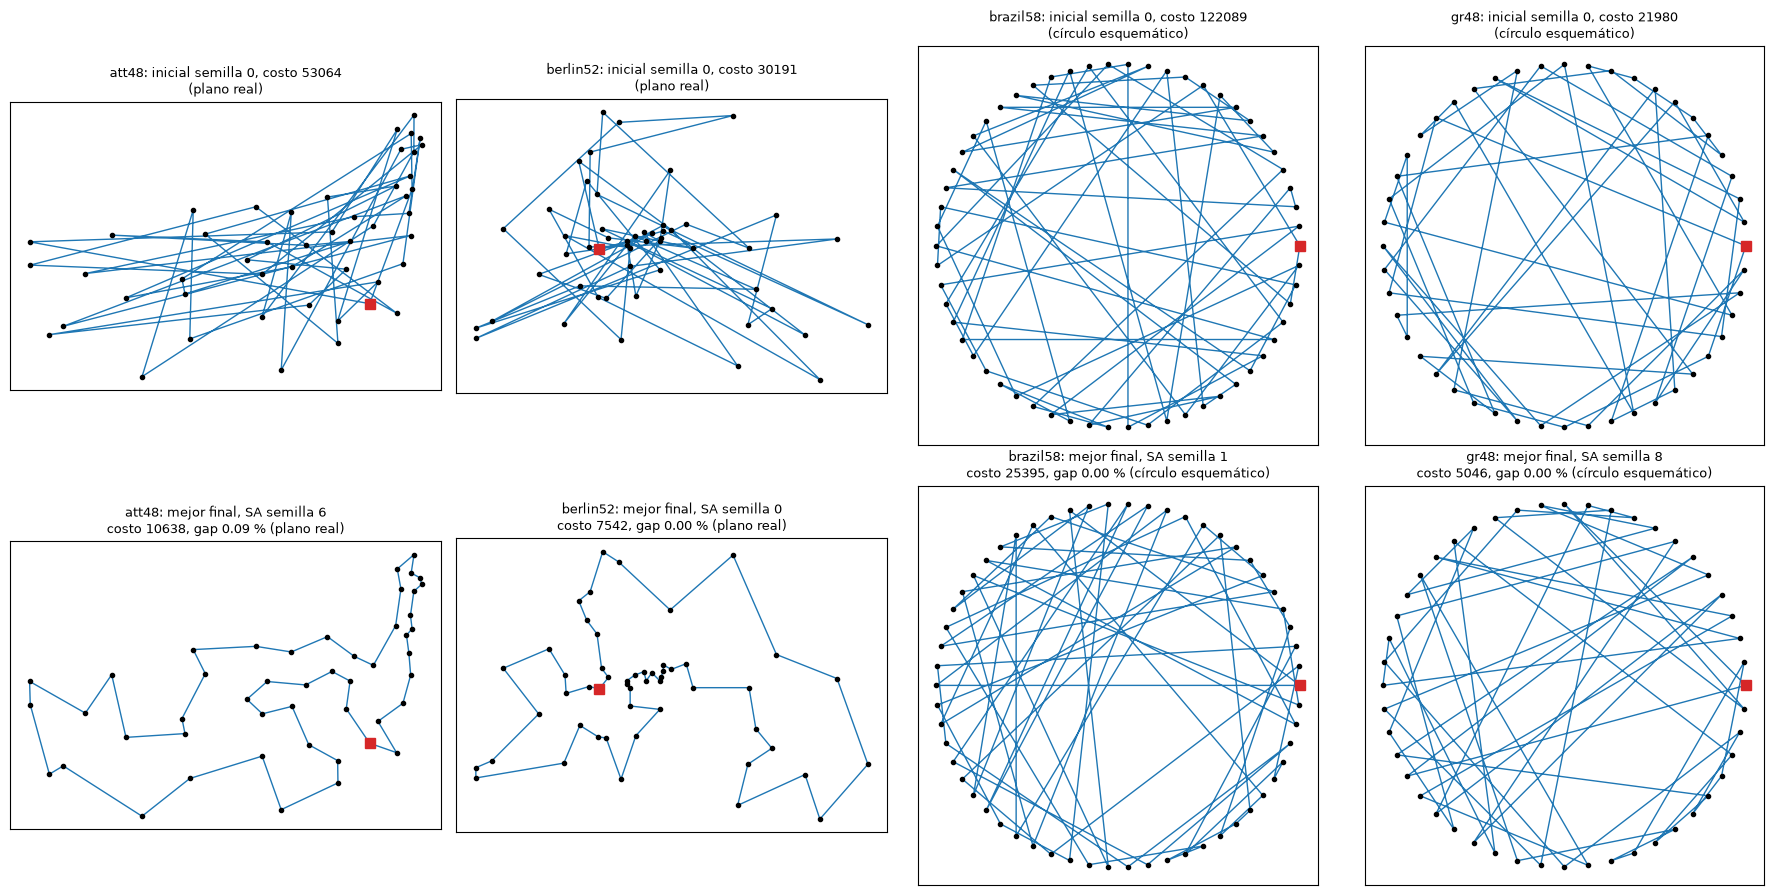

att48: cruces en la ruta inicial de la semilla 0 = 330, en la mejor final (SA, semilla 6) = 0
berlin52: cruces en la ruta inicial de la semilla 0 = 299, en la mejor final (SA, semilla 0) = 0


In [46]:
def layout(inst):
    if inst.coords is not None:
        return inst.coords
    angle = 2 * np.pi * np.arange(inst.n) / inst.n
    return np.column_stack([np.cos(angle), np.sin(angle)])


def draw_tour(ax, inst, tour, title):
    xy = layout(inst)
    closed = list(tour) + [tour[0]]
    ax.plot(xy[closed, 0], xy[closed, 1], "-", lw=1, color="tab:blue")
    ax.plot(xy[:, 0], xy[:, 1], "o", ms=3, color="black")
    ax.plot(*xy[tour[0]], "s", ms=7, color="tab:red")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, name in enumerate(MANDATORY):
    inst = INSTANCES[name]
    start = initial_tour(inst, 0)
    best = min((r for r in b_runs if r.instance == name and r.parameters["budget"] == 200_000), key=lambda r: r.cost)
    kind = "plano real" if inst.coords is not None else "círculo esquemático"
    draw_tour(axes[0, col], inst, start, f"{name}: inicial semilla 0, costo {tour_cost(inst.W, start)}\n({kind})")
    draw_tour(axes[1, col], inst, best.tour, f"{name}: mejor final, {best.algorithm} semilla {best.seed}\n"
                                             f"costo {best.cost}, gap {best.gap_percent:.2f} % ({kind})")
plt.tight_layout()
plt.show()
for name in ("att48", "berlin52"):
    inst = INSTANCES[name]
    best = min((r for r in b_runs if r.instance == name and r.parameters["budget"] == 200_000), key=lambda r: r.cost)
    print(f"{name}: cruces en la ruta inicial de la semilla 0 = {count_crossings(inst.coords, initial_tour(inst, 0))}, "
          f"en la mejor final ({best.algorithm}, semilla {best.seed}) = {count_crossings(inst.coords, best.tour)}")

**Figura 2. Mejor costo acumulado frente a evaluaciones y frente a tiempo** (presupuesto principal). La línea es la mediana de las 10 semillas y la banda va del mínimo al máximo. El eje vertical es el gap, para poder poner las cuatro instancias en la misma escala, y está cortado en 60 %: lo que está más arriba, al inicio de cada curva, no se ve. Cuando una ejecución para antes del final (HC de una ruta para en su óptimo local), su último valor se **conserva**: a partir de la primera parada la línea sigue **punteada**, para que no se lea como evaluaciones ejecutadas.

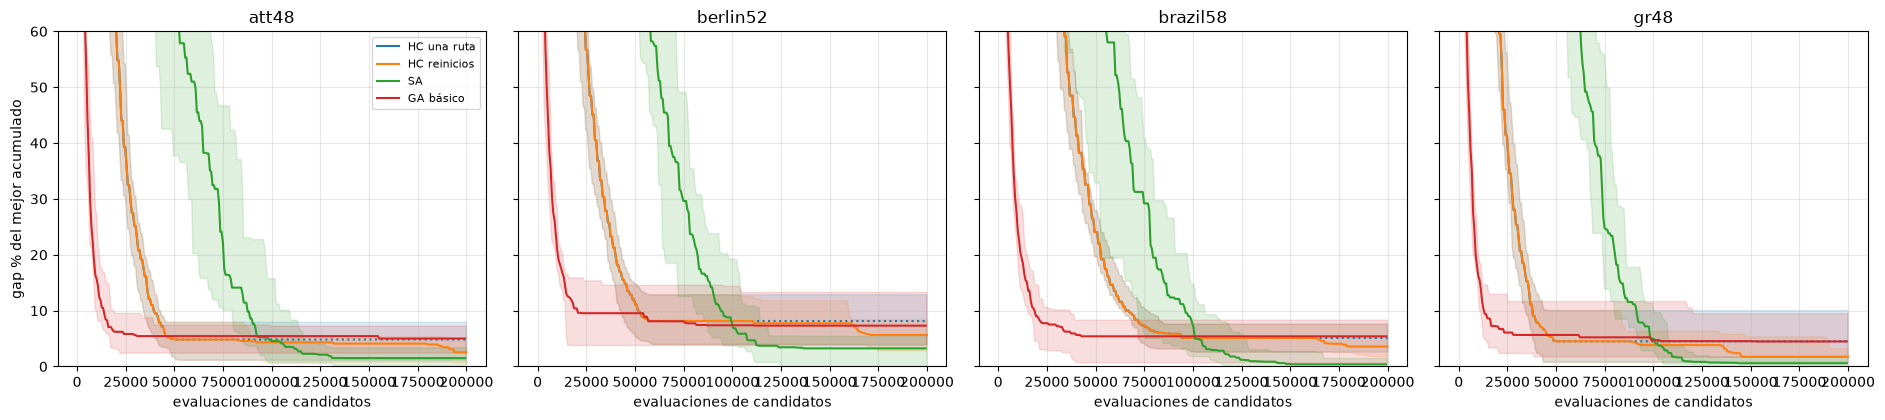

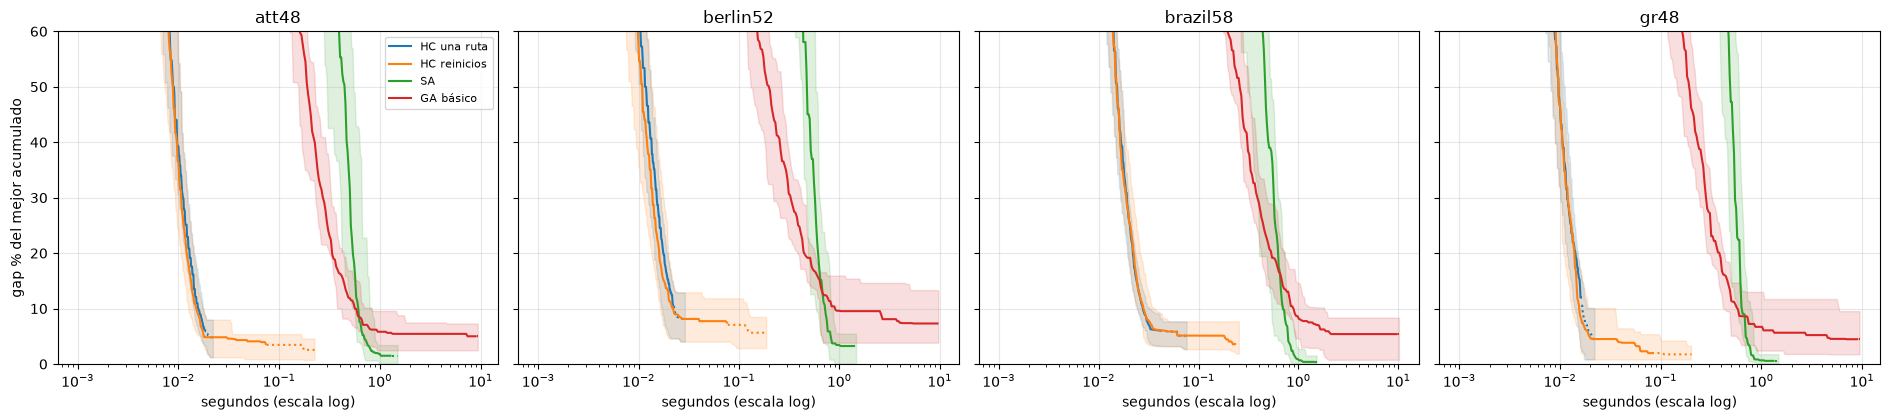

In [47]:
COLORS = dict(zip(LOCAL, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))


def curve(history, grid, axis):
    xs = np.array([h[axis] for h in history])
    ys = np.array([h[2] for h in history], dtype=float)
    return ys[np.maximum(np.searchsorted(xs, grid, side="right") - 1, 0)]


def plot_curves(axis, xlabel, grid_max, log_x):
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), sharey=True)
    for ax, name in zip(axes, MANDATORY):
        opt = INSTANCES[name].optimum
        for alg in LOCAL:
            rs = [runs_b[(name, alg, s, 200_000)] for s in SEEDS]
            top = grid_max(rs)
            grid = np.geomspace(1e-3 if axis else 1, top, 300) if log_x else np.linspace(1, top, 300)
            gaps = np.array([100 * (curve(r.history, grid, axis) - opt) / opt for r in rs])
            ends = [r.candidate_evaluations if axis == 0 else r.elapsed_seconds for r in rs]
            med = np.median(gaps, axis=0)
            live = grid <= min(ends)
            ax.fill_between(grid, gaps.min(axis=0), gaps.max(axis=0), color=COLORS[alg], alpha=0.15)
            ax.plot(grid[live], med[live], color=COLORS[alg], label=alg)
            ax.plot(grid[~live], med[~live], ":", color=COLORS[alg])
        ax.set_ylim(0, 60)
        ax.set_title(name)
        ax.set_xlabel(xlabel)
        if log_x:
            ax.set_xscale("log")
    axes[0].set_ylabel("gap % del mejor acumulado")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_curves(0, "evaluaciones de candidatos", lambda rs: 200_000, False)
plot_curves(1, "segundos (escala log)", lambda rs: max(r.elapsed_seconds for r in rs), True)

**Figura 3. Gap por algoritmo e instancia,** con cajas y cada semilla como un punto, en los dos presupuestos.

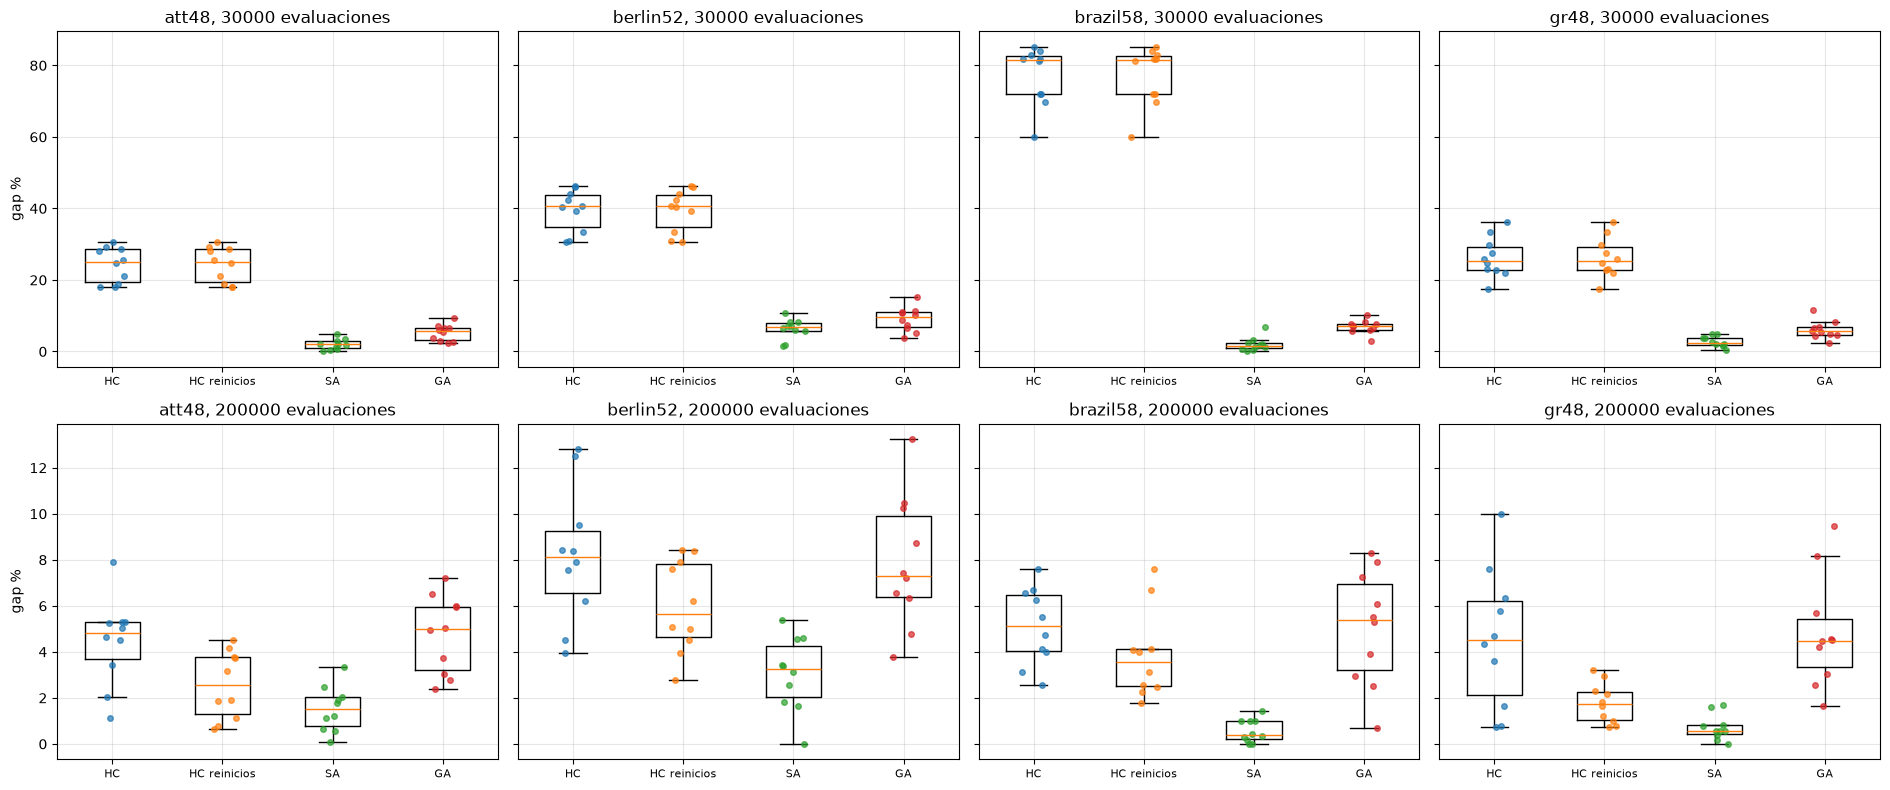

In [48]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8), sharey="row")
jitter = np.random.default_rng(0)
for row, b in enumerate(BUDGETS):
    for ax, name in zip(axes[row], MANDATORY):
        data = [df_b[(df_b["instance"] == name) & (df_b["algorithm"] == alg) & (df_b["presupuesto"] == b)]["gap_percent"]
                for alg in LOCAL]
        ax.boxplot(data, widths=0.5, showfliers=False)
        for i, d in enumerate(data, start=1):
            ax.plot(i + jitter.uniform(-0.12, 0.12, len(d)), d, "o", ms=4, alpha=0.7, color=COLORS[LOCAL[i - 1]])
        ax.set_xticks(range(1, 5), ["HC", "HC reinicios", "SA", "GA"], fontsize=8)
        ax.set_title(f"{name}, {b} evaluaciones")
    axes[row, 0].set_ylabel("gap %")
plt.tight_layout()
plt.show()

**Figura 4. Tiempo y memoria de A\* y RBFS contra el tamaño de la subinstancia** (escala A, escala logarítmica). Una **x** marca una ejecución interrumpida por el presupuesto de exactos.

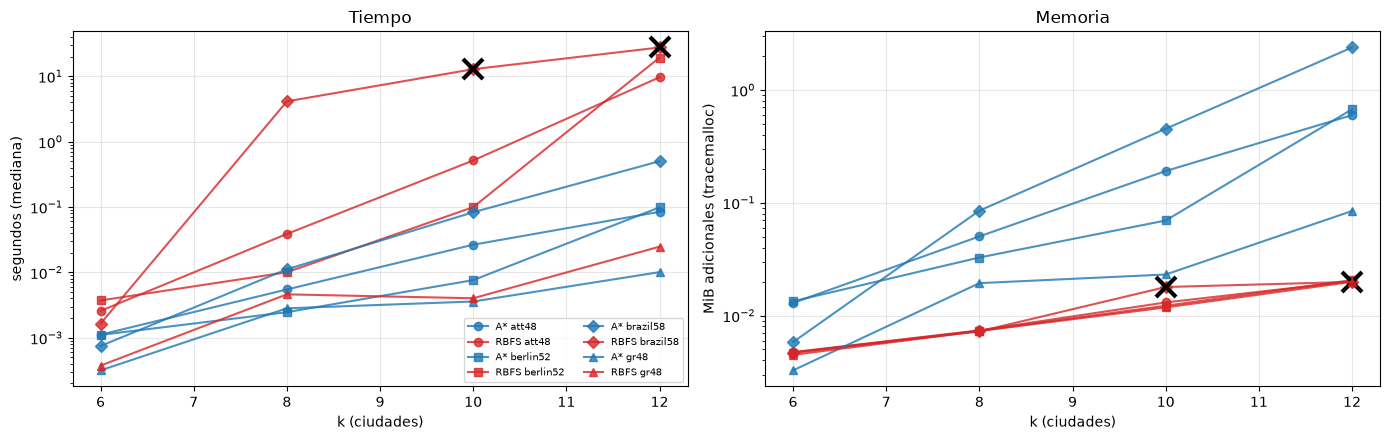

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, marker in zip(MANDATORY, "osD^"):
    d = scale_a[scale_a["instancia"] == name]
    for algo, color, col_s, col_m in (("A*", "tab:blue", "s A* (mediana)", "MiB A*"),
                                      ("RBFS", "tab:red", "s RBFS (mediana)", "MiB RBFS")):
        axes[0].plot(d["k"], d[col_s], marker=marker, color=color, alpha=0.8, label=f"{algo} {name}")
        axes[1].plot(d["k"], d[col_m].clip(lower=1e-3), marker=marker, color=color, alpha=0.8)
        if algo == "RBFS":
            cut = d[d["parada RBFS"] != "GOAL"]
            axes[0].plot(cut["k"], cut[col_s], "x", ms=14, mew=3, color="black")
            axes[1].plot(cut["k"], cut[col_m].clip(lower=1e-3), "x", ms=14, mew=3, color="black")
axes[0].set(yscale="log", xlabel="k (ciudades)", ylabel="segundos (mediana)", title="Tiempo")
axes[1].set(yscale="log", xlabel="k (ciudades)", ylabel="MiB adicionales (tracemalloc)", title="Memoria")
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

**Figura 5. SA en berlin52, semilla 0, presupuesto principal:** temperatura, costo actual y mejor costo, y tasa de aceptación de empeoramientos. La **ventana de aceptación es un nivel de temperatura**: la tasa es aceptados con $\Delta > 0$ sobre propuestos con $\Delta > 0$ dentro de ese nivel.

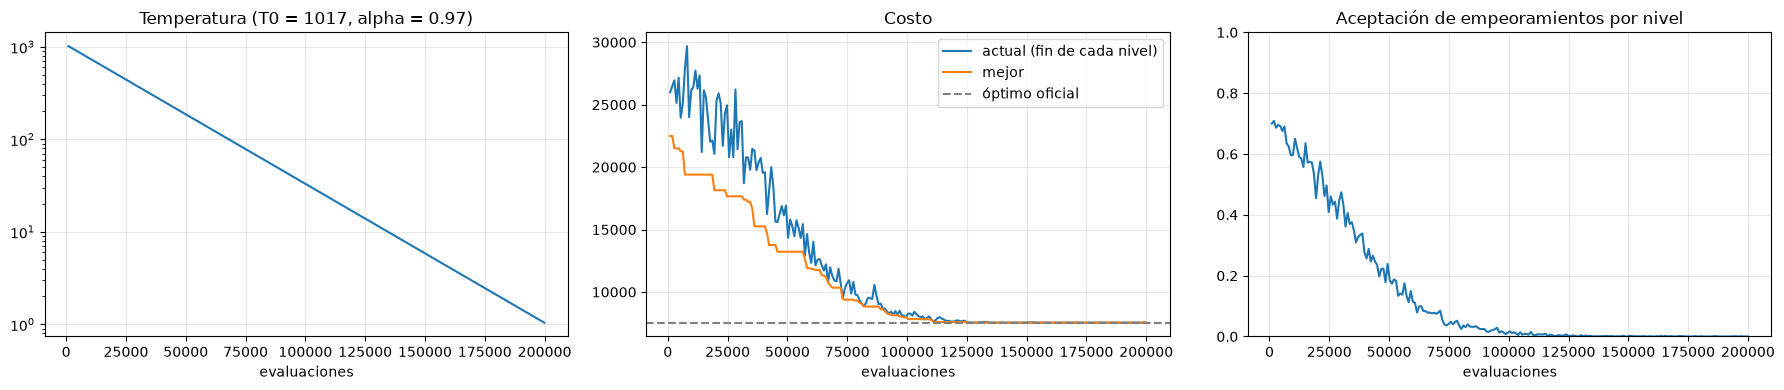

ventana de aceptación: un nivel de temperatura = 880 propuestas; 227 niveles
SA con 30000 evaluaciones: la ruta actual termina igual a la mejor en 29 de 40 corridas
SA con 200000 evaluaciones: la ruta actual termina igual a la mejor en 26 de 40 corridas


In [50]:
sa_demo = runs_b[("berlin52", "SA", 0, 200_000)]
lv = pd.DataFrame(sa_demo.extra["levels"])
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(lv["evals"], lv["T"])
axes[0].set(yscale="log", title=f"Temperatura (T0 = {sa_demo.extra['T0']:.0f}, alpha = {FROZEN['SA']['alpha']})",
            xlabel="evaluaciones")
axes[1].plot(lv["evals"], lv["current"], label="actual (fin de cada nivel)")
axes[1].plot(lv["evals"], lv["best"], label="mejor")
axes[1].axhline(INSTANCES["berlin52"].optimum, ls="--", color="gray", label="óptimo oficial")
axes[1].set(title="Costo", xlabel="evaluaciones")
axes[1].legend()
axes[2].plot(lv["evals"], lv["worse_acceptance"])
axes[2].set(title="Aceptación de empeoramientos por nivel", xlabel="evaluaciones", ylim=(0, 1))
plt.tight_layout()
plt.show()
print(f"ventana de aceptación: un nivel de temperatura = {sa_demo.parameters['steps']} propuestas; "
      f"{sa_demo.parameters['levels']} niveles")
for b in BUDGETS:
    sa_all = [r for r in b_runs if r.algorithm == "SA" and r.parameters["budget"] == b]
    print(f"SA con {b} evaluaciones: la ruta actual termina igual a la mejor en "
          f"{sum(r.extra['final_current'] == r.cost for r in sa_all)} de {len(sa_all)} corridas")

**Figura 6. GA en berlin52, semilla 0, presupuesto principal:** mejor costo y costo mediano de la población, y las dos medidas de diversidad de F.2 por generación.

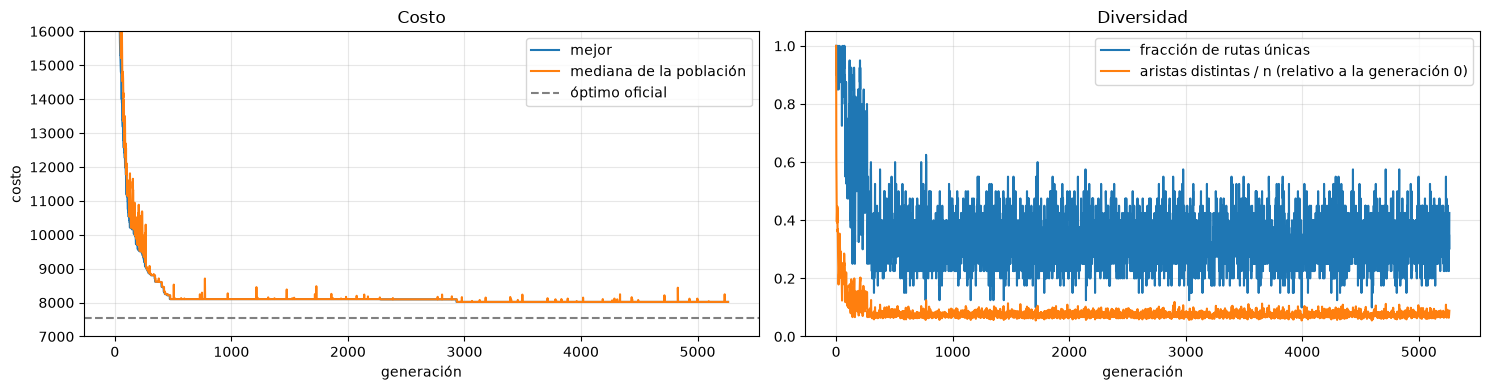

5262 generaciones; aristas distintas / n: 20.2 al inicio, 1.79 al final
GA, 40 corridas con 200 000 evaluaciones: la última mejora ocurre antes de la mitad del presupuesto en 31 de 40; fracción mediana del presupuesto: 0.18


In [51]:
ga_demo = runs_b[("berlin52", "GA básico", 0, 200_000)]
gl = pd.DataFrame(ga_demo.extra["gen_log"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(gl["generation"], gl["best"], label="mejor")
axes[0].plot(gl["generation"], gl["median"], label="mediana de la población")
axes[0].axhline(INSTANCES["berlin52"].optimum, ls="--", color="gray", label="óptimo oficial")
axes[0].set(xlabel="generación", ylabel="costo", ylim=(7000, 16000), title="Costo")
axes[0].legend()
axes[1].plot(gl["generation"], gl["unique"], label="fracción de rutas únicas")
axes[1].plot(gl["generation"], gl["edge_diversity"] / gl["edge_diversity"].iloc[0],
             label="aristas distintas / n (relativo a la generación 0)")
axes[1].set(xlabel="generación", title="Diversidad", ylim=(0, 1.05))
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"{ga_demo.extra['generations']} generaciones; aristas distintas / n: {gl['edge_diversity'].iloc[0]:.1f} al inicio, "
      f"{gl['edge_diversity'].iloc[-1]:.2f} al final")
last_gain = [r.history[-1][0] / r.candidate_evaluations for r in b_runs
             if r.algorithm == "GA básico" and r.parameters["budget"] == 200_000]
print(f"GA, 40 corridas con 200 000 evaluaciones: la última mejora ocurre antes de la mitad del presupuesto en "
      f"{sum(f < 0.5 for f in last_gain)} de {len(last_gain)}; fracción mediana del presupuesto: "
      f"{statistics.median(last_gain):.2f}")

**Lo que encontramos (G.6):**

- **Figura 1.** La ruta inicial de la semilla 0 tiene 330 cruces en att48 y 299 en berlin52, y las mejores rutas finales de las dos tienen 0 (conteo impreso bajo la figura). Se ven como un recorrido razonable por el mapa. Las cuatro mejores son de SA, y en berlin52, brazil58 y gr48 tienen exactamente el costo óptimo; la de att48 tiene gap 0.09 %. En brazil58 y gr48 el dibujo circular se ve igual de enredado al inicio que al final: sin coordenadas, el dibujo no dice nada de la calidad, y por eso ahí miramos solo el costo.
- **Figura 2, por evaluaciones.** Cada método tiene su propia forma. El GA baja más rápido al principio y va primero hasta entre unas 45 000 y unas 90 000 evaluaciones, según la instancia (lectura de la figura). HC y HC con reinicios bajan más tarde y luego HC se detiene en su óptimo local (la línea pasa a punteada desde que para la primera semilla). SA empieza más arriba y baja de forma continua mientras se enfría (en la figura 5, el mejor costo de berlin52 baja de unos 22 500 a unos 9 000 hacia las 90 000 evaluaciones). Cruza a los demás entre las 100 000 y las 125 000 evaluaciones, según la instancia, y termina por debajo de todos. Ojo con una lectura equivocada: estas curvas son de la corrida de 200 000, y a las 30 000 evaluaciones de la curva SA todavía está caliente. Con el presupuesto real de 30 000, SA se enfría dentro del presupuesto y gana al GA en las cuatro instancias (gap mediano 1.5-6.8 % contra 5.6-9.5 %, G.4). El orden entre SA y GA depende del presupuesto, y la figura no muestra que el GA gane con poco presupuesto.
- **Figura 2, por tiempo.** El orden cambia otra vez, pero esta figura usa los tiempos con `tracemalloc`, que inflan a SA unas 9 a 12 veces y a HC de una ruta unas 2 veces (G.7). Con esa medición, HC y HC con reinicios terminan en menos de 0.3 s, SA hacia 1.5 s y el GA tarda unos 9 a 11 s. Las curvas de HC con reinicios están por debajo de la de SA hasta cerca de 1 s. Eso es en buena parte un efecto de la medición: sin `tracemalloc` SA tarda unos 0.14 s en total (tabla de G.7). Para el orden de tiempos usamos esa tabla (pregunta 9).
- **Figura 3.** Con 30 000 evaluaciones las cajas de HC y HC con reinicios son idénticas (nunca reinician) y están muy arriba. Con 200 000 la caja de SA es la más baja y la más estrecha en las cuatro instancias; en att48 y gr48 la de HC con reinicios queda más cerca. Las cajas más anchas son las de HC de una ruta y del GA: en berlin52 la peor semilla del GA llega a 13.25 % y la de HC de una ruta a 12.83 % (H.1).
- **Figura 4.** El tiempo de RBFS crece mucho más rápido que el de A\*: en brazil58 ya en $k=8$ tarda más de 3 s, y las cruces marcan los cortes en $k=10$ y $k=12$. La memoria es al revés: la de RBFS es una recta baja y casi igual en las cuatro instancias, y la de A\* sube con $k$ y depende mucho de la instancia.
- **Figura 5.** La temperatura baja en línea recta en escala logarítmica, como corresponde a $T \leftarrow \alpha T$. $T_0$ vale 1017 y la temperatura baja hasta cerca de 1 en 227 niveles. Cada punto es un nivel de temperatura, con una ventana de aceptación de 880 propuestas (línea impresa bajo la figura). La aceptación de empeoramientos empieza cerca de 0.7 en esta semilla (la mediana de las 10 semillas en el primer nivel es 0.733, G.5; la calibración apuntaba a 0.8) y llega a casi 0 entre las 100 000 y las 125 000 evaluaciones. Mientras está caliente, la ruta actual sube y baja muy por encima de la mejor; cuando la aceptación cae, las dos se juntan y desde ahí SA es un descenso que termina en el óptimo, 7542. Al terminar el enfriamiento, la ruta actual coincide con la mejor en 26 de las 40 corridas de SA con 200 000 evaluaciones y en 29 de 40 con 30 000 (conteo impreso bajo la figura). En las demás, la mejor ruta se vio antes del final.
- **Figura 6.** En esta corrida (berlin52, semilla 0, 5262 generaciones) el GA baja rápido hasta cerca de la generación 500 (costo de unos 8 100) y después casi no mejora: hacia la generación 2 900 hay una última mejora pequeña y en las unas 2 300 generaciones finales no baja más. Desde cerca de la generación 500 la mediana de la población es igual al mejor (con picos aislados), la fracción de rutas únicas oscila alrededor de 0.3 y las aristas distintas quedan cerca del 9 % de las iniciales (1.79 contra 20.2). Es una señal de convergencia prematura (pregunta 8). No es solo esta corrida: la celda imprime que en 31 de las 40 corridas la última mejora llega antes de la mitad del presupuesto, con una fracción mediana de 0.18. Esta semilla es de las 9 donde la última mejora, pequeña, llega después de la mitad.

#### G.8 Animación didáctica: HC mejorando una ruta de berlin52

Corremos HC de una ruta en berlin52 con la semilla 0 y guardamos la ruta en cada mejora (`snapshots`). Es una corrida aparte, que no se usa para medir. Los cuadros se dibujan **después** de la corrida. Cada cuadro muestra el algoritmo, el costo y las evaluaciones acumuladas. El GIF queda en `figuras/` y se ve aquí abajo.

47 cuadros -> figuras/hc_berlin52.gif


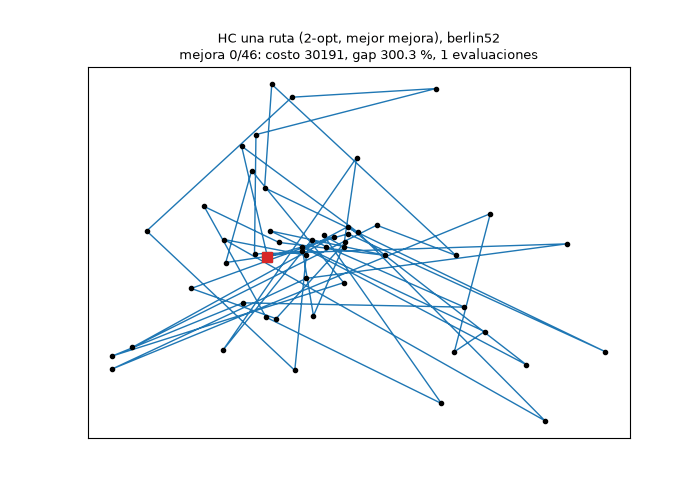

In [52]:
snaps = []
anim_run = hill_climbing(berlin, initial_tour(berlin, 0), BIG, random.Random(0), snapshots=snaps)
assert anim_run.cost == runs_b[("berlin52", "HC una ruta", 0, 200_000)].cost
frames = [(1, initial_tour(berlin, 0), anim_run.extra["initial_cost"])] + snaps
fig, ax = plt.subplots(figsize=(7, 5))


def draw_frame(i):
    ax.clear()
    evals, tour, cost = frames[i]
    draw_tour(ax, berlin, tour, f"HC una ruta (2-opt, mejor mejora), berlin52\n"
                                f"mejora {i}/{len(frames) - 1}: costo {cost}, gap {gap_percent(cost, 7542):.1f} %, "
                                f"{evals} evaluaciones")


gif_path = FIG_DIR / "hc_berlin52.gif"
animation.FuncAnimation(fig, draw_frame, frames=len(frames)).save(gif_path, writer=animation.PillowWriter(fps=4))
plt.close(fig)
print(f"{len(frames)} cuadros -> {gif_path}")
display(Image(filename=str(gif_path)))

**Lo que encontramos (G.8):** la animación tiene 47 cuadros: la ruta inicial y las 46 mejoras de HC hasta su óptimo local. Las primeras mejoras quitan cruces largos que atraviesan todo el mapa y bajan mucho el costo: con solo 3 mejoras pasa de 30 191 a 24 865. Las últimas reacomodan tramos cortos y ganan poco: las 16 últimas bajan de 9628 a 8113. Al final la ruta no tiene cruces, pero su gap sigue siendo de 7.6 % (es la misma corrida de HC de la semilla 0 de G.4): sin cruces no quiere decir óptima (E.2).

## 16. Discusión: responda con evidencia

---
### SOLUCIÓN · tabla de apoyo para las preguntas

#### H.1 Resumen para la discusión

Antes de responder juntamos en una tabla lo que más usan las preguntas 7, 9 y 10: gap mediano, dispersión y tiempo mediano de cada método local en las cuatro instancias, con el presupuesto principal (200 000 evaluaciones). Sale de `df_b` (G.4), no de números copiados a mano. Las columnas de orden dicen qué puesto ocupa cada método en cada instancia, por gap mediano y por tiempo mediano. El tiempo de esta tabla se midió con `tracemalloc`: para comparar tiempos entre métodos usamos la tabla sin `tracemalloc` de G.7.

In [53]:
main = df_b[df_b["presupuesto"] == 200_000]
discussion = (main.groupby(["instance", "algorithm"], sort=False)
              .agg(gap_mediano=("gap_percent", "median"), gap_desv=("gap_percent", "std"),
                   gap_max=("gap_percent", "max"), s_mediano=("elapsed_seconds", "median"),
                   llega_al_optimo=("gap_percent", lambda g: int((g == 0).sum())))
              .round(2))
discussion["orden por gap"] = discussion.groupby(level=0)["gap_mediano"].rank(method="min").astype(int)
discussion["orden por tiempo"] = discussion.groupby(level=0)["s_mediano"].rank(method="min").astype(int)
display(discussion)
print("puesto medio por gap:", discussion.groupby(level=1, sort=False)["orden por gap"].mean().to_dict())
print("puesto medio por tiempo (con tracemalloc):",
      discussion.groupby(level=1, sort=False)["orden por tiempo"].mean().to_dict())

gap_mediano  gap_desv  gap_max  s_mediano  llega_al_optimo  orden por gap  orden por tiempo
instance algorithm                                                                                                
att48    HC una ruta          4.83      1.90     7.91       0.02                0              3                 1
         HC reinicios         2.55      1.47     4.51       0.14                0              2                 2
         SA                   1.50      0.98     3.34       1.35                0              1                 3
         GA básico            5.01      1.69     7.22       9.12                0              4                 4
berlin52 HC una ruta          8.13      2.94    12.83       0.03                0              4                 1
         HC reinicios         5.65      2.00     8.41       0.11                0              2                 2
         SA                   3.25      1.61     5.40       1.44                1              1                 3
         GA básico            7.31      2.86    13.25       9.65                0              3                 4
brazil58 HC una ruta          5.11      1.66     7.60       0.05                0              3                 1
         HC reinicios         3.57      1.91     7.60       0.24                0              2                 2
         SA                   0.39      0.49     1.44       1.46                2              1                 3
         GA básico            5.40      2.50     8.29      10.08                0              4                 4
gr48     HC una ruta          4.51      3.01    10.01       0.02                0              4                 1
         HC reinicios         1.74      0.86     3.19       0.13                0              2                 2
         SA                   0.57      0.55     1.68       1.42                1              1                 3
         GA básico            4.48      2.41     9.45       9.13                0              3                 4

puesto medio por gap: {'HC una ruta': 3.5, 'HC reinicios': 2.0, 'SA': 1.0, 'GA básico': 3.5}
puesto medio por tiempo (con tracemalloc): {'HC una ruta': 1.0, 'HC reinicios': 2.0, 'SA': 3.0, 'GA básico': 4.0}


1. ¿Por qué A* y RBFS trabajan con rutas parciales mientras HC, SA y GA trabajan con rutas completas?

---
### SOLUCIÓN · pregunta 1

Porque hacen cosas distintas. A\* y RBFS **construyen** la ruta ciudad por ciudad. Antes de terminarla necesitan saber si vale la pena seguir, y eso lo da $f = g + h$: $g$ es lo ya recorrido y $h$ una cota de lo que falta (C.2, C.3). Sobre una ruta completa no queda nada por acotar. HC, SA y GA **mejoran** rutas que ya existen. Necesitan un costo completo para comparar, y sus operadores (2-opt, OX, inversión) solo tienen sentido sobre una permutación entera (E.1, F.1). Por eso los exactos pueden certificar el óptimo cuando terminan (D.4), y los locales siempre tienen una ruta que devolver, aunque sea mala (G.4, 30 000 evaluaciones).

2. ¿Por qué el MST da una cota y no una solución? ¿Qué información pierde la relajación?

---
### SOLUCIÓN · pregunta 2

Lo que falta de una ruta parcial es un camino que pasa por todas las ciudades pendientes y vuelve al origen. Si le quitamos las dos aristas de conexión, queda un árbol que une las pendientes, y ningún árbol es más barato que el MST. Por eso la suma no se pasa del costo real (C.4). Pero el MST no exige **grado 2** ni que sea un solo camino: puede ramificarse, y las dos aristas de conexión pueden salir hacia la misma ciudad. Eso es lo que pierde. En C.8 lo medimos sobre los 13 700 prefijos de dos subproblemas de 8 ciudades: la cota nunca falla, pero el cociente $h$/residual baja hasta 0.76 en berlin52 y 0.64 en gr48. Ese mínimo está a profundidad 5 (quedan 2 pendientes), no en la raíz, donde el cociente es 0.82 y 0.72. En el peor caso, la cota deja sin contar entre casi una cuarta parte y más de un tercio de lo que falta. Con 48 ciudades ni A\* ni RBFS terminan en 30 s (G.4); no medimos cuánto de eso se debe a este hueco.

3. ¿Qué sucede si A* cierra estados usando solamente la última ciudad?

---
### SOLUCIÓN · pregunta 3

Dos rutas parciales que terminan en la misma ciudad se tratan como el mismo estado, aunque les falten ciudades distintas. En D.5 A\* no devuelve **ninguna** ruta en los 5 casos (`EXHAUSTED`): el primer prefijo que llega a cada ciudad es el directo desde el origen y tiene el menor $g$, así que se descarta todo prefijo más largo. Con una regla parecida a la de TSP Solve, que además compara la profundidad (C.1, `city_depth`), sí aparecen rutas, pero no óptimas: 5879 contra 5715 en att48 con $k=6$. En C.7 está el par concreto: el prefijo descartado era el que llevaba a 5715.

4. ¿Por qué devolver el primer nodo con pendientes vacíos, sin cobrar el retorno, puede dar una respuesta incorrecta?

---
### SOLUCIÓN · pregunta 4

Porque ese nodo es el mejor **camino** abierto, no el mejor ciclo. En D.5, en att48 con $k=6$, el camino cuesta 4151, pero al cerrarlo el ciclo cuesta 6163, un 7.8 % más que el óptimo 5715. El camino más barato puede terminar lejos del origen y el regreso se paga después. Nuestro A\* evita el error con el estado "cerrado": la meta se reconoce cuando sale de la frontera un nodo que ya pagó el regreso (D.1).

5. ¿En qué casos RBFS redujo memoria y aumentó recomputación? Muestre números y una traza.

---
### SOLUCIÓN · pregunta 5

En 15 de los 16 subproblemas de la escala A (G.3, tabla y figura 4). La excepción es gr48 con $k=6$: A\* guarda 11 nodos en la frontera, RBFS tiene 17 registros vivos y no regenera nada. En $k = 12$, A\* guarda entre 202 (gr48) y 4204 (brazil58) nodos en la frontera y usa hasta 2.38 MiB; RBFS nunca pasa de 68 registros vivos ni de 0.02 MiB. La razón de memoria va de 4 a 120 veces (la de 120 es brazil58, donde RBFS está interrumpido). El precio son las regeneraciones: en berlin52 con $k=12$, 78 936 de 80 651 expansiones son regeneraciones (97.9 %), y RBFS tarda unos 18 s contra 0.09 s de A\*. En att48 y brazil58 con $k=12$ también es casi todo; en gr48 con $k=12$ es el 52 % (G.3, columna `% regeneradas`). En brazil58 con $k = 10$ y $k = 12$, y en burma14 y gr17 completas (D.8), RBFS se corta por presupuesto mientras A\* termina. La traza de D.3 muestra el mecanismo en pequeño. En las filas 1 a 3, la rama 23-24 falla con límite 1789, guarda el valor respaldado 1878 y se olvida; después **reaparece** y se expande otra vez.

6. ¿Qué diferencias encontró entre att48 y gr48, ambas con 48 ciudades?

---
### SOLUCIÓN · pregunta 6

No es el mismo problema con otro nombre.
- **Datos:** att48 tiene coordenadas y la distancia pseudo-euclidiana ATT. gr48 es una matriz explícita, sin coordenadas (B, fichas). En gr48 no hay cruces ni plano: su figura 1 es un círculo esquemático (E.2, G.6).
- **Exactos:** gr48 es más fácil, pero solo en los primeros 12 identificadores. En $k = 12$, A\* hace 38 expansiones en gr48 y 376 en att48, y RBFS 79 contra 32 375 (G.3). La cota de la raíz está más cerca del óptimo en gr48 (0.82 contra 0.77, columna `h(raíz)/óptimo` de G.3). En las instancias completas la diferencia casi desaparece: A\* hace 1933 expansiones en gr48 y 1749 en att48 antes de cortarse a los 30 s, y ninguno termina (G.4). Esas cifras dependen de la velocidad de la máquina.
- **Locales:** las dos quedan a pocos puntos de gap con 200 000 evaluaciones (H.1). att48 es donde SA y HC con reinicios quedan más cerca: SA pierde en 3 de 10 semillas (y empata 1) y la diferencia mediana es de 85 unidades, un 0.8 % del óptimo; en gr48 pierde en 2 y la diferencia es de 65.5 unidades, un 1.3 % (G.5). SA llega al óptimo de gr48 en 1 semilla y al de att48 en ninguna (G.4).
- **Escala del costo:** el óptimo de att48 es 10 628 y el de gr48 5046 (B.2), así que una misma diferencia absoluta pesa distinto. Por eso comparamos con el gap.

7. ¿Cuánto aportaron los reinicios frente a aceptar movimientos peores? Analice distribución, no solo la mejor ejecución.

---
### SOLUCIÓN · pregunta 7

Miramos la distribución de las 10 semillas (H.1, figura 3, G.5), no la mejor corrida.
- Con 30 000 evaluaciones los reinicios no aportan **nada**: HC nunca llega a su primer óptimo local, así que HC con reinicios da lo mismo que HC de una ruta (G.4).
- Con 200 000 los reinicios sí se usan, pero poco: en 200 000 evaluaciones HC con reinicios completa solo 2 a 4 descensos (att48 4, berlin52 3, brazil58 2, gr48 4), porque cada descenso cuesta entre 50 000 y 99 000 evaluaciones (E.2). Bajan el gap mediano de 4.5-8.1 % a 1.7-5.7 %. Aceptar empeoramientos (SA) lo baja más: 0.4-3.3 %. SA le gana a HC con reinicios en 34 de 40 pares con la misma ruta inicial (G.5) y es el único que llega al óptimo oficial (4 de 40 corridas).
- Dispersión (columnas `gap_desv` y `gap_max` de H.1): la desviación del gap de SA es de 0.5 a 1.6 puntos y la de HC con reinicios de 0.9 a 2.0. El peor gap de SA va de 1.4 % a 5.4 % y el de HC con reinicios de 3.2 % a 8.4 %. SA es mejor en mediana y también tiene menos cola.

8. ¿Qué signos de convergencia prematura observó en el GA? ¿Cómo se relacionan con la diversidad?

---
### SOLUCIÓN · pregunta 8

En la corrida de berlin52 con el presupuesto principal (figura 6), las aristas distintas por ciudad bajan de 20.2 al inicio a 1.79 al final: casi toda la población usa las mismas aristas. Desde cerca de la generación 500 la mediana de la población es igual al mejor, y el costo casi no cambia: hacia la generación 2 900 hay una última mejora pequeña y en las unas 2 300 generaciones finales no baja más (de 5262 en total). La fracción de rutas únicas se mantiene en torno a 0.3, mucho más alta que la diversidad de aristas, así que ese indicador por sí solo no avisa de la convergencia. No medimos cuánto difieren esas rutas entre sí. No es un caso aislado: en 31 de las 40 corridas del GA con 200 000 evaluaciones la última mejora ocurre antes de la mitad del presupuesto, y la mediana está en el 18 % (G.6, figura 6). Con poca diversidad de aristas, el OX ya no tiene nada nuevo que combinar y solo la mutación trae aristas nuevas. Es coherente con que en la calibración gane la mutación alta, $p_m = 0.3$ (G.2), aunque no probamos la relación. En las 10 semillas el GA queda cerca de HC de una ruta (gap mediano 4.5-7.3 % contra 4.5-8.1 % de HC, H.1) y lejos de SA (0.4-3.3 %).

9. ¿Cambió el ranking al comparar tiempo en lugar de evaluaciones?

---
### SOLUCIÓN · pregunta 9

Sí en el tiempo, no en la calidad. Por **calidad con las mismas evaluaciones**, el orden es SA, HC con reinicios, y al final HC de una ruta y GA empatados (H.1, puesto medio por gap: 1.0, 2.0, 3.5 y 3.5), porque el GA y HC de una ruta cambian de lugar según la instancia. Por **tiempo**, la tabla sin `tracemalloc` de G.7 da HC de una ruta (0.014 s), HC con reinicios (0.052 s), SA (0.142 s) y GA (1.8 s). Es decir, el orden por tiempo es HC < HC con reinicios < SA < GA, y SA tarda unas 2.7 veces lo que HC con reinicios, no las 6 a 13 veces que dan las tablas con `tracemalloc` (G.4, H.1). Esas veces eran en gran parte la medición: `tracemalloc` hace a SA unas 9 a 12 veces más lento y a HC de una ruta solo unas 2 veces (G.7). El ranking por calidad contra tiempo cambia así: con las mismas evaluaciones SA gana, pero HC con reinicios es unas 2.7 veces más barato en tiempo y SA le gana en 34 de 40 pares (G.5). Si el corte es por segundos, el resultado depende del corte y no lo probamos con el mismo tiempo para todos (pregunta 12).

10. Si dispone de dos segundos para devolver una ruta, ¿qué elegiría según sus datos? ¿Y si necesita demostrar optimalidad?

---
### SOLUCIÓN · pregunta 10

- **Dos segundos:** SA con 200 000 evaluaciones. Sin `tracemalloc` tarda unos 0.14 s (G.7), y con `tracemalloc` y 8 procesos tardó 1.4-1.5 s (G.4), así que cabe en 2 s en los dos casos. Es el que mejor gap da (mediana 0.4-3.3 %, H.1). Con el presupuesto de 30 000 evaluaciones SA tarda unos 0.2 s con `tracemalloc` (G.5, tabla de tiempos), cabe unas 10 veces en 2 s, y su gap mediano es 1.5-6.8 % (G.4). Si no hubiera margen para SA, elegiríamos HC con reinicios: 0.05 s sin `tracemalloc` y gap mediano 1.7-5.7 %. El GA no sirve aquí: con 1.8 s sin `tracemalloc` queda justo (con `tracemalloc` tarda 9-11 s) y su gap es peor. Ojo: no corrimos un presupuesto de 2 s; lo deducimos de los tiempos medidos.
- **Demostrar optimalidad:** A\* con MST, que certificó todos los subproblemas de hasta 12 ciudades y burma14 y gr17 completas (G.3, D.8). En las instancias de 48 a 58 ciudades no terminó en 30 s (G.4), así que con nuestros recursos **no** podemos demostrar el óptimo ahí. Los locales no demuestran nada: aunque SA dé el óptimo oficial, solo lo sabemos porque TSPLIB lo publica. RBFS no es la opción: usa menos memoria pero se corta antes que A\* (D.8).

11. ¿Qué afirmaciones de complejidad o garantía de la página de referencia requieren matices? Distinga propiedades del algoritmo de particularidades de una implementación.

---
### SOLUCIÓN · pregunta 11

Hay que separar lo que es del algoritmo de lo que es de su código (C.1). Nuestra lectura es de las páginas y su código; no reprodujimos el código de MATLAB.
- **"A\* da el óptimo".** Es verdad para A\* con una heurística admisible y el estado correcto. El código de la página identifica el estado por el nombre de la ciudad y decide con comparaciones de costo y profundidad. Con una regla de ese tipo, simplificada en nuestro `city_depth`, A\* deja de ser exacto: lo reproducimos en D.5. Que la página encuentre el óptimo solo desde 8 de los 48 orígenes de att48 es coherente con eso, aunque su regla exacta es otra y la página no da la causa.
- **"RBFS puede resolver problemas que A\* no, porque A\* se queda sin memoria".** En nuestros datos pasa lo contrario: A\* termina burma14 y gr17 completas y RBFS se corta (D.8). RBFS gasta menos memoria, pero la recomputación lo hace perder por tiempo y por expansiones.
- **"RBFS usa memoria lineal" ($O(bd)$).** Es una propiedad del algoritmo y la vimos: los registros vivos crecen como $k^2/2$ (G.3). Es lineal en la profundidad con $b$ fijo, pero en el TSP $b$ y $d$ crecen los dos con $n$. Además no implica menos tiempo: con 12 ciudades ya regenera la mayor parte de sus expansiones (G.3). En el código de la página la $f$ resta la profundidad y el `max` con la $f$ del padre se aplica a una copia, así que ese RBFS no es el de la sección 8.
- **"A\* con búsqueda en grafo tiene memoria acotada".** En nuestros datos la frontera de A\* crece hasta 4204 nodos con $k=12$ (G.3) y hasta 24.4 MiB en las instancias completas (G.4).
- **"Hill Climbing con 2-opt" y memoria constante.** El código hace swap, no 2-opt (C.1). Son vecindades distintas: un swap equivale a un 2-opt solo cuando las dos posiciones son vecinas o tienen una sola ciudad en medio; en los demás casos cambia 4 aristas (E.1). La página da a HC una complejidad "O(infinito)", que no verificamos. En nuestros datos HC usa poca memoria: solo guarda la ruta actual y la mejor (0.0 MiB adicionales en G.4).
- **Tiempos publicados.** Son de otro lenguaje y de otro código. Que sean de otra máquina es una inferencia nuestra: la página no la declara. No sirven como meta (C.1), y nuestros tiempos dependen de la medición (G.7).

12. ¿Qué conclusión no puede sostener por falta de repeticiones, límites de recursos o selección de datos?

---
### SOLUCIÓN · pregunta 12

- **"El GA es peor que SA" en general.** Probamos un GA básico (OX, inversión, torneo), calibrado en dos instancias con 5 semillas. Otro operador o una búsqueda local dentro del GA podrían cambiarlo.
- **Diferencias pequeñas entre configuraciones.** En la calibración de SA, las seis configuraciones quedan entre 1.7 % y 2.7 % (G.2). Con 5 semillas y 2 instancias eso no es concluyente.
- **Significancia estadística.** Con 10 semillas contamos pares mejor/igual/peor (G.5), pero no hicimos una prueba formal. "SA gana 34 de 40" es una tendencia clara, no una probabilidad.
- **Tiempos absolutos.** Dependen de `tracemalloc` y de la carga de la máquina (G.1, G.7). Sirven para ordenar de forma gruesa, no para afirmar "SA tarda 3 s".
- **Comportamiento de los exactos en las instancias completas.** Tenemos un solo ensayo de 30 s por instancia y algoritmo (G.4). No sabemos cuánto tardarían en terminar.
- **Selección de datos.** Las subinstancias son los **primeros $k$ identificadores**, no una muestra al azar (G.3). Lo que vimos con $k \le 12$ (por ejemplo, que gr48 es más fácil que att48 para los exactos) no se extiende a las instancias completas.
- **Instancias más grandes.** Las cuatro obligatorias tienen entre 48 y 58 ciudades (y las de ampliación, entre 14 y 51). No podemos extrapolar el orden de los métodos a 500 ciudades.
- **Primera mejora contra mejor mejora en las instancias completas.** Solo lo medimos con 20 ciudades (E.3).

Cada conclusión debe citar una tabla, figura, prueba o traza del cuaderno. Una afirmación como “GA es mejor” sin presupuesto, instancia y dispersión es insuficiente.

## 17. Plan de trabajo y evaluación

| Etapa propuesta | Producto verificable |
|---|---|
| Días 1–2 | Fichas TSPLIB, contrato de ruta y microcaso manual |
| Días 3–5 | MST, A* y RBFS validados en casos pequeños |
| Días 6–8 | Vecindad, HC, SA y GA validados |
| Días 9–11 | Calibración separada y experimentos congelados |
| Días 12–14 | Figuras, discusión, ejecución completa y sustentación |

| Criterio | Peso |
|---|---:|
| Modelo, distancias oficiales y auditoría | 15 % |
| A* + MST: formulación, pruebas y trazas | 15 % |
| RBFS: límites, respaldo de f y medición | 15 % |
| HC vs. SA: operadores y comparación controlada | 15 % |
| GA: permutaciones, OX, mutación y diversidad | 15 % |
| Protocolo, reproducibilidad y análisis de resultados | 15 % |
| Claridad, visualizaciones y sustentación | 10 % |

Las búsquedas exactas que no terminan en las instancias completas **no se penalizan** si son correctas, respetan el protocolo y documentan sus límites. Encontrar una ruta barata no sustituye la corrección ni la calidad experimental.


## 18. Espacios de desarrollo del estudiante

Agregue sus propias celdas de código y Markdown debajo de cada apartado. Mantenga visibles enunciados y pseudocódigos.

### A. Integrantes, entorno y decisiones

*Complete integrantes, equipo, versiones, presupuestos, políticas de desempate y ayuda externa utilizada.*

**Integrantes:** Santiago Valencia León (C.C. 1032797866) y Juan Manuel Galvis (C.C. 1004520611).

**Dónde está cada apartado.** Para que cada respuesta quede junto a su enunciado, desarrollamos los apartados A a H debajo de las secciones que responden, cada uno detrás de una celda **SOLUCIÓN**. Los nombres de los bloques (B.2, D.4, G.5...) se conservan porque las respuestas y la lista de entrega los citan. El código va en inglés y las explicaciones en español.

| Apartado | Qué hay | Dónde está |
|---|---|---|
| A | Entorno, utilidades comunes, presupuestos y contrato de salida | Soluciones de 3.1 (entorno) y 4 (A.1) |
| B | Lectura de TSPLIB, fichas, pesos a mano, costo y pruebas de rutas | Soluciones de 3.1, 3.2 y 13 (B.3) |
| C | Lectura crítica, modelo de búsqueda, MST, admisibilidad, microcaso | Soluciones de 1, 5, 6, 6.1, 6.2 y 13 (C.8) |
| D | A\* y RBFS: implementación, trazas, validación, interrupciones | Soluciones de 7, 8, 8.1 y 13 (D.6) |
| E | 2-opt, Hill Climbing y Simulated Annealing | Soluciones de 9, 10 y 11 |
| F | Algoritmo genético: OX, inversión, diversidad | Solución de 12 y 12.1 |
| G | Protocolo, calibración, escalas A y B, tablas, gráficas, animación | Soluciones de 11.1, 14, 14.1, 15.1 y 15.2 |
| H | Las 12 preguntas, conclusiones, referencias y bitácora | Sección 16 (preguntas) y aquí (H.3 a H.5) |

**Presupuestos.** Exactos (A\* y RBFS): 30 s, 100 000 expansiones o 256 MiB, lo que ocurra primero (A.1). Métodos locales: 30 000 evaluaciones y 30 s (presupuesto del enunciado) y, además, 200 000 evaluaciones y 120 s como presupuesto principal, con el mismo valor para los cuatro métodos y todas las instancias. La razón del cambio está en G.1; la calibración y los experimentos de HC y SA están en G.2 y G.5.

**Políticas de desempate.** A\* y RBFS: menor $f$, luego el nodo más profundo, luego el orden de generación. HC: solo acepta mejoras estrictas, y entre movimientos igual de buenos se queda con el primero que encontró. SA: acepta siempre $\Delta \le 0$. GA: en el torneo gana el primer individuo muestreado si hay empate. Calibración: si dos configuraciones empatan, gana la primera de la lista (G.2).

**Ayuda externa.** La declaramos en las referencias (H.4, referencia 7).

### B. Datos y verificación del costo

*Agregue lectura de instancias, fichas y pruebas de rutas.*

Desarrollado en las soluciones de las secciones 3.1, 3.2 y 13 (bloques B, B.1 a B.4).

### C. Modelo de búsqueda, MST y microcaso

*Agregue desarrollo manual, componentes y prueba de admisibilidad.*

Desarrollado en las soluciones de las secciones 1, 5, 6, 6.1, 6.2 y 13 (bloques C.1 a C.8).

### D. A* y RBFS

*Agregue implementaciones, trazas, validación exacta y pruebas de interrupción.*

Desarrollado en las soluciones de las secciones 7, 8, 8.1 y 13 (bloques D.1 a D.9).

### E. Vecindad, HC y SA

*Agregue operadores, validación del delta y comparación controlada.*

Desarrollado en las soluciones de las secciones 9, 10 y 11 (bloques E.1 a E.4).

### F. Algoritmo genético

*Agregue OX manual, operadores, pruebas de permutación y diversidad.*

Desarrollado en la solución de las secciones 12 y 12.1 (bloques F.1 y F.2).

### G. Experimentos y visualizaciones

*Agregue configuraciones congeladas, registros, tablas, curvas y animación.*

Desarrollado en las soluciones de las secciones 11.1, 14, 14.1, 15.1 y 15.2 (bloques G.1 a G.8).

### H. Discusión y conclusiones

*Responda las preguntas y formule conclusiones respaldadas por sus resultados.*

Las 12 preguntas están respondidas debajo de cada pregunta en la sección 16. Aquí quedan las conclusiones, las referencias y la bitácora.

#### H.3 Conclusiones

0. **Lo que ganamos y perdimos al cambiar optimalidad por velocidad, diversidad o memoria.** Con A\* y MST demostramos el óptimo, pero solo hasta unas 12 ciudades en estas instancias, y en las completas no termina en 30 s (G.3, G.4). Con RBFS ganamos memoria (de 4 a 120 veces menos que A\* con $k=12$) y perdimos casi todo el tiempo en regenerar, y se corta donde A\* termina (G.3, D.8). Los métodos locales siempre devuelven una ruta, pero no certifican nada: SA llega a gaps medianos de 0.4-3.3 %, y solo toca el óptimo oficial en 4 de 40 corridas (G.4). El GA pierde la diversidad de aristas pronto y queda al nivel de HC de una ruta (G.6, H.2 pregunta 8). El costo en tiempo de cada método cambia según cómo se mida (G.7).
1. **Un A\* bien formulado es exacto, y uno mal formulado no.** El estado tiene que ser (ciudad actual, pendientes, cerrado), y la meta se reconoce después de cobrar el regreso. Con esas reglas, A\* certificó los 16 subproblemas y dos instancias completas pequeñas (D.4, G.3, D.8). Con la regla de la última ciudad no devuelve ninguna ruta, y sin cobrar el regreso devuelve un camino cuyo ciclo es peor o igual que el óptimo (D.5).
2. **La cota MST es correcta pero floja.** El cociente $h$/residual llega a 0.76 y 0.64 en los prefijos de 8 ciudades, y su mínimo está a profundidad 5, no en la raíz (C.8). Los exactos con nuestro presupuesto llegan a unas 12-17 ciudades (G.3, G.4, D.8). No medimos qué parte de ese límite viene de la cota.
3. **RBFS cambia memoria por tiempo.** En $k=12$ usa de 4 a 120 veces menos memoria que A\* y regenera más de la mitad de sus expansiones (52 % en gr48, casi todas en las otras tres) y se corta donde A\* termina (G.3, D.8).
4. **Entre los locales, aceptar empeoramientos es lo que más aporta.** Con el mismo presupuesto y la misma ruta inicial, SA tiene el mejor gap mediano en las cuatro instancias y es el único que llega al óptimo oficial (G.4, G.5, figura 3). Los reinicios ayudan a HC, pero menos.
5. **El presupuesto decide la comparación.** Con las 30 000 evaluaciones del enunciado, HC no alcanza a terminar su primer descenso y los reinicios no se usan (G.4). Medir con un presupuesto que no deja terminar a un método mide el corte, no el método.
6. **El GA básico pierde diversidad de aristas muy rápido** (F, figura 6) y queda al nivel de HC de una ruta, con mucho más tiempo (H.1, G.7).
7. **El tiempo y la memoria hay que leerlos con su instrumento.** `tracemalloc` cambia los tiempos de forma distinta para cada algoritmo (G.7), y la memoria del proceso es casi toda del entorno, no del solver.

#### H.4 Referencias

Consulta de fuentes: 17 de octubre de 2026.

1. Hamdi Altaheri. [TSP Solve](https://sites.google.com/view/tsp-solve/homepage), páginas de [A\*](https://sites.google.com/view/tsp-solve/tsp-a-algorithm), [Hill Climbing](https://sites.google.com/view/tsp-solve/tsp-hill-climbing-algorithm) y [RBFS](https://sites.google.com/view/tsp-solve/tsp-rbfs-algorithm). Objeto de la lectura crítica de C.1; no usamos sus resultados como nuestros.
2. Gerhard Reinelt. [TSPLIB95](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/) ([índice](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html)), su [documentación](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf) (fórmulas ATT, GEO y EUC_2D), las [preguntas frecuentes](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html) (distancias con punto flotante, cálculo GEO y coordenadas de dibujo) y la tabla de [óptimos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html). Datos, distancias y valores de referencia.
3. Stuart Russell y Peter Norvig. *Artificial Intelligence: A Modern Approach*, 4.ª edición. Capítulo 3 (A\*, heurísticas admisibles y consistentes, RBFS) y capítulo 4 (búsqueda local, Simulated Annealing, algoritmos genéticos).
4. AIMA Code. [Recursive Best First Search](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md), pseudocódigo de AIMA3e. Base de nuestro RBFS (D.2).
5. Desarrolladores de `tsplib95`. [Guía de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html). Solo para leer las instancias y comparar pesos (B).
6. Peter Norvig. [The Traveling Salesperson Problem](https://github.com/norvig/pytudes/blob/main/ipynb/TSP.ipynb) (pytudes). Lo consultamos como ejemplo de 2-opt y de cómo dibujar rutas; no copiamos su código.
7. Claude (Anthropic). Lo usamos como herramienta de apoyo para consultar conceptos y documentación, y como apoyo en la implementación, la depuración y la redacción. Revisamos y ejecutamos todo el código, y los números del cuaderno salen de nuestras corridas.

#### H.5 Bitácora: lo que salió mal y cómo lo arreglamos

- **Los índices de `tsplib95` en matrices explícitas.** En gr48, brazil58 y gr17, `tsplib95` numera las ciudades desde 0, pero los archivos TSPLIB y las rutas óptimas las numeran desde 1. Pedimos `get_weight(1, 2)` en gr48 esperando 593 y salió 258, el peso entre las ciudades 2 y 3. Lo arreglamos guardando las dos numeraciones (`node_ids` oficiales y `lib_ids` de la biblioteca) y comparando con pesos calculados a mano (B).
- **La diagonal de burma14 (GEO).** La fórmula GEO da 1, no 0, de una ciudad a sí misma, por el `+ 1.0` final. Ninguna ruta usa esa arista, pero la auditoría de "diagonal cero" fallaba, así que la fijamos en 0 (B).
- **Fusionar por la última ciudad.** Lo probamos esperando una ruta peor y no salió **ninguna**: A\* agotaba la frontera (D.5). Entender por qué nos llevó al par de C.7.
- **El presupuesto de 30 000 evaluaciones.** Al medir HC vimos que no le alcanzaba para su primer óptimo local (E.2). Subimos el presupuesto principal a 200 000 evaluaciones para todos y dejamos el del enunciado como segunda comparación (G.1).
- **El GA y el tiempo.** En un ensayo previo, que no guardamos, el GA con un límite de 60 s se cortaba por tiempo en gr48, y una corrida suelta de cada método tardó unos 55 s el GA (cifra de memoria, sin registro). Por eso subimos el límite a 120 s. En las corridas guardadas (G.4) el GA tarda entre 9 y 11 s (mediana por instancia) con `tracemalloc` y ninguna se cortó por tiempo.
- **El costo de medir la memoria.** Esperábamos que `tracemalloc` hiciera todo un poco más lento por igual. Hace a SA unas 9 a 12 veces más lento y a HC de una ruta unas 2 veces (G.7). Eso cambió el orden de tiempos que habíamos leído de las tablas, y por eso repetimos las corridas sin `tracemalloc` (pregunta 9).

## 19. Lista de entrega

- [ ] El cuaderno se ejecuta desde un kernel reiniciado con archivos de datos locales.
- [ ] Las cuatro instancias obligatorias están auditadas y los pesos son oficiales.
- [ ] Los cinco algoritmos tienen implementación propia y pruebas pertinentes.
- [ ] El costo incluye cierre y todas las rutas entregadas son permutaciones válidas.
- [ ] Hay pruebas pequeñas de optimalidad para A* y RBFS.
- [ ] Se distinguen swap, 2-opt y mutación por inversión.
- [ ] Los registros incluyen semillas, parámetros, presupuestos y causas de parada.
- [ ] Las comparaciones estadísticas incluyen las diez semillas y resultados censurados.
- [ ] Las gráficas proceden de registros y las conclusiones remiten a evidencia.
- [ ] Se entrega el cuaderno con salidas guardadas y los datos o instrucciones de descarga.
- [ ] Los integrantes pueden explicar cualquier fragmento y hacer un cambio durante la sustentación.


#### Lista de entrega revisada

- [x] **Se ejecuta desde un kernel reiniciado con datos locales.** El cuaderno guardado se ejecutó completo, de arriba abajo, con un kernel nuevo (`jupyter nbconvert --execute`). Los datos se leen de `data/` y `data/download.sh` los vuelve a bajar (B).
- [x] **Las cuatro instancias están auditadas y los pesos son oficiales.** Fichas, pesos a mano, fórmulas propias contra `tsplib95` y las rutas `.opt.tour` que dan 10628, 7542 y 5046 (B, B.1, B.2).
- [x] **Los cinco algoritmos son propios y tienen pruebas.** A\* y RBFS (D.1, D.2, D.4, D.6), HC y SA (E.2, E.4), GA (F.2). `tsplib95` solo lee archivos.
- [x] **El costo incluye el cierre y todas las rutas son permutaciones válidas.** Una sola función `tour_cost` con la arista de regreso (B.2, B.3); G.4 comprueba las 320 rutas de la escala B, y F prueba cada hijo del GA.
- [x] **Hay pruebas pequeñas de optimalidad para A\* y RBFS.** Microcaso a mano (C.5, D.3). A\* certifica los 16 subproblemas y burma14 y gr17 completas (D.4, D.8). RBFS coincide con el oráculo en los 14 subproblemas que termina (D.4) y no termina burma14 ni gr17 (D.8).
- [x] **Se distinguen swap, 2-opt e inversión.** C.1 (el swap de TSP Solve), C.5 (5 ciudades), E.1 (conteo de aristas) y F (inversión como mutación).
- [x] **Los registros incluyen semillas, parámetros, presupuestos y causas de parada.** El contrato `RunResult` (A.1) y las tablas de G.2, G.3 y G.4. G.4 guarda cada ejecución de las dos escalas en `resultados/ejecuciones.csv` con `seed`, `parameters` (presupuesto en evaluaciones y segundos), `stop_reason` y `optimality_status`, y cuenta los motivos de parada.
- [x] **Las comparaciones incluyen las diez semillas y los resultados censurados.** Tablas por instancia con válidas/previstas y censuradas (G.4), comparación por pares (G.5), cajas con cada semilla (figura 3).
- [x] **Las gráficas salen de los registros y las conclusiones remiten a evidencia.** Las figuras 1 a 6 leen `history`, `levels`, `gen_log` y las tablas (G.6); cada respuesta de H.2 y cada conclusión de H.3 dice de qué apartado sale.
- [x] **Se entrega el cuaderno con salidas guardadas y los datos o instrucciones de descarga.** Este cuaderno con salidas, la carpeta `data/` con `download.sh`, la tabla `resultados/ejecuciones.csv`, y la animación incrustada en el cuaderno (G.8; al ejecutar se guarda también en `figuras/`).
- [x] **Los integrantes pueden explicar cualquier fragmento.** Cada apartado empieza con la idea en palabras simples y termina con lo que encontramos. Las trazas a mano (C.5, D.3, F.1) son las que usaremos en la sustentación.

## 20. Referencias y alcance de las fuentes

Consulta de fuentes: **5 de octubre de 2026**.

1. Hamdi Altaheri. [TSP Solve — inicio](https://sites.google.com/view/tsp-solve/homepage), [A*](https://sites.google.com/view/tsp-solve/tsp-a-algorithm), [Hill Climbing](https://sites.google.com/view/tsp-solve/tsp-hill-climbing-algorithm) y [RBFS](https://sites.google.com/view/tsp-solve/tsp-rbfs-algorithm). Referencia inicial y objeto de lectura crítica; sus resultados no se presentan como resultados de este taller.
2. Gerhard Reinelt. [TSPLIB95](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/), [documentación](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html), [óptimos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [FAQ](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html). Fuente de datos, tipos de distancia y valores de referencia.
3. Russell y Norvig. *Artificial Intelligence: A Modern Approach*, cuarta edición. Capítulo 3: búsqueda informada y memoria limitada; capítulo 4: búsqueda local y optimización. Consulte su ejemplar para el tratamiento teórico.
4. AIMA Code. [Recursive Best First Search](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md). El repositorio identifica ese pseudocódigo como AIMA3e; se usa como apoyo algorítmico, no como reproducción de una figura de la cuarta edición.
5. Desarrolladores de `tsplib95`. [Guía de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html). Referencia para lectura y consulta de pesos, sin implementación de los algoritmos solicitados.

Las tablas de resultados están vacías intencionalmente. Este es un enunciado para estudiantes; no incluye soluciones en Python, resultados experimentales inventados ni ejecución de las instancias completas.
